# Country-level antimicrobial resistance trustworthiness audit

Retrospective country-year estimation for 2016-2022. The analysis compares structural
models with temporal persistence and evaluates geographic transportability,
outcome-record availability, sensitivity to weighting, explanation stability and uncertainty.

Run the notebook in order from a fresh runtime. Outputs and archives are written
to a separate directory for each run. No archived results are assumed to remain
valid after the input data, code or software environment changes.


## 1. Environment and configuration


In [1]:
import ast
import hashlib
import importlib.metadata as importlib_metadata
import importlib.util
import json
import os
import platform
import shutil
import subprocess
import sys
import tempfile
import time
import warnings
import zipfile
from dataclasses import asdict, dataclass, field
from datetime import datetime, timezone
from pathlib import Path
from typing import Dict, List, Tuple

RUN_STARTED_UTC = datetime.now(timezone.utc).isoformat()
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S")
ANALYSIS_VERSION = "4.0.0"
RUN_WARNINGS = []
if not hasattr(warnings, "_amr_original_showwarning"):
    warnings._amr_original_showwarning = warnings.showwarning
_original_showwarning = warnings._amr_original_showwarning


def record_warning(message, category, filename, lineno, file=None, line=None):
    RUN_WARNINGS.append({"category": category.__name__, "message": str(message),
                         "filename": filename, "line": int(lineno)})
    _original_showwarning(message, category, filename, lineno, file=file, line=line)


warnings.showwarning = record_warning
warnings.filterwarnings("default")

# Existing installations are retained. Install only missing analysis packages.
_required = {
    "numpy": "numpy", "pandas": "pandas", "scipy": "scipy",
    "sklearn": "scikit-learn", "xgboost": "xgboost", "shap": "shap",
    "matplotlib": "matplotlib", "plotly": "plotly", "requests": "requests",
    "PIL": "Pillow", "geopandas": "geopandas", "pyogrio": "pyogrio",
    "openpyxl": "openpyxl",
}
_missing = [package for module, package in _required.items()
            if importlib.util.find_spec(module) is None]
if _missing:
    subprocess.run([sys.executable, "-m", "pip", "install", *_missing], check=True)

from PIL import Image
from IPython.display import display, FileLink
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import requests
import shap
import xgboost as xgb
from scipy.special import expit
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (average_precision_score, brier_score_loss, make_scorer,
                             mean_absolute_error, mean_squared_error, r2_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, GroupKFold, StratifiedGroupKFold)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pio.renderers.default = ("colab" if "google.colab" in str(type(get_ipython()))
                         else "plotly_mimetype")


def shap_summary_plot(*args, **kwargs):
    import inspect
    if "rng" in inspect.signature(shap.summary_plot).parameters:
        kwargs.setdefault("rng", np.random.default_rng(SEED))
    return shap.summary_plot(*args, **kwargs)

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 180)
SEED = 42
np.random.seed(SEED)
print("Analysis version:", ANALYSIS_VERSION)
print("Run started (UTC):", RUN_STARTED_UTC)
print("Python:", platform.python_version())
print("Package versions:", {name: importlib_metadata.version(name) for name in
                           ["numpy", "pandas", "scikit-learn", "shap"]})


class FoldMedianImputer(TransformerMixin, BaseEstimator):
    """Re-estimate substantive-feature medians inside each validation fold.

    Existing missingness indicators allow missing values to be recovered when
    the input matrix has already been imputed for an outer training split.
    An entirely missing inner-fold feature is filled with zero and retains its
    missingness indicator, following the usual empty-feature convention.
    """

    def _raw(self, X):
        frame = X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(X)
        for column in frame:
            if not str(column).endswith("__isna"):
                marker = f"{column}__isna"
                if marker in frame:
                    frame.loc[frame[marker].astype(bool), column] = np.nan
        return frame.replace([np.inf, -np.inf], np.nan)

    def fit(self, X, y=None):
        frame = self._raw(X)
        self.columns_ = list(frame.columns)
        self.n_features_in_ = len(self.columns_)
        self.medians_ = frame.median().fillna(0.0)
        return self

    def transform(self, X):
        frame = self._raw(X)
        if list(frame.columns) != self.columns_:
            raise ValueError("Feature columns changed after imputer fitting.")
        return frame.fillna(self.medians_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.columns_, dtype=object)


def normalized_notebook_source(notebook):
    """Hash executable cell content independently of outputs and formatting."""
    parsed = []
    for cell in notebook["cells"]:
        if cell.get("cell_type") != "code":
            continue
        source = cell.get("source", "")
        source = "".join(source) if isinstance(source, list) else source
        tree = ast.parse(source)
        for node in ast.walk(tree):
            if isinstance(node, ast.Assign) and any(
                isinstance(target, ast.Name) and target.id == "ANALYSIS_SOURCE_SHA256"
                for target in node.targets
            ):
                node.value = ast.Constant(value="SOURCE_HASH")
        parsed.append(ast.dump(tree, include_attributes=False))
    return hashlib.sha256("\n".join(parsed).encode()).hexdigest()


def read_current_notebook():
    """Read the Colab document, with a saved-file fallback for other runtimes."""
    try:
        from google.colab import _message
        response = _message.blocking_request("get_ipynb", request="", timeout_sec=20)
        if isinstance(response, dict):
            document = response.get("ipynb", response)
            if isinstance(document, str):
                document = json.loads(document)
            if isinstance(document, dict) and "cells" in document:
                return document, "colab_document"
    except Exception as exc:
        print("Automatic notebook export unavailable:", type(exc).__name__)
    path = os.environ.get("AMR_NOTEBOOK_PATH")
    if path and Path(path).is_file():
        return json.loads(Path(path).read_text(encoding="utf-8")), "saved_notebook"
    try:
        from google.colab import files
    except ImportError:
        pass
    else:
        print("Save the current notebook with File > Download > Download .ipynb, then select that file below.")
        uploaded = files.upload()
        candidates = [name for name in uploaded if name.endswith(".ipynb")]
        if len(candidates) == 1:
            return json.loads(uploaded[candidates[0]].decode("utf-8")), "uploaded_executed_notebook"
    raise RuntimeError(
        "Save the executed notebook as AMR_Trustworthiness_PLOS.ipynb, upload it "
        "to this runtime, set AMR_NOTEBOOK_PATH to its absolute path, and rerun "
        "the archive cell. The analysis does not need to be repeated."
    )


Analysis version: 4.0.0
Run started (UTC): 2026-10-23T17:58:08.640238+00:00
Python: 3.13.16
Package versions: {'numpy': '2.1.3', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'shap': '0.54.1'}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



In [2]:
N_JOBS = max(1, int(os.environ.get("AMR_N_JOBS", min(4, os.cpu_count() or 1))))

@dataclass(frozen=True)
class Config:
    data_raw_dir: str = "data_raw"
    outputs_dir: str = str(Path(os.environ.get("AMR_OUTPUT_BASE", "AMR_outputs")) / RUN_ID)
    surveillance_start_year: int = 2016
    surveillance_end_year: int = 2022
    test_year_min: int = 2021
    conformal_calibration_year: int = 2020
    rolling_calibration_year: int = 2021
    rolling_test_year: int = 2022
    priority_year: int = 2022
    min_years_primary_cohort: int = 4
    minimum_available_priority_features: int = 4
    conformal_alphas: Tuple[float, ...] = (0.20, 0.10, 0.05)
    ipw_caps: Tuple[float, ...] = (5.0, 10.0, 20.0)
    spatiotemporal_runs: int = 30
    random_seed: int = SEED
    outcomes: Dict[str, str] = field(default_factory=lambda: {
        "ecoli_3gc_pct": "share-of-e-coli-bloodstream-infections-due-to-antimicrobial-resistant-bacteria",
        "mrsa_pct": "share-of-s-aureus-bloodstream-infections-that-are-resistant-to-antibiotics",
    })
    predictors: Dict[str, str] = field(default_factory=lambda: {
        "abx_consumption_rate": "antibiotic-consumption-rate",
        "gdp_per_capita_ppp": "gdp-per-capita-worldbank",
        "health_exp_per_capita": "health-expenditure-and-financing-per-capita",
        "population": "population",
        "basic_handwashing_pct": "proportion-of-population-with-basic-handwashing-facilities-on-premises",
        "basic_sanitation_pct": "share-of-population-with-improved-sanitation-faciltities",
        "electricity_access_pct": "share-of-the-population-with-access-to-electricity",
    })


cfg = Config()

BASE_FEATURES = [
    "abx_consumption_rate",
    "abx_consumption_rate_lag1",
    "health_exp_per_capita",
    "log_gdp_per_capita",
    "log_population",
    "basic_handwashing_pct",
    "basic_sanitation_pct",
    "electricity_access_pct",
]


FEATURE_LABELS = {
    "abx_consumption_rate": "Antibiotic consumption",
    "abx_consumption_rate_lag1": "Lagged antibiotic consumption",
    "health_exp_per_capita": "Health expenditure per capita",
    "log_gdp_per_capita": "Log GDP per capita",
    "log_population": "Log population",
    "basic_handwashing_pct": "Basic handwashing access",
    "basic_sanitation_pct": "Basic sanitation access",
    "electricity_access_pct": "Electricity access",
}

OUTCOME_LABELS = {
    "ecoli_3gc_pct": r"E. coli",
    "mrsa_pct": "MRSA",
}

SOURCE_SPECS = {
    "ecoli_3gc_pct": {
        "dataset_role": "outcome",
        "reader_name": "E. coli bloodstream infections resistant to third-generation cephalosporins",
        "unit": "% of tested E. coli bloodstream-infection samples",
        "original_provider": "World Health Organization, processed by Our World in Data",
    },
    "mrsa_pct": {
        "dataset_role": "outcome",
        "reader_name": "S. aureus bloodstream infections resistant to methicillin",
        "unit": "% of tested S. aureus bloodstream-infection samples",
        "original_provider": "World Health Organization, processed by Our World in Data",
    },
    "abx_consumption_rate": {
        "dataset_role": "predictor",
        "reader_name": "Antibiotic consumption rate",
        "unit": "defined daily doses per 1,000 inhabitants per day",
        "original_provider": "WHO GLASS, processed by Our World in Data",
    },
    "gdp_per_capita_ppp": {
        "dataset_role": "predictor",
        "reader_name": "GDP per capita",
        "unit": "international dollars per person in 2021 prices, PPP-adjusted",
        "original_provider": "World Bank, processed by Our World in Data",
    },
    "health_exp_per_capita": {
        "dataset_role": "predictor",
        "reader_name": "Health expenditure per capita",
        "unit": "international dollars per person in 2020 prices",
        "original_provider": "OECD and other providers listed in OWID metadata, processed by Our World in Data",
    },
    "population": {
        "dataset_role": "predictor",
        "reader_name": "Population",
        "unit": "residents",
        "original_provider": "United Nations and other providers listed in OWID metadata, processed by Our World in Data",
    },
    "basic_handwashing_pct": {
        "dataset_role": "predictor",
        "reader_name": "Basic handwashing access",
        "unit": "% of population",
        "original_provider": "WHO/UNICEF Joint Monitoring Programme, processed by Our World in Data",
    },
    "basic_sanitation_pct": {
        "dataset_role": "predictor",
        "reader_name": "Basic sanitation access",
        "unit": "% of population",
        "original_provider": "WHO/UNICEF Joint Monitoring Programme, processed by Our World in Data",
    },
    "electricity_access_pct": {
        "dataset_role": "predictor",
        "reader_name": "Electricity access",
        "unit": "% of population",
        "original_provider": "World Bank and IEA, processed by Our World in Data",
    },
}

OUTPUT_SUBDIRS = {
    "data": "00_data_audit",
    "models": "01_point_models",
    "xai": "02_explainability",
    "selection": "03_reporting_selection",
    "ipw": "04_ipw_sensitivity",
    "uncertainty": "05_uncertainty",
    "priority": "06_priority",
    "verification": "07_verification",
}

for subdir in OUTPUT_SUBDIRS.values():
    Path(cfg.outputs_dir, subdir).mkdir(parents=True, exist_ok=True)
Path(cfg.data_raw_dir).mkdir(parents=True, exist_ok=True)


def output_path(category: str, filename: str) -> Path:
    return Path(cfg.outputs_dir, OUTPUT_SUBDIRS[category], filename)


display(pd.DataFrame([asdict(cfg)]).T.rename(columns={0: "value"}))


,value
data_raw_dir,data_raw
outputs_dir,AMR_outputs/20261023T175808
surveillance_start_year,2016
surveillance_end_year,2022
test_year_min,2021
conformal_calibration_year,2020
rolling_calibration_year,2021
rolling_test_year,2022
priority_year,2022
min_years_primary_cohort,4


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



## 2. Data acquisition, provenance and integrity


In [3]:
SOURCE_REGISTRY = {}


def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def owid_grapher_csv_url(slug: str) -> str:
    return f"https://ourworldindata.org/grapher/{slug}.csv"


def owid_grapher_metadata_url(slug: str) -> str:
    return f"https://ourworldindata.org/grapher/{slug}.metadata.json"


def _retrieval_timestamp(cache_path: Path, downloaded_now: bool) -> tuple[str, str]:
    sidecar = cache_path.with_suffix(cache_path.suffix + ".retrieval.json")
    if downloaded_now:
        stamp = datetime.now(timezone.utc).isoformat()
        sidecar.write_text(json.dumps({"retrieved_utc": stamp}, indent=2), encoding="utf-8")
        return stamp, "recorded at network retrieval"
    if sidecar.exists():
        try:
            stamp = json.loads(sidecar.read_text(encoding="utf-8"))["retrieved_utc"]
            return stamp, "recorded retrieval sidecar"
        except (KeyError, json.JSONDecodeError):
            pass
    stamp = datetime.fromtimestamp(cache_path.stat().st_mtime, timezone.utc).isoformat()
    return stamp, "cache-file modification time (legacy cache)"


def _cache_owid_metadata(slug: str, cache_path: Path, force: bool = False) -> dict:
    metadata_path = cache_path.with_suffix(".metadata.json")
    metadata_url = owid_grapher_metadata_url(slug)
    error = None
    try:
        if force or not metadata_path.exists():
            response = requests.get(metadata_url, timeout=120)
            response.raise_for_status()
            metadata_path.write_bytes(response.content)
        metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
    except Exception as exc:
        metadata = {}
        error = f"{type(exc).__name__}: {exc}"
    return {
        "metadata_url": metadata_url,
        "metadata_cache_path": str(metadata_path),
        "metadata_sha256": sha256_file(metadata_path) if metadata_path.exists() else None,
        "metadata_error": error,
        "metadata_json": metadata,
    }


def download_csv_with_cache(
    url: str,
    cache_path: Path,
    source_key: str,
    slug: str,
    force: bool = False,
) -> pd.DataFrame:
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    downloaded_now = False
    if force or not cache_path.exists():
        response = requests.get(url, timeout=120)
        response.raise_for_status()
        cache_path.write_bytes(response.content)
        downloaded_now = True

    dataframe = pd.read_csv(cache_path)
    retrieved_utc, retrieval_basis = _retrieval_timestamp(cache_path, downloaded_now)
    metadata_record = _cache_owid_metadata(slug, cache_path, force=force)
    source_spec = SOURCE_SPECS[source_key]
    SOURCE_REGISTRY[str(cache_path)] = {
        "variable_key": source_key,
        "dataset_role": source_spec["dataset_role"],
        "reader_name": source_spec["reader_name"],
        "grapher_slug": slug,
        "url": url,
        "unit": source_spec["unit"],
        "original_provider": source_spec["original_provider"],
        "cache_path": str(cache_path),
        "cached_filename": cache_path.name,
        "sha256": sha256_file(cache_path),
        "rows": len(dataframe),
        "columns": len(dataframe.columns),
        "retrieved_utc": retrieved_utc,
        "retrieval_timestamp_basis": retrieval_basis,
        "downloaded_in_this_run": downloaded_now,
        **{k: v for k, v in metadata_record.items() if k != "metadata_json"},
    }
    return dataframe


def retain_iso3_countries(
    dataframe: pd.DataFrame,
    code_column: str = "Code",
) -> pd.DataFrame:
    if code_column not in dataframe.columns:
        raise RuntimeError(f"Expected OWID code column {code_column!r} was absent.")

    result = dataframe.copy()
    code = result[code_column].astype("string")
    valid = code.str.fullmatch(r"[A-Z]{3}", na=False) & ~code.str.startswith("OWID", na=False)
    result = result.loc[valid].copy()
    result["iso3"] = code.loc[valid].astype(str)
    return result


def detect_value_column(dataframe: pd.DataFrame) -> str:
    excluded = {
        "Entity", "Code", "Year", "iso3", "World region according to OWID",
        "Continent", "Region",
    }
    candidates = [column for column in dataframe.columns if column not in excluded]
    if len(candidates) == 1:
        return candidates[0]
    scores = {
        column: pd.to_numeric(dataframe[column], errors="coerce").notna().mean()
        for column in candidates
    }
    if not scores:
        raise RuntimeError("No candidate value column was found.")
    best_column = max(scores, key=scores.get)
    if scores[best_column] < 0.05:
        raise RuntimeError(f"No sufficiently numeric value column: {scores}")
    return best_column


def assert_unique_keys(dataframe: pd.DataFrame, keys: List[str], name: str) -> None:
    duplicated = dataframe.duplicated(keys, keep=False)
    if duplicated.any():
        examples = dataframe.loc[duplicated, keys].sort_values(keys).head(20)
        raise RuntimeError(
            f"{name} contains {int(duplicated.sum())} rows with duplicated {keys}.\n"
            f"Examples:\n{examples.to_string(index=False)}"
        )


def assert_percentage_outcome(values: pd.Series, name: str) -> None:
    numeric = pd.to_numeric(values, errors="coerce").dropna()
    if not numeric.between(0, 100).all():
        bad = numeric.loc[~numeric.between(0, 100)].head(20)
        raise RuntimeError(f"{name} contains values outside [0,100]: {bad.tolist()}")


In [4]:
def load_outcomes(config: Config, force_download: bool = False) -> pd.DataFrame:
    frames = []
    for outcome_name, slug in config.outcomes.items():
        url = owid_grapher_csv_url(slug)
        cache_path = Path(config.data_raw_dir, f"OUTCOME__{outcome_name}__{slug}.csv")
        raw = download_csv_with_cache(
            url, cache_path, source_key=outcome_name, slug=slug, force=force_download
        )
        raw = retain_iso3_countries(raw)
        value_column = detect_value_column(raw)
        SOURCE_REGISTRY[str(cache_path)]["detected_value_column"] = value_column

        tidy = raw.rename(columns={"Year": "year", value_column: "y"})
        tidy["year"] = pd.to_numeric(tidy["year"], errors="coerce")
        tidy["y"] = pd.to_numeric(tidy["y"], errors="coerce")
        tidy = tidy.dropna(subset=["iso3", "year", "y"]).copy()
        tidy["year"] = tidy["year"].astype(int)
        tidy["outcome"] = outcome_name
        tidy = tidy[["iso3", "year", "outcome", "y"]]
        assert_unique_keys(tidy, ["iso3", "year", "outcome"], f"Raw {outcome_name} outcome")
        assert_percentage_outcome(tidy["y"], outcome_name)
        frames.append(tidy)

    outcomes = pd.concat(frames, ignore_index=True)
    assert_unique_keys(outcomes, ["iso3", "year", "outcome"], "Combined outcomes")
    return outcomes


def load_predictors(config: Config, force_download: bool = False) -> pd.DataFrame:
    panel = None
    for feature_name, slug in config.predictors.items():
        url = owid_grapher_csv_url(slug)
        cache_path = Path(config.data_raw_dir, f"PRED__{feature_name}__{slug}.csv")
        raw = download_csv_with_cache(
            url, cache_path, source_key=feature_name, slug=slug, force=force_download
        )
        raw = retain_iso3_countries(raw)
        value_column = detect_value_column(raw)
        SOURCE_REGISTRY[str(cache_path)]["detected_value_column"] = value_column

        tidy = raw.rename(columns={"Year": "year", value_column: feature_name})
        tidy["year"] = pd.to_numeric(tidy["year"], errors="coerce")
        tidy[feature_name] = pd.to_numeric(tidy[feature_name], errors="coerce")
        tidy = tidy.dropna(subset=["iso3", "year"]).copy()
        tidy["year"] = tidy["year"].astype(int)
        tidy = tidy[["iso3", "year", feature_name]]
        assert_unique_keys(tidy, ["iso3", "year"], f"Raw predictor {feature_name}")

        if panel is None:
            panel = tidy
        else:
            panel = panel.merge(
                tidy,
                on=["iso3", "year"],
                how="outer",
                validate="one_to_one",
            )

    if panel is None:
        raise RuntimeError("No predictor datasets were loaded.")
    assert_unique_keys(panel, ["iso3", "year"], "Combined predictor panel")
    return panel.sort_values(["iso3", "year"]).reset_index(drop=True)


def add_engineered_predictors(predictors: pd.DataFrame) -> pd.DataFrame:
    result = predictors.copy()
    result["year"] = result["year"].astype(int)
    assert_unique_keys(result, ["iso3", "year"], "Predictors before feature engineering")

    if "abx_consumption_rate" in result.columns:
        lag = result[["iso3", "year", "abx_consumption_rate"]].copy()
        lag["year"] = lag["year"] + 1
        lag = lag.rename(columns={"abx_consumption_rate": "abx_consumption_rate_lag1"})
        assert_unique_keys(lag, ["iso3", "year"], "Lagged antibiotic consumption")
        result = result.drop(columns=["abx_consumption_rate_lag1"], errors="ignore")
        result = result.merge(lag, on=["iso3", "year"], how="left", validate="one_to_one")

    if "population" in result.columns:
        result["log_population"] = np.log10(
            pd.to_numeric(result["population"], errors="coerce").clip(lower=1)
        )
    if "gdp_per_capita_ppp" in result.columns:
        result["log_gdp_per_capita"] = np.log10(
            pd.to_numeric(result["gdp_per_capita_ppp"], errors="coerce").clip(lower=1)
        )
    assert_unique_keys(result, ["iso3", "year"], "Engineered predictor panel")
    return result.sort_values(["iso3", "year"]).reset_index(drop=True)


In [5]:
def build_analysis_panels(config: Config, force_download: bool = False):
    outcomes_raw = load_outcomes(config, force_download=force_download)
    predictors_raw = load_predictors(config, force_download=force_download)
    predictors_engineered = add_engineered_predictors(predictors_raw)

    outcomes_window = outcomes_raw[
        outcomes_raw["year"].between(config.surveillance_start_year, config.surveillance_end_year)
    ].copy()

    panel_all_observed = outcomes_window.merge(
        predictors_engineered,
        on=["iso3", "year"],
        how="left",
        validate="many_to_one",
    )
    assert_unique_keys(panel_all_observed, ["iso3", "year", "outcome"], "All-observed modelling panel")

    counts = (
        panel_all_observed.groupby(["iso3", "outcome"])["year"]
        .nunique()
        .rename("n_observed_years")
        .reset_index()
    )
    eligible = counts[counts["n_observed_years"] >= config.min_years_primary_cohort]
    panel_primary = panel_all_observed.merge(
        eligible[["iso3", "outcome", "n_observed_years"]],
        on=["iso3", "outcome"],
        how="inner",
        validate="many_to_one",
    )
    assert_unique_keys(panel_primary, ["iso3", "year", "outcome"], "Primary modelling panel")

    return outcomes_raw, predictors_engineered, panel_all_observed, panel_primary


def build_selection_panel(
    config: Config,
    outcome_name: str,
    outcomes_raw: pd.DataFrame,
    predictors_engineered: pd.DataFrame,
) -> pd.DataFrame:
    predictor_window = predictors_engineered[
        predictors_engineered["year"].between(
            config.surveillance_start_year,
            config.surveillance_end_year,
        )
    ].copy()
    selection_features = [column for column in BASE_FEATURES if column in predictor_window.columns]
    predictor_window = predictor_window[["iso3", "year"] + selection_features]
    assert_unique_keys(predictor_window, ["iso3", "year"], "Predictor surveillance window")

    observed = outcomes_raw[
        (outcomes_raw["outcome"] == outcome_name)
        & outcomes_raw["year"].between(
            config.surveillance_start_year,
            config.surveillance_end_year,
        )
    ][["iso3", "year"]].copy()
    assert_unique_keys(observed, ["iso3", "year"], f"Unfiltered observed pairs for {outcome_name}")

    eligible_countries = sorted(set(predictor_window["iso3"]) | set(observed["iso3"]))
    grid = pd.MultiIndex.from_product(
        [
            eligible_countries,
            range(config.surveillance_start_year, config.surveillance_end_year + 1),
        ],
        names=["iso3", "year"],
    ).to_frame(index=False)

    selection = grid.merge(
        predictor_window,
        on=["iso3", "year"],
        how="left",
        validate="one_to_one",
    )
    selection = selection.merge(
        observed.assign(y_observed=1),
        on=["iso3", "year"],
        how="left",
        validate="one_to_one",
    )
    selection["y_observed"] = selection["y_observed"].fillna(0).astype(int)
    selection["outcome"] = outcome_name
    assert_unique_keys(selection, ["iso3", "year"], f"Final selection panel for {outcome_name}")

    expected_rows = len(eligible_countries) * (
        config.surveillance_end_year - config.surveillance_start_year + 1
    )
    assert len(selection) == expected_rows
    assert selection["year"].between(config.surveillance_start_year, config.surveillance_end_year).all()
    if len(selection) >= 5000:
        raise RuntimeError(
            f"Selection panel for {outcome_name} unexpectedly contains {len(selection)} rows; "
            "the eligibility universe must be reviewed before proceeding."
        )
    return selection.sort_values(["iso3", "year"]).reset_index(drop=True)


In [6]:
outcomes_raw, predictors_engineered, panel_all_observed, panel_primary = build_analysis_panels(
    cfg,
    force_download=False,
)

selection_panels = {
    outcome_name: build_selection_panel(
        cfg,
        outcome_name,
        outcomes_raw,
        predictors_engineered,
    )
    for outcome_name in cfg.outcomes
}

print("All observed outcome rows:", len(panel_all_observed))
print("Primary-cohort rows:", len(panel_primary))
print("Primary-cohort countries by outcome:")
display(panel_primary.groupby("outcome")["iso3"].nunique().to_frame("countries"))


All observed outcome rows: 817
Primary-cohort rows: 641
Primary-cohort countries by outcome:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



,countries
outcome,
ecoli_3gc_pct,58
mrsa_pct,55


In [7]:
coverage_rows = []
feature_coverage_rows = []

for outcome_name, selection in selection_panels.items():
    observed_values = panel_all_observed[panel_all_observed["outcome"] == outcome_name]
    primary_values = panel_primary[panel_primary["outcome"] == outcome_name]
    coverage_rows.append({
        "outcome": outcome_name,
        "eligible_country_years": len(selection),
        "eligible_countries": selection["iso3"].nunique(),
        "observed_country_years_unfiltered": int(selection["y_observed"].sum()),
        "unobserved_country_years": int((selection["y_observed"] == 0).sum()),
        "reporting_rate_pct": 100 * selection["y_observed"].mean(),
        "primary_model_rows": len(primary_values),
        "primary_model_countries": primary_values["iso3"].nunique(),
        "observed_median_pct": observed_values["y"].median(),
        "observed_iqr_pct": observed_values["y"].quantile(0.75) - observed_values["y"].quantile(0.25),
        "duplicate_country_years": int(selection.duplicated(["iso3", "year"]).sum()),
    })

    for year, yearly in selection.groupby("year"):
        for feature in BASE_FEATURES:
            feature_coverage_rows.append({
                "outcome": outcome_name,
                "year": int(year),
                "feature": feature,
                "available_n": int(yearly[feature].notna().sum()),
                "eligible_n": len(yearly),
                "available_pct": 100 * yearly[feature].notna().mean(),
            })

coverage_summary = pd.DataFrame(coverage_rows)
feature_coverage = pd.DataFrame(feature_coverage_rows)
display(coverage_summary.round(3))

coverage_summary.to_csv(output_path("data", "dataset_coverage_summary.csv"), index=False)
feature_coverage.to_csv(output_path("data", "predictor_coverage_by_year.csv"), index=False)
panel_all_observed.to_csv(output_path("data", "analysis_panel_all_observed.csv"), index=False)
panel_primary.to_csv(output_path("data", "analysis_panel_primary.csv"), index=False)
for outcome_name, selection in selection_panels.items():
    selection.to_csv(output_path("data", f"selection_panel__{outcome_name}.csv"), index=False)


,outcome,eligible_country_years,eligible_countries,observed_country_years_unfiltered,unobserved_country_years,reporting_rate_pct,primary_model_rows,primary_model_countries,observed_median_pct,observed_iqr_pct,duplicate_country_years
0,ecoli_3gc_pct,1659,237,413,1246,24.895,328,58,37.660,47.270,0
1,mrsa_pct,1659,237,404,1255,24.352,313,55,28.585,37.918,0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



## 3. Point prediction, fair baselines and primary-model explainability


In [8]:
def pct_to_logit(y_pct, eps: float = 1e-4):
    proportion = np.asarray(y_pct, dtype=float) / 100.0
    proportion = np.clip(proportion, eps, 1 - eps)
    return np.log(proportion / (1 - proportion))


def logit_to_pct(y_logit):
    return 100.0 * expit(np.asarray(y_logit, dtype=float))


def build_feature_matrix(
    train_dataframe: pd.DataFrame,
    other_dataframe: pd.DataFrame,
    feature_columns: List[str],
    add_missing_indicators: bool = True,
):
    X_train = train_dataframe.reindex(columns=feature_columns).copy()
    X_other = other_dataframe.reindex(columns=feature_columns).copy()

    for column in feature_columns:
        X_train[column] = pd.to_numeric(X_train[column], errors="coerce")
        X_other[column] = pd.to_numeric(X_other[column], errors="coerce")

    if add_missing_indicators:
        for column in feature_columns:
            X_train[f"{column}__isna"] = X_train[column].isna().astype(int)
            X_other[f"{column}__isna"] = X_other[column].isna().astype(int)

    medians = X_train[feature_columns].median(numeric_only=True)
    all_missing = medians[medians.isna()].index.tolist()
    if all_missing:
        raise RuntimeError(f"Training data have entirely missing features: {all_missing}")

    X_train[feature_columns] = X_train[feature_columns].fillna(medians)
    X_other[feature_columns] = X_other[feature_columns].fillna(medians)
    return X_train, X_other, medians


def feature_columns_for(dataframe: pd.DataFrame) -> List[str]:
    features = [column for column in BASE_FEATURES if column in dataframe.columns]
    if len(features) != len(BASE_FEATURES):
        missing = sorted(set(BASE_FEATURES) - set(features))
        raise RuntimeError(f"Required model features are absent: {missing}")
    return features


def temporal_split(dataframe: pd.DataFrame, test_year_min: int):
    train = dataframe[dataframe["year"] < test_year_min].copy()
    test = dataframe[dataframe["year"] >= test_year_min].copy()
    if len(train) < 50 or len(test) < 20:
        raise RuntimeError(
            f"Pre-specified temporal split is too small: train={len(train)}, test={len(test)}"
        )
    return train, test


def fit_xgb_regressor(seed: int = SEED):
    return xgb.XGBRegressor(
        n_estimators=2500,
        learning_rate=0.02,
        max_depth=5,
        min_child_weight=1,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.0,
        reg_lambda=1.0,
        random_state=seed,
        objective="reg:squarederror",
        tree_method="hist",
        n_jobs=N_JOBS,
    )


def regression_metrics(y_true, prediction):
    return {
        "mae_pp": mean_absolute_error(y_true, prediction),
        "rmse_pp": mean_squared_error(y_true, prediction) ** 0.5,
        "r2": r2_score(y_true, prediction),
    }


In [9]:
def train_main_model(outcome_name: str):
    data = panel_primary[panel_primary["outcome"] == outcome_name].copy()
    train, test = temporal_split(data, cfg.test_year_min)
    features = feature_columns_for(data)
    X_train, X_test, medians = build_feature_matrix(train, test, features, True)

    model = fit_xgb_regressor(cfg.random_seed)
    model.fit(X_train, pct_to_logit(train["y"].to_numpy()))
    prediction = logit_to_pct(model.predict(X_test))
    metrics = regression_metrics(test["y"].to_numpy(), prediction)

    predictions = test[["iso3", "year", "outcome", "y"]].copy()
    predictions["y_pred"] = prediction
    predictions["residual"] = predictions["y"] - predictions["y_pred"]
    predictions["absolute_error"] = predictions["residual"].abs()
    predictions.to_csv(output_path("models", f"predictions__{outcome_name}.csv"), index=False)

    row = {
        "outcome": outcome_name,
        "model": "XGBoost",
        "n_train": len(train),
        "n_test": len(test),
        "train_countries": train["iso3"].nunique(),
        "test_countries": test["iso3"].nunique(),
        **metrics,
    }
    return {
        "summary": row,
        "model": model,
        "train": train,
        "test": test,
        "X_train": X_train,
        "X_test": X_test,
        "features": features,
        "medians": medians,
        "predictions": predictions,
    }


main_results = {outcome: train_main_model(outcome) for outcome in cfg.outcomes}
main_summary = pd.DataFrame([result["summary"] for result in main_results.values()])
display(main_summary.round(4))
main_summary.to_csv(output_path("models", "xgboost_temporal_performance.csv"), index=False)


,outcome,model,n_train,n_test,train_countries,test_countries,mae_pp,rmse_pp,r2
0,ecoli_3gc_pct,XGBoost,220,108,58,57,6.7508,10.3155,0.8440
1,mrsa_pct,XGBoost,210,103,55,54,12.5776,19.0220,0.3232


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



In [10]:
def percentage_mae_from_logit(y_true_logit, y_pred_logit):
    return mean_absolute_error(logit_to_pct(y_true_logit), logit_to_pct(y_pred_logit))


percentage_mae_scorer = make_scorer(percentage_mae_from_logit, greater_is_better=False)
RIDGE_ALPHA_GRID = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0]


def tune_l2_linear(X_train, y_train_logit, groups):
    groups = np.asarray(groups)
    group_folds = GroupKFold(n_splits=min(5, np.unique(groups).size))
    pipeline = Pipeline([
        ("impute", FoldMedianImputer()),
        ("scale", StandardScaler()),
        ("ridge", Ridge()),
    ])
    search = GridSearchCV(
        pipeline,
        {"ridge__alpha": RIDGE_ALPHA_GRID},
        scoring=percentage_mae_scorer,
        cv=group_folds,
        n_jobs=1,
        refit=True,
        return_train_score=False,
    )
    search.fit(X_train, y_train_logit, groups=groups)
    return search


def evaluate_baselines(outcome_name: str):
    data = panel_primary[panel_primary["outcome"] == outcome_name].copy()
    train, test = temporal_split(data, cfg.test_year_min)
    features = feature_columns_for(data)
    X_train, X_test, _ = build_feature_matrix(train, test, features, True)
    y_train_logit = pct_to_logit(train["y"].to_numpy())
    y_test = test["y"].to_numpy()

    ridge_search = tune_l2_linear(X_train, y_train_logit, train["iso3"].to_numpy())
    linear_prediction = logit_to_pct(ridge_search.predict(X_test))

    global_mean_prediction = np.repeat(train["y"].mean(), len(test))
    last_values = (
        train.sort_values("year").groupby("iso3").tail(1).set_index("iso3")["y"]
    )
    last_value_prediction = (
        test["iso3"].map(last_values).fillna(train["y"].mean()).to_numpy()
    )

    rows = []
    for model_name, prediction, details in [
        ("L2_regularised_linear", linear_prediction, json.dumps(ridge_search.best_params_)),
        ("Training_mean", global_mean_prediction, "training-set mean"),
        ("Last_country_value", last_value_prediction, "latest pre-2021 value; mean fallback"),
    ]:
        rows.append({
            "outcome": outcome_name,
            "model": model_name,
            "n_train": len(train),
            "n_test": len(test),
            **regression_metrics(y_test, prediction),
            "details": details,
        })
    return rows


baseline_rows = []
for outcome_name in cfg.outcomes:
    baseline_rows.extend(evaluate_baselines(outcome_name))
baseline_summary = pd.DataFrame(baseline_rows)

model_comparison = pd.concat(
    [main_summary, baseline_summary],
    ignore_index=True,
    sort=False,
)
display(model_comparison.sort_values(["outcome", "mae_pp"]).round(4))
model_comparison.to_csv(output_path("models", "model_comparison.csv"), index=False)


,outcome,model,n_train,n_test,train_countries,test_countries,mae_pp,rmse_pp,r2,details
4,ecoli_3gc_pct,Last_country_value,220,108,NaN,NaN,4.9107,7.8670,0.9093,latest pre-2021 value; mean fallback
0,ecoli_3gc_pct,XGBoost,220,108,58.0,57.0,6.7508,10.3155,0.8440,NaN
2,ecoli_3gc_pct,L2_regularised_linear,220,108,NaN,NaN,8.7939,12.3970,0.7747,"{""ridge__alpha"": 100.0}"
3,ecoli_3gc_pct,Training_mean,220,108,NaN,NaN,22.7250,26.1225,-0.0005,training-set mean
7,mrsa_pct,Last_country_value,210,103,NaN,NaN,8.7980,16.6062,0.4842,latest pre-2021 value; mean fallback
1,mrsa_pct,XGBoost,210,103,55.0,54.0,12.5776,19.0220,0.3232,NaN
5,mrsa_pct,L2_regularised_linear,210,103,NaN,NaN,13.6328,19.2586,0.3063,"{""ridge__alpha"": 100.0}"
6,mrsa_pct,Training_mean,210,103,NaN,NaN,19.4071,23.1633,-0.0036,training-set mean


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



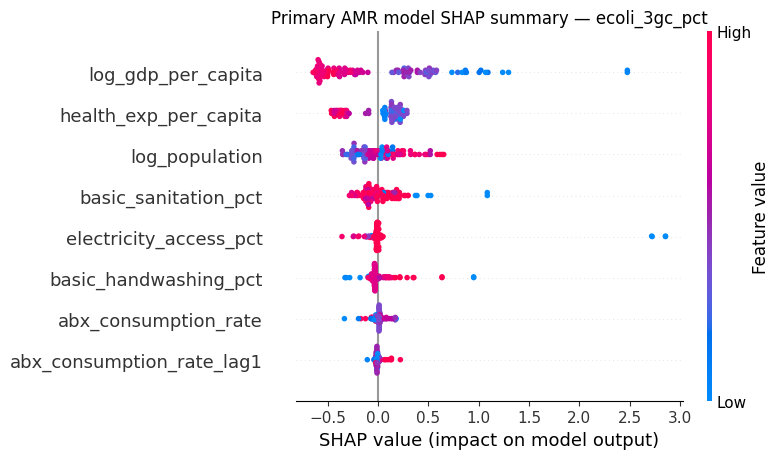

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



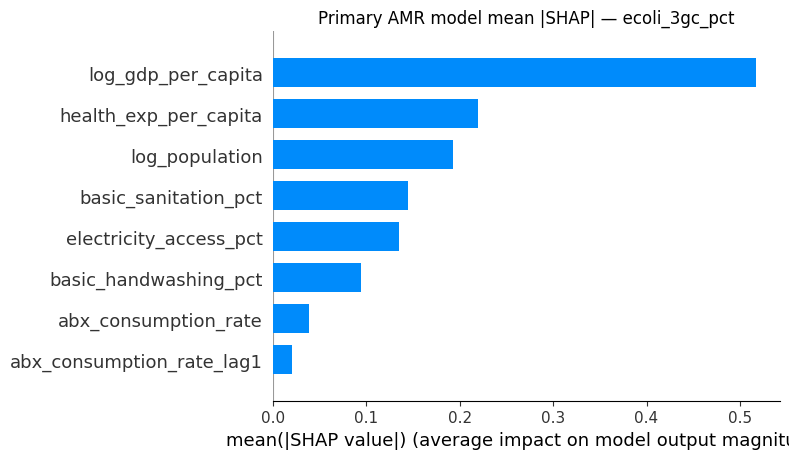

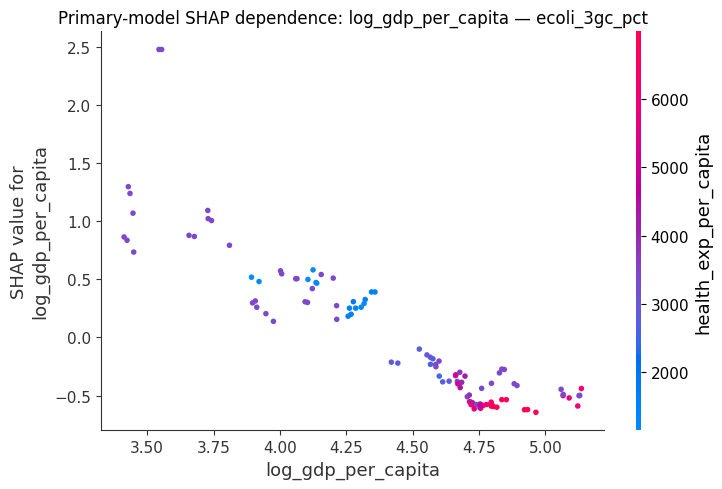

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



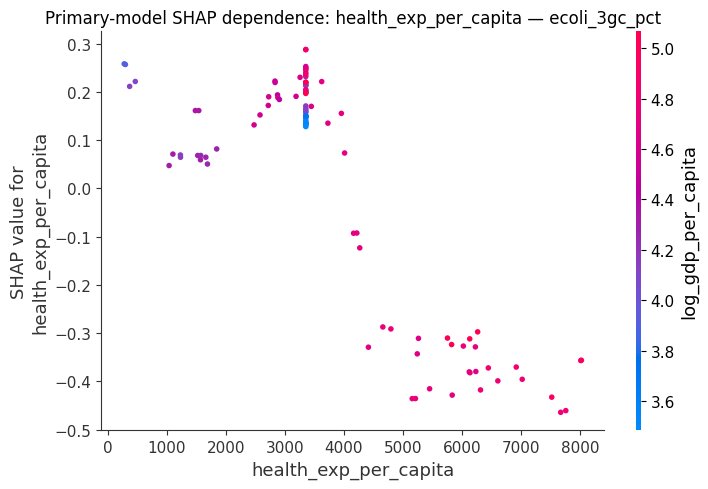

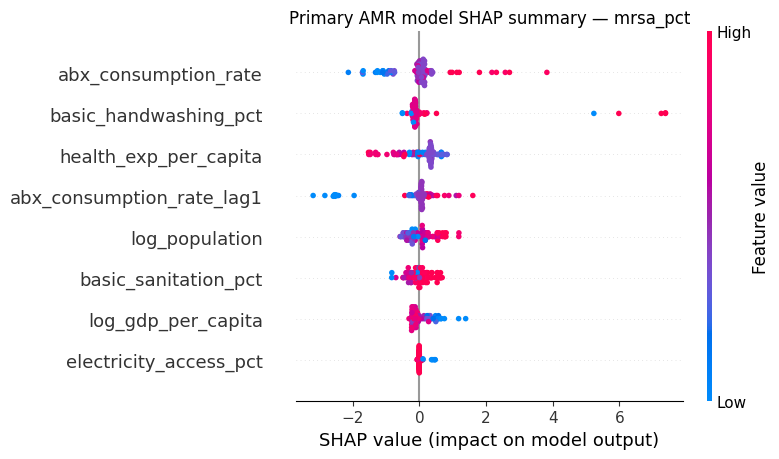

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



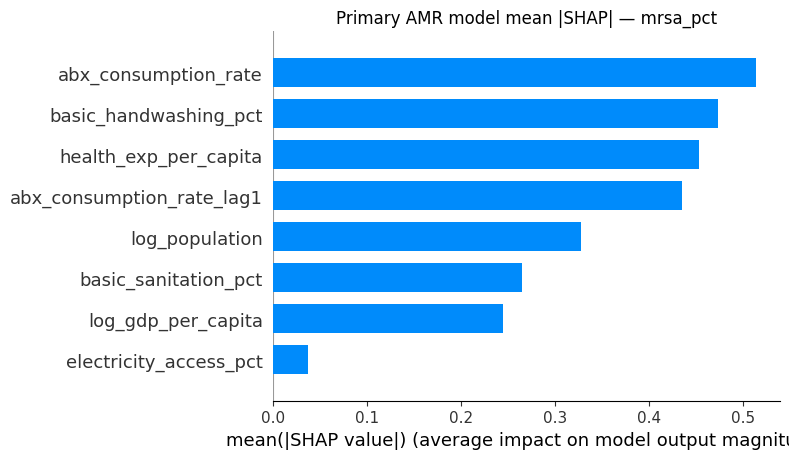

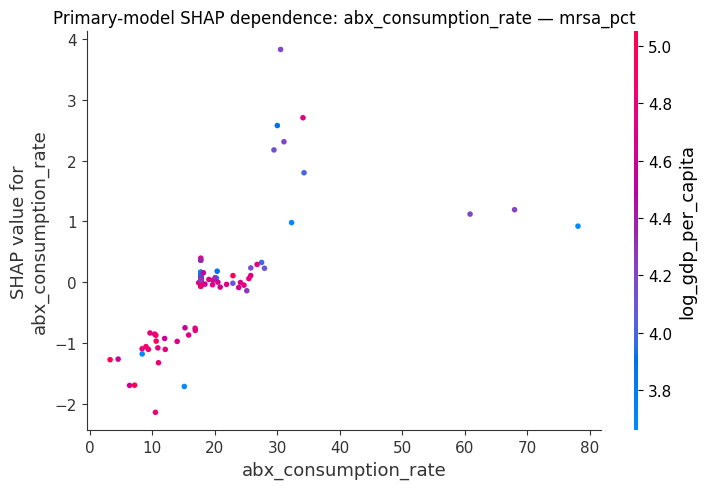

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



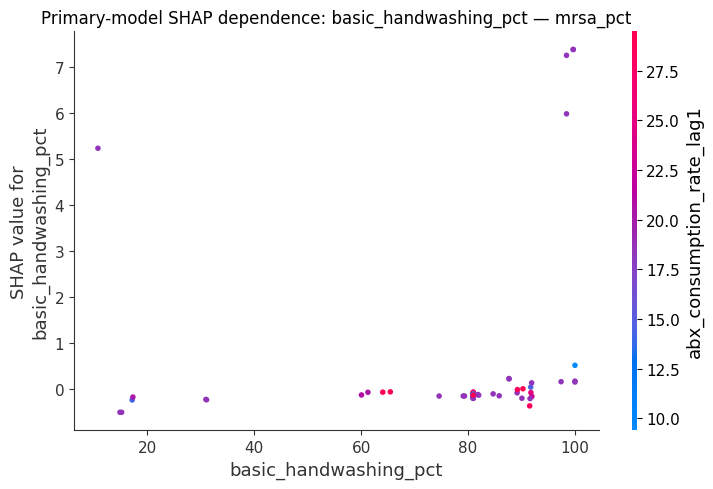

,outcome,feature,mean_abs_shap,mean_signed_shap,model_output_scale
0,ecoli_3gc_pct,log_gdp_per_capita,0.516909,0.008801,logit target scale
1,ecoli_3gc_pct,health_exp_per_capita,0.219690,0.022361,logit target scale
2,ecoli_3gc_pct,log_population,0.193330,0.007737,logit target scale
3,ecoli_3gc_pct,basic_sanitation_pct,0.144514,0.033931,logit target scale
4,ecoli_3gc_pct,electricity_access_pct,0.134973,0.077367,logit target scale
5,ecoli_3gc_pct,basic_handwashing_pct,0.094591,0.018260,logit target scale
6,ecoli_3gc_pct,abx_consumption_rate,0.038704,0.006218,logit target scale
7,ecoli_3gc_pct,abx_consumption_rate_lag1,0.020523,-0.000559,logit target scale
8,mrsa_pct,abx_consumption_rate,0.513742,-0.011761,logit target scale
9,mrsa_pct,basic_handwashing_pct,0.473025,0.203161,logit target scale


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



In [11]:
primary_shap_rows = []

for outcome_name, result in main_results.items():
    model = result["model"]
    X_test = result["X_test"]
    X_sample = X_test.sample(n=min(2000, len(X_test)), random_state=SEED)
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_sample)
    if isinstance(shap_values, list):
        shap_values = shap_values[-1]
    shap_values = np.asarray(shap_values)

    substantive_columns = [column for column in X_sample.columns if not column.endswith("__isna")]
    substantive_indices = [X_sample.columns.get_loc(column) for column in substantive_columns]
    substantive_values = shap_values[:, substantive_indices]

    importance = pd.DataFrame({
        "outcome": outcome_name,
        "feature": substantive_columns,
        "mean_abs_shap": np.abs(substantive_values).mean(axis=0),
        "mean_signed_shap": substantive_values.mean(axis=0),
        "model_output_scale": "logit target scale",
    }).sort_values("mean_abs_shap", ascending=False)
    primary_shap_rows.append(importance)
    importance.to_csv(output_path("xai", f"primary_shap_importance__{outcome_name}.csv"), index=False)

    shap_summary_plot(substantive_values, X_sample[substantive_columns], show=False)
    plt.title(f"Primary AMR model SHAP summary — {outcome_name}")
    plt.tight_layout()
    plt.savefig(output_path("xai", f"primary_shap_beeswarm__{outcome_name}.png"), dpi=300, bbox_inches="tight")
    plt.show()

    shap_summary_plot(substantive_values, X_sample[substantive_columns], plot_type="bar", show=False)
    plt.title(f"Primary AMR model mean |SHAP| — {outcome_name}")
    plt.tight_layout()
    plt.savefig(output_path("xai", f"primary_shap_bar__{outcome_name}.png"), dpi=300, bbox_inches="tight")
    plt.show()

    for feature in importance.head(2)["feature"]:
        feature_index = substantive_columns.index(feature)
        shap.dependence_plot(
            feature_index,
            substantive_values,
            X_sample[substantive_columns],
            feature_names=substantive_columns,
            show=False,
        )
        plt.title(f"Primary-model SHAP dependence: {feature} — {outcome_name}")
        plt.tight_layout()
        plt.savefig(
            output_path("xai", f"primary_shap_dependence__{outcome_name}__{feature}.png"),
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()

primary_shap_summary = pd.concat(primary_shap_rows, ignore_index=True)
display(primary_shap_summary.groupby("outcome").head(10))


## 4. Outcome-record availability model, calibration and SHAP


In [12]:
CALIBRATION_SPLIT_RECORDS = []


def make_reporting_classifier(y_train, seed):
    positives = max(int(np.sum(y_train)), 1)
    negatives = max(int(len(y_train)-positives), 1)
    return xgb.XGBClassifier(n_estimators=600, learning_rate=0.05, max_depth=4,
        min_child_weight=1, subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
        random_state=seed, objective="binary:logistic", eval_metric="logloss",
        scale_pos_weight=negatives/positives, tree_method="hist", n_jobs=N_JOBS)


def make_calibrated_classifier(base_model, X, y, groups, seed, outcome, outer_label):
    splitter = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=seed)
    groups = np.asarray(groups)
    splits = list(splitter.split(X, y, groups))
    for inner, (train_index, calibration_index) in enumerate(splits, start=1):
        train_countries, calibration_countries = set(groups[train_index]), set(groups[calibration_index])
        if train_countries & calibration_countries:
            raise RuntimeError("Country overlap in inner calibration split.")
        if len(np.unique(y[train_index])) != 2 or len(np.unique(y[calibration_index])) != 2:
            raise RuntimeError("Both classes are required in every calibration partition.")
        CALIBRATION_SPLIT_RECORDS.append({"outcome": outcome, "outer_fold": outer_label,
            "inner_fold": inner, "training_countries_json": json.dumps(sorted(train_countries)),
            "calibration_countries_json": json.dumps(sorted(calibration_countries)),
            "n_training": len(train_index), "n_calibration": len(calibration_index)})
    pipeline = Pipeline([("impute", FoldMedianImputer()), ("classifier", base_model)])
    return CalibratedClassifierCV(estimator=pipeline, method="sigmoid", cv=splits,
                                  ensemble=True, n_jobs=1)


def fit_reporting_model(outcome_name):
    selection = selection_panels[outcome_name].copy()
    features = feature_columns_for(selection)
    y = selection["y_observed"].to_numpy(dtype=int)
    groups = selection["iso3"].to_numpy()
    outer_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=cfg.random_seed)
    p_oof = np.full(len(selection), np.nan)
    fold_rows = []
    for fold, (train_index, validation_index) in enumerate(outer_cv.split(selection, y, groups), start=1):
        if set(groups[train_index]) & set(groups[validation_index]):
            raise RuntimeError("Country overlap in outer availability split.")
        fold_train, fold_validation = selection.iloc[train_index], selection.iloc[validation_index]
        X_train, X_validation, _ = build_feature_matrix(fold_train, fold_validation, features, True)
        y_train, y_validation = y[train_index], y[validation_index]
        calibrated = make_calibrated_classifier(
            make_reporting_classifier(y_train, cfg.random_seed+fold), X_train, y_train,
            groups[train_index], cfg.random_seed+fold, outcome_name, fold)
        calibrated.fit(X_train, y_train)
        p_fold = calibrated.predict_proba(X_validation)[:, 1]
        p_oof[validation_index] = p_fold
        fold_rows.append({"outcome": outcome_name, "fold": fold,
            "n_train": len(train_index), "n_validation": len(validation_index),
            "validation_countries": fold_validation["iso3"].nunique(),
            "training_countries_json": json.dumps(sorted(set(groups[train_index]))),
            "validation_countries_json": json.dumps(sorted(set(groups[validation_index]))),
            "observed_validation": int(y_validation.sum()),
            "roc_auc": roc_auc_score(y_validation, p_fold),
            "pr_auc": average_precision_score(y_validation, p_fold),
            "brier": brier_score_loss(y_validation, p_fold)})
    if not np.isfinite(p_oof).all():
        raise RuntimeError(f"Incomplete cross-fitted availability probabilities: {outcome_name}")
    p_oof = np.clip(p_oof, 1e-6, 1-1e-6)
    selection["p_reported_hat"] = p_oof
    prevalence = float(y.mean())
    brier = brier_score_loss(y, p_oof)
    null_brier = brier_score_loss(y, np.repeat(prevalence, len(y)))
    calibration_check = LogisticRegression(C=1e6, solver="lbfgs", max_iter=5000)
    calibration_check.fit(np.log(p_oof/(1-p_oof)).reshape(-1, 1), y)
    summary = {"outcome": outcome_name, "n_country_years": len(selection),
        "n_countries": selection["iso3"].nunique(), "n_observed": int(y.sum()),
        "reporting_prevalence": prevalence,
        "country_cross_fitted_roc_auc": roc_auc_score(y, p_oof),
        "country_cross_fitted_pr_auc": average_precision_score(y, p_oof),
        "brier": brier, "null_brier": null_brier, "brier_skill": 1-brier/null_brier,
        "calibration_intercept": float(calibration_check.intercept_[0]),
        "calibration_slope": float(calibration_check.coef_[0, 0]),
        "p_min": float(p_oof.min()), "p_median": float(np.median(p_oof)),
        "p_max": float(p_oof.max())}
    X_all, _, medians = build_feature_matrix(selection, selection, features, True)
    calibrated_all = make_calibrated_classifier(make_reporting_classifier(y, cfg.random_seed),
        X_all, y, groups, cfg.random_seed, outcome_name, "full_data")
    calibrated_all.fit(X_all, y)
    explain_model = make_reporting_classifier(y, cfg.random_seed)
    explain_model.fit(X_all, y)
    selection.to_csv(output_path("selection", f"reporting_propensity__{outcome_name}.csv"), index=False)
    pd.DataFrame(fold_rows).to_csv(output_path("selection", f"reporting_model_folds__{outcome_name}.csv"), index=False)
    return {"selection": selection, "features": features, "X_all": X_all, "medians": medians,
            "final_calibrated_model": calibrated_all, "explain_model": explain_model,
            "summary": summary, "folds": pd.DataFrame(fold_rows)}


selection_results = {outcome: fit_reporting_model(outcome) for outcome in cfg.outcomes}
selection_summary = pd.DataFrame([result["summary"] for result in selection_results.values()])
selection_summary.to_csv(output_path("selection", "reporting_model_summary.csv"), index=False)
pd.DataFrame(CALIBRATION_SPLIT_RECORDS).to_csv(output_path("selection", "calibration_split_manifest.csv"), index=False)
display(selection_summary.round(4))


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning:

scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning:

scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



,outcome,n_country_years,n_countries,n_observed,reporting_prevalence,country_cross_fitted_roc_auc,country_cross_fitted_pr_auc,brier,null_brier,brier_skill,calibration_intercept,calibration_slope,p_min,p_median,p_max
0,ecoli_3gc_pct,1659,237,413,0.2489,0.7518,0.4837,0.1621,0.1870,0.133,0.3278,1.3389,0.1261,0.1781,0.5892
1,mrsa_pct,1659,237,404,0.2435,0.7830,0.4824,0.1570,0.1842,0.148,0.2174,1.2287,0.1258,0.1716,0.6553


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



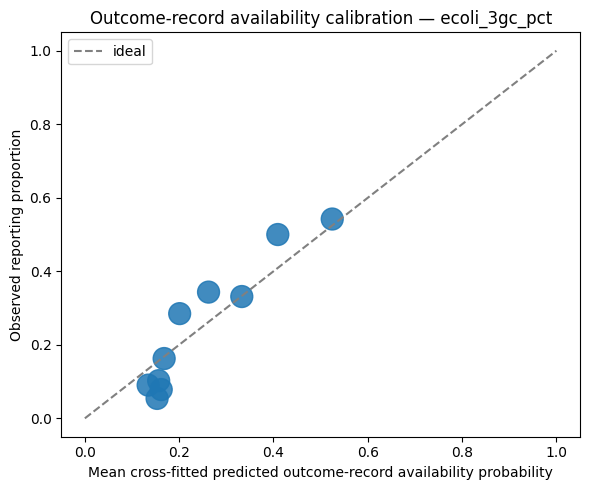

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



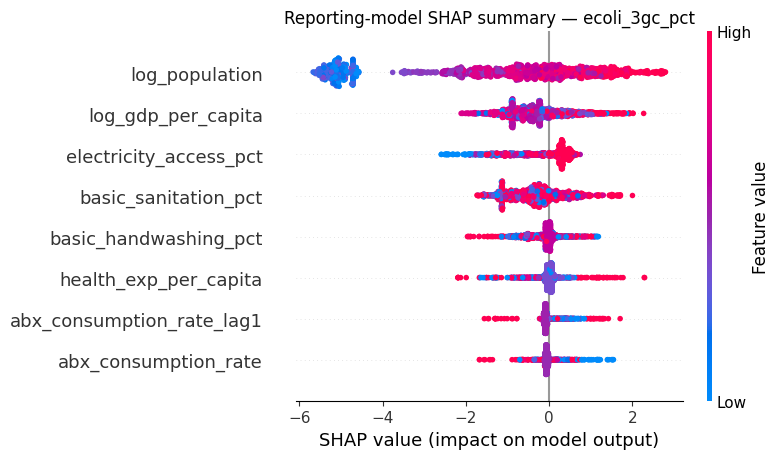

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



Interactive availability map saved as HTML; publication TIFF are generated in Section 9.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



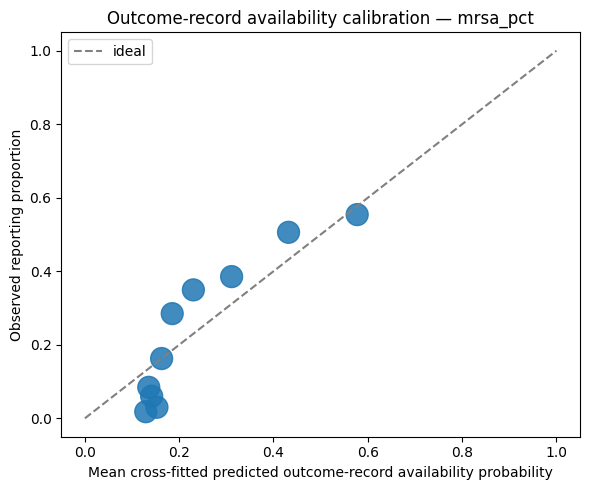

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



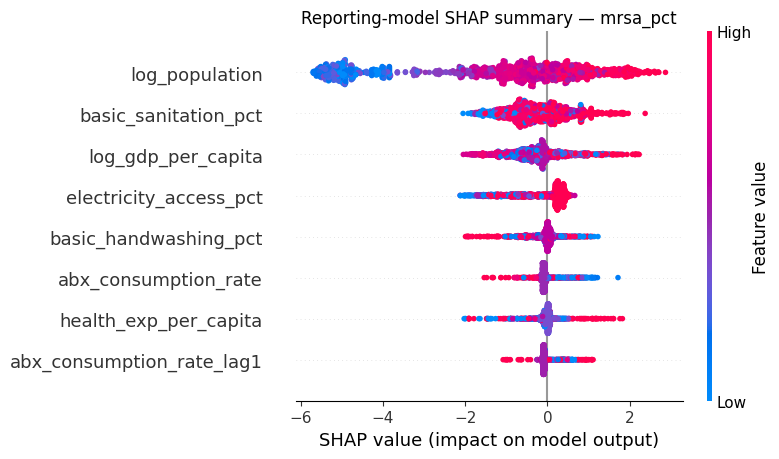

Interactive availability map saved as HTML; publication TIFF are generated in Section 9.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



,outcome,feature,mean_abs_shap,model_output_scale,method
0,ecoli_3gc_pct,log_population,2.082730,XGBoost raw/log-odds scale,TreeSHAP
1,ecoli_3gc_pct,log_gdp_per_capita,0.617443,XGBoost raw/log-odds scale,TreeSHAP
2,ecoli_3gc_pct,electricity_access_pct,0.549271,XGBoost raw/log-odds scale,TreeSHAP
3,ecoli_3gc_pct,basic_sanitation_pct,0.545580,XGBoost raw/log-odds scale,TreeSHAP
4,ecoli_3gc_pct,basic_handwashing_pct,0.251558,XGBoost raw/log-odds scale,TreeSHAP
5,ecoli_3gc_pct,health_exp_per_capita,0.156780,XGBoost raw/log-odds scale,TreeSHAP
6,ecoli_3gc_pct,abx_consumption_rate_lag1,0.143883,XGBoost raw/log-odds scale,TreeSHAP
7,ecoli_3gc_pct,abx_consumption_rate,0.128126,XGBoost raw/log-odds scale,TreeSHAP
8,mrsa_pct,log_population,1.948115,XGBoost raw/log-odds scale,TreeSHAP
9,mrsa_pct,basic_sanitation_pct,0.599966,XGBoost raw/log-odds scale,TreeSHAP


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



In [13]:
reporting_shap_rows = []

for outcome_name, result in selection_results.items():
    selection = result["selection"].copy()
    p = selection["p_reported_hat"]
    y = selection["y_observed"]

    calibration_data = pd.DataFrame({"p": p, "y": y})
    calibration_data["bin"] = pd.qcut(
        calibration_data["p"].rank(method="first"),
        q=10,
        labels=False,
    )
    calibration_table = (
        calibration_data.groupby("bin", as_index=False)
        .agg(n=("y", "size"), mean_predicted=("p", "mean"), observed_rate=("y", "mean"))
    )
    calibration_table.insert(0, "outcome", outcome_name)
    calibration_table.to_csv(output_path("selection", f"propensity_calibration__{outcome_name}.csv"), index=False)

    plt.figure(figsize=(6, 5))
    plt.plot([0, 1], [0, 1], "--", color="grey", label="ideal")
    plt.scatter(
        calibration_table["mean_predicted"],
        calibration_table["observed_rate"],
        s=np.clip(calibration_table["n"] * 1.5, 40, 300),
        alpha=0.85,
    )
    plt.xlabel("Mean cross-fitted predicted outcome-record availability probability")
    plt.ylabel("Observed reporting proportion")
    plt.title(f"Outcome-record availability calibration — {outcome_name}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(output_path("selection", f"propensity_calibration__{outcome_name}.png"), dpi=300, bbox_inches="tight")
    plt.show()

    X_sample = result["X_all"].sample(n=min(2000, len(result["X_all"])), random_state=SEED)
    explainer = shap.TreeExplainer(result["explain_model"])
    shap_values = explainer.shap_values(X_sample)
    if isinstance(shap_values, list):
        shap_values = shap_values[-1]
    shap_values = np.asarray(shap_values)
    substantive_columns = [column for column in X_sample.columns if not column.endswith("__isna")]
    indices = [X_sample.columns.get_loc(column) for column in substantive_columns]
    substantive_values = shap_values[:, indices]
    importance = pd.DataFrame({
        "outcome": outcome_name,
        "feature": substantive_columns,
        "mean_abs_shap": np.abs(substantive_values).mean(axis=0),
        "model_output_scale": "XGBoost raw/log-odds scale",
        "method": "TreeSHAP",
    }).sort_values("mean_abs_shap", ascending=False)
    reporting_shap_rows.append(importance)
    importance.to_csv(output_path("xai", f"reporting_shap_importance__{outcome_name}.csv"), index=False)

    shap_summary_plot(substantive_values, X_sample[substantive_columns], show=False)
    plt.title(f"Reporting-model SHAP summary — {outcome_name}")
    plt.tight_layout()
    plt.savefig(output_path("xai", f"reporting_shap_beeswarm__{outcome_name}.png"), dpi=300, bbox_inches="tight")
    plt.show()

    map_data = selection[selection["year"] == cfg.priority_year].copy()
    map_figure = px.choropleth(
        map_data,
        locations="iso3",
        color="p_reported_hat",
        hover_name="iso3",
        color_continuous_scale="Viridis",
        range_color=[0, 1],
        title=f"Cross-fitted outcome-record availability probability ({cfg.priority_year}) — {outcome_name}",
        labels={"p_reported_hat": "Availability probability"},
    )
    map_figure.write_html(str(output_path("selection", f"propensity_map__{outcome_name}.html")))
    print("Interactive availability map saved as HTML; publication TIFF are generated in Section 9.")
    map_figure.show()

reporting_shap_summary = pd.concat(reporting_shap_rows, ignore_index=True)
display(reporting_shap_summary.groupby("outcome").head(10))


## 5. IPW sensitivity using cross-fitted propensities


In [14]:
ipw_summary_rows = []
ipw_weight_rows = []
ipw_results = {}

for outcome_name in cfg.outcomes:
    main = main_results[outcome_name]
    train = main["train"].copy()
    test = main["test"].copy()
    X_train = main["X_train"]
    X_test = main["X_test"]
    y_train_logit = pct_to_logit(train["y"].to_numpy())
    y_test = test["y"].to_numpy()
    unweighted_prediction = main["predictions"]["y_pred"].to_numpy()

    propensity_lookup = selection_results[outcome_name]["selection"][[
        "iso3", "year", "p_reported_hat"
    ]].copy()
    assert_unique_keys(propensity_lookup, ["iso3", "year"], f"Propensity lookup {outcome_name}")
    train_keys = train[["iso3", "year"]].copy()
    train_keys["_row_order"] = np.arange(len(train_keys))
    train_weights = (
        train_keys.merge(
            propensity_lookup,
            on=["iso3", "year"],
            how="left",
            validate="many_to_one",
        )
        .sort_values("_row_order")
    )
    if train_weights["p_reported_hat"].isna().any():
        raise RuntimeError(f"Missing cross-fitted propensities for {outcome_name} training rows.")

    probability = np.clip(train_weights["p_reported_hat"].to_numpy(), 1e-6, 1 - 1e-6)
    raw_weights = 1.0 / probability
    comparison = test[["iso3", "year", "y"]].rename(columns={"y": "y_true"}).copy()
    comparison["pred_unweighted"] = unweighted_prediction

    for cap in cfg.ipw_caps:
        weights = np.minimum(raw_weights, cap)
        ess = weights.sum() ** 2 / np.square(weights).sum()
        weighted_model = fit_xgb_regressor(cfg.random_seed)
        weighted_model.fit(X_train, y_train_logit, sample_weight=weights)
        weighted_prediction = logit_to_pct(weighted_model.predict(X_test))
        shift = weighted_prediction - unweighted_prediction
        label = int(cap)
        comparison[f"pred_ipw_cap{label}"] = weighted_prediction
        comparison[f"delta_ipw_cap{label}"] = shift
        ipw_summary_rows.append({
            "outcome": outcome_name,
            "weight_cap": cap,
            "n_train": len(train),
            "n_test": len(test),
            "effective_sample_size": ess,
            "pct_weights_capped": 100 * np.mean(raw_weights > cap),
            **{f"unweighted_{key}": value for key, value in regression_metrics(y_test, unweighted_prediction).items()},
            **{f"ipw_{key}": value for key, value in regression_metrics(y_test, weighted_prediction).items()},
            "median_abs_shift_pp": np.median(np.abs(shift)),
            "max_abs_shift_pp": np.max(np.abs(shift)),
        })
        for percentile, value in zip(
            [0, 25, 50, 75, 90, 95, 99, 100],
            np.percentile(weights, [0, 25, 50, 75, 90, 95, 99, 100]),
        ):
            ipw_weight_rows.append({
                "outcome": outcome_name,
                "weight_cap": cap,
                "percentile": percentile,
                "weight": value,
            })

    comparison["pred_weighted_ipw"] = comparison["pred_ipw_cap20"]
    comparison["delta_ipw_minus_unw"] = comparison["delta_ipw_cap20"]
    comparison.to_csv(output_path("ipw", f"ipw_compare_predictions__{outcome_name}.csv"), index=False)
    ipw_results[outcome_name] = comparison

ipw_summary = pd.DataFrame(ipw_summary_rows)
ipw_weight_summary = pd.DataFrame(ipw_weight_rows)
display(ipw_summary.round(4))
ipw_summary.to_csv(output_path("ipw", "ipw_sensitivity_summary.csv"), index=False)
ipw_weight_summary.to_csv(output_path("ipw", "ipw_weight_diagnostics.csv"), index=False)


,outcome,weight_cap,n_train,n_test,effective_sample_size,pct_weights_capped,unweighted_mae_pp,unweighted_rmse_pp,unweighted_r2,ipw_mae_pp,ipw_rmse_pp,ipw_r2,median_abs_shift_pp,max_abs_shift_pp
0,ecoli_3gc_pct,5.0,220,108,194.0769,25.4545,6.7508,10.3155,0.8440,6.4933,9.9241,0.8556,0.6112,12.1160
1,ecoli_3gc_pct,10.0,220,108,181.7867,0.0000,6.7508,10.3155,0.8440,6.4929,9.8456,0.8579,0.6619,11.0858
2,ecoli_3gc_pct,20.0,220,108,181.7867,0.0000,6.7508,10.3155,0.8440,6.4929,9.8456,0.8579,0.6619,11.0858
3,mrsa_pct,5.0,210,103,182.4592,22.3810,12.5776,19.0220,0.3232,12.6878,19.0213,0.3233,0.8064,23.0110
4,mrsa_pct,10.0,210,103,171.9146,0.0000,12.5776,19.0220,0.3232,12.6457,18.6983,0.3460,0.8026,21.0775
5,mrsa_pct,20.0,210,103,171.9146,0.0000,12.5776,19.0220,0.3232,12.6457,18.6983,0.3460,0.8026,21.0775


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



## 6. Aligned conformal uncertainty


In [15]:
def conformal_quantile(scores, alpha: float):
    values = np.asarray(scores, dtype=float)
    values = values[np.isfinite(values)]
    n = len(values)
    if n < 10:
        raise RuntimeError(f"Only {n} finite calibration scores were available.")
    if not 0 < alpha < 1:
        raise ValueError("alpha must be between zero and one")
    rank = int(np.ceil((n + 1) * (1 - alpha)))
    if rank > n:
        return np.inf
    return float(np.sort(values)[rank - 1])


def wilson_interval(successes: int, n: int, z: float = 1.96):
    if n == 0:
        return np.nan, np.nan
    proportion = successes / n
    denominator = 1 + z**2 / n
    centre = (proportion + z**2 / (2 * n)) / denominator
    half_width = z * np.sqrt(proportion * (1 - proportion) / n + z**2 / (4 * n**2)) / denominator
    return centre - half_width, centre + half_width


split_conformal_results = {}
split_conformal_rows = []

for outcome_name in cfg.outcomes:
    data = panel_primary[panel_primary["outcome"] == outcome_name].copy()
    train = data[data["year"] < cfg.conformal_calibration_year].copy()
    calibration = data[data["year"] == cfg.conformal_calibration_year].copy()
    test = data[data["year"] >= cfg.test_year_min].copy()
    if len(train) < 50 or len(calibration) < 20 or len(test) < 20:
        raise RuntimeError(
            f"Conformal temporal split too small for {outcome_name}: "
            f"train={len(train)}, calibration={len(calibration)}, test={len(test)}"
        )

    features = feature_columns_for(data)
    X_train, X_calibration, _ = build_feature_matrix(train, calibration, features, True)
    _, X_test, _ = build_feature_matrix(train, test, features, True)
    model = fit_xgb_regressor(cfg.random_seed)
    model.fit(X_train, pct_to_logit(train["y"].to_numpy()))
    calibration_prediction = logit_to_pct(model.predict(X_calibration))
    test_prediction = logit_to_pct(model.predict(X_test))
    absolute_errors = np.abs(calibration["y"].to_numpy() - calibration_prediction)

    output = test[["iso3", "year", "y"]].rename(columns={"y": "y_true"}).copy()
    output["y_pred"] = test_prediction
    radii = {}

    for alpha in cfg.conformal_alphas:
        nominal = int(round(100 * (1 - alpha)))
        radius = conformal_quantile(absolute_errors, alpha)
        radii[alpha] = radius
        lower = np.clip(test_prediction - radius, 0, 100)
        upper = np.clip(test_prediction + radius, 0, 100)
        covered = (test["y"].to_numpy() >= lower) & (test["y"].to_numpy() <= upper)
        ci_low, ci_high = wilson_interval(int(covered.sum()), len(covered))
        output[f"pi{nominal}_lo"] = lower
        output[f"pi{nominal}_hi"] = upper
        output[f"pi{nominal}_width"] = upper - lower
        split_conformal_rows.append({
            "outcome": outcome_name,
            "nominal_coverage": 1 - alpha,
            "empirical_coverage": covered.mean(),
            "coverage_ci95_low": ci_low,
            "coverage_ci95_high": ci_high,
            "mean_width_pp": np.mean(upper - lower),
            "q_pp": radius,
            "n_train": len(train),
            "n_calibration": len(calibration),
            "n_test": len(test),
        })

    by_year_rows = []
    for year, group in output.groupby("year"):
        covered = (group["y_true"] >= group["pi80_lo"]) & (group["y_true"] <= group["pi80_hi"])
        ci_low, ci_high = wilson_interval(int(covered.sum()), len(group))
        by_year_rows.append({
            "outcome": outcome_name,
            "year": int(year),
            "n": len(group),
            "coverage_80": covered.mean(),
            "coverage_ci95_low": ci_low,
            "coverage_ci95_high": ci_high,
            "mean_width_80_pp": group["pi80_width"].mean(),
        })

    output.to_csv(output_path("uncertainty", f"split_conformal_intervals__{outcome_name}.csv"), index=False)
    pd.DataFrame(by_year_rows).to_csv(output_path("uncertainty", f"split_conformal_by_year__{outcome_name}.csv"), index=False)
    split_conformal_results[outcome_name] = {
        "model": model,
        "train": train,
        "calibration": calibration,
        "test": test,
        "features": features,
        "radii": radii,
        "output": output,
    }

split_conformal_summary = pd.DataFrame(split_conformal_rows)
display(split_conformal_summary.round(4))
split_conformal_summary.to_csv(output_path("uncertainty", "split_conformal_summary.csv"), index=False)


,outcome,nominal_coverage,empirical_coverage,coverage_ci95_low,coverage_ci95_high,mean_width_pp,q_pp,n_train,n_calibration,n_test
0,ecoli_3gc_pct,0.80,0.7778,0.6906,0.8459,24.4350,12.5454,163,57,108
1,ecoli_3gc_pct,0.90,0.9722,0.9215,0.9905,45.7975,25.6918,163,57,108
2,ecoli_3gc_pct,0.95,1.0000,0.9657,1.0000,62.1537,37.4833,163,57,108
3,mrsa_pct,0.80,0.8155,0.7298,0.8786,30.4858,18.0841,156,54,103
4,mrsa_pct,0.90,1.0000,0.9640,1.0000,69.3674,48.2444,156,54,103
5,mrsa_pct,0.95,1.0000,0.9640,1.0000,79.8737,59.6889,156,54,103


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



In [16]:
rolling_rows = []
rolling_outputs = {}

for outcome_name in cfg.outcomes:
    data = panel_primary[panel_primary["outcome"] == outcome_name].copy()
    train = data[data["year"] < cfg.rolling_calibration_year].copy()
    calibration = data[data["year"] == cfg.rolling_calibration_year].copy()
    test = data[data["year"] == cfg.rolling_test_year].copy()
    if len(train) < 50 or len(calibration) < 20 or len(test) < 20:
        raise RuntimeError(
            f"Rolling temporal split too small for {outcome_name}: "
            f"train={len(train)}, calibration={len(calibration)}, test={len(test)}"
        )

    features = feature_columns_for(data)
    X_train, X_calibration, _ = build_feature_matrix(train, calibration, features, True)
    _, X_test, _ = build_feature_matrix(train, test, features, True)
    model = fit_xgb_regressor(cfg.random_seed)
    model.fit(X_train, pct_to_logit(train["y"].to_numpy()))
    calibration_prediction = logit_to_pct(model.predict(X_calibration))
    test_prediction = logit_to_pct(model.predict(X_test))
    radius = conformal_quantile(np.abs(calibration["y"].to_numpy() - calibration_prediction), 0.20)
    lower = np.clip(test_prediction - radius, 0, 100)
    upper = np.clip(test_prediction + radius, 0, 100)
    covered = (test["y"].to_numpy() >= lower) & (test["y"].to_numpy() <= upper)
    ci_low, ci_high = wilson_interval(int(covered.sum()), len(covered))
    rolling_rows.append({
        "outcome": outcome_name,
        "calibration_year": cfg.rolling_calibration_year,
        "test_year": cfg.rolling_test_year,
        "nominal_coverage": 0.80,
        "empirical_coverage": covered.mean(),
        "coverage_ci95_low": ci_low,
        "coverage_ci95_high": ci_high,
        "mean_width_pp": np.mean(upper - lower),
        "q_pp": radius,
        "n_train": len(train),
        "n_calibration": len(calibration),
        "n_test": len(test),
        **regression_metrics(test["y"].to_numpy(), test_prediction),
    })
    output = test[["iso3", "year", "y"]].rename(columns={"y": "y_true"}).copy()
    output["y_pred"] = test_prediction
    output["pi80_lo"] = lower
    output["pi80_hi"] = upper
    output["pi80_width"] = upper - lower
    output.to_csv(output_path("uncertainty", f"rolling_conformal_intervals__{outcome_name}.csv"), index=False)
    rolling_outputs[outcome_name] = output

rolling_summary = pd.DataFrame(rolling_rows)
display(rolling_summary.round(4))
rolling_summary.to_csv(output_path("uncertainty", "rolling_conformal_summary.csv"), index=False)


,outcome,calibration_year,test_year,nominal_coverage,empirical_coverage,coverage_ci95_low,coverage_ci95_high,mean_width_pp,q_pp,n_train,n_calibration,n_test,mae_pp,rmse_pp,r2
0,ecoli_3gc_pct,2021,2022,0.8,0.7091,0.5786,0.8123,21.0835,10.8569,220,53,55,7.8054,11.6697,0.8137
1,mrsa_pct,2021,2022,0.8,0.6667,0.5297,0.7803,24.7526,14.4285,210,52,51,14.2981,20.4474,0.1934


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



### 6.1 Conformalised quantile regression for observation-specific interval width


In [17]:
def fit_cqr(outcome_name: str):
    data = panel_primary[panel_primary["outcome"] == outcome_name].copy()
    train = data[data["year"] < cfg.conformal_calibration_year].copy()
    calibration = data[data["year"] == cfg.conformal_calibration_year].copy()
    test = data[data["year"] >= cfg.test_year_min].copy()
    features = feature_columns_for(data)
    X_train, X_calibration, _ = build_feature_matrix(train, calibration, features, True)
    _, X_test, _ = build_feature_matrix(train, test, features, True)

    lower_model = GradientBoostingRegressor(
        loss="quantile", alpha=0.10, n_estimators=500, learning_rate=0.03,
        max_depth=3, min_samples_leaf=5, random_state=cfg.random_seed,
    )
    upper_model = GradientBoostingRegressor(
        loss="quantile", alpha=0.90, n_estimators=500, learning_rate=0.03,
        max_depth=3, min_samples_leaf=5, random_state=cfg.random_seed,
    )
    lower_model.fit(X_train, train["y"].to_numpy())
    upper_model.fit(X_train, train["y"].to_numpy())

    calibration_lower_raw = lower_model.predict(X_calibration)
    calibration_upper_raw = upper_model.predict(X_calibration)
    calibration_lower = np.minimum(calibration_lower_raw, calibration_upper_raw)
    calibration_upper = np.maximum(calibration_lower_raw, calibration_upper_raw)
    scores = np.maximum(
        calibration_lower - calibration["y"].to_numpy(),
        calibration["y"].to_numpy() - calibration_upper,
    )

    adjustment = max(0.0, conformal_quantile(scores, 0.20))

    test_lower_raw = lower_model.predict(X_test)
    test_upper_raw = upper_model.predict(X_test)
    lower = np.clip(np.minimum(test_lower_raw, test_upper_raw) - adjustment, 0, 100)
    upper = np.clip(np.maximum(test_lower_raw, test_upper_raw) + adjustment, 0, 100)
    covered = (test["y"].to_numpy() >= lower) & (test["y"].to_numpy() <= upper)
    ci_low, ci_high = wilson_interval(int(covered.sum()), len(covered))

    output = test[["iso3", "year", "y"]].rename(columns={"y": "y_true"}).copy()
    output["cqr80_lo"] = lower
    output["cqr80_hi"] = upper
    output["cqr80_width"] = upper - lower
    output["covered80"] = covered.astype(int)
    output.to_csv(output_path("uncertainty", f"cqr_intervals__{outcome_name}.csv"), index=False)

    summary = {
        "outcome": outcome_name,
        "nominal_coverage": 0.80,
        "empirical_coverage": covered.mean(),
        "coverage_ci95_low": ci_low,
        "coverage_ci95_high": ci_high,
        "mean_width_pp": np.mean(upper - lower),
        "median_width_pp": np.median(upper - lower),
        "width_sd_pp": np.std(upper - lower),
        "conformal_adjustment_pp": adjustment,
        "n_train": len(train),
        "n_calibration": len(calibration),
        "n_test": len(test),
    }
    return {
        "lower_model": lower_model,
        "upper_model": upper_model,
        "adjustment": adjustment,
        "train": train,
        "features": features,
        "output": output,
        "summary": summary,
    }


cqr_results = {outcome: fit_cqr(outcome) for outcome in cfg.outcomes}
cqr_summary = pd.DataFrame([result["summary"] for result in cqr_results.values()])
display(cqr_summary.round(4))
cqr_summary.to_csv(output_path("uncertainty", "cqr_summary.csv"), index=False)


,outcome,nominal_coverage,empirical_coverage,coverage_ci95_low,coverage_ci95_high,mean_width_pp,median_width_pp,width_sd_pp,conformal_adjustment_pp,n_train,n_calibration,n_test
0,ecoli_3gc_pct,0.8,0.7963,0.7108,0.8615,31.9057,33.3673,15.6808,4.0304,163,57,108
1,mrsa_pct,0.8,0.8835,0.8073,0.9321,37.9996,34.2273,15.6364,7.9389,156,54,103


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



## 7. Exploratory audit-priority index and validation


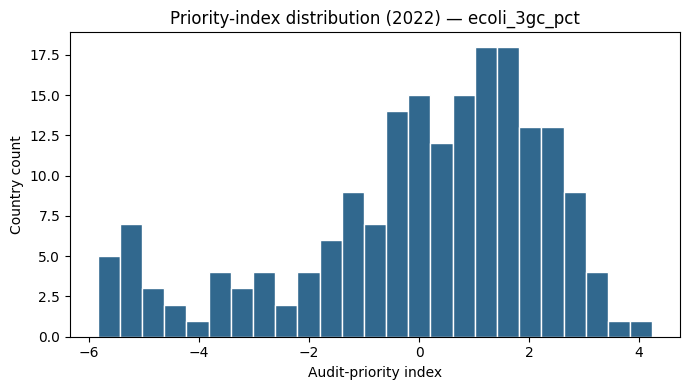

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



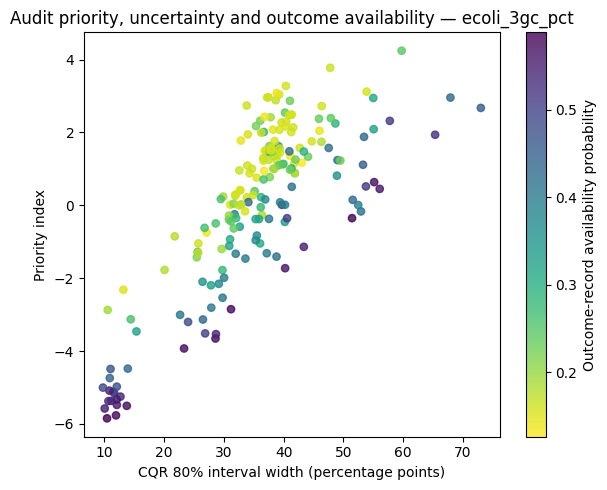

Interactive priority map saved as HTML; publication TIFF are generated in Section 9.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



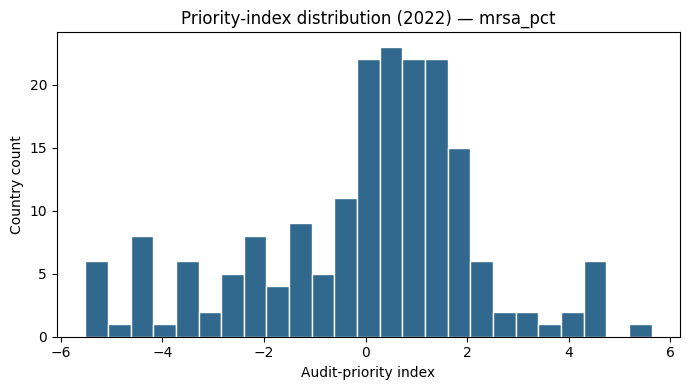

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



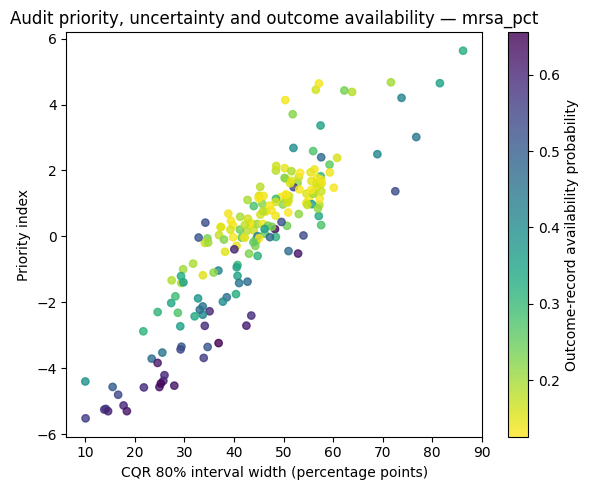

Interactive priority map saved as HTML; publication TIFF are generated in Section 9.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



,outcome,year,eligible_rows,scorable_rows,unscorable_rows,observed_scorable_rows,missing_scorable_rows,priority_min,priority_mean,priority_max,mean_interval_width_pp,interval_width_sd_pp
0,ecoli_3gc_pct,2022,237,190,47,83,107,-5.8455,-0.0,4.2430,35.3723,11.6231
1,mrsa_pct,2022,237,190,47,84,106,-5.5175,-0.0,5.6328,44.1733,13.0729


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



,outcome,year,n_observed,need_cases,top20pct_need_recall_priority,top20pct_need_recall_risk_only,spearman_priority_with_realized_resistance,spearman_priority_with_absolute_error
0,ecoli_3gc_pct,2022,83,34,0.4118,0.4412,0.7474,0.5608
1,mrsa_pct,2022,84,31,0.4194,0.4839,0.6881,0.4434


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



,outcome,scheme,spearman_with_equal_rank,top10_overlap_n,top10_jaccard
0,ecoli_3gc_pct,equal_1_1_1,1.0000,10,1.0000
1,ecoli_3gc_pct,risk_2_1_1,0.9841,7,0.5385
2,ecoli_3gc_pct,uncertainty_1_2_1,0.9709,6,0.4286
3,ecoli_3gc_pct,reporting_1_1_2,0.9430,8,0.6667
4,mrsa_pct,equal_1_1_1,1.0000,10,1.0000
5,mrsa_pct,risk_2_1_1,0.9505,10,1.0000
6,mrsa_pct,uncertainty_1_2_1,0.9846,9,0.8182
7,mrsa_pct,reporting_1_1_2,0.9569,10,1.0000


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



In [18]:
def zscore(series: pd.Series):
    numeric = pd.to_numeric(series, errors="coerce")
    standard_deviation = numeric.std(ddof=0)
    if not np.isfinite(standard_deviation) or standard_deviation < 1e-12:
        return pd.Series(np.zeros(len(numeric)), index=numeric.index)
    return (numeric - numeric.mean()) / standard_deviation


def top_fraction_recall(dataframe, score_column, target_column, fraction=0.20):
    if len(dataframe) == 0 or dataframe[target_column].sum() == 0:
        return np.nan
    n_selected = max(1, int(np.ceil(fraction * len(dataframe))))
    selected = dataframe.nlargest(n_selected, score_column)
    return selected[target_column].sum() / dataframe[target_column].sum()


priority_panels = {}
priority_summary_rows = []
priority_validation_rows = []
rank_sensitivity_rows = []

for outcome_name in cfg.outcomes:
    scoring = selection_results[outcome_name]["selection"].copy()
    scoring = scoring[scoring["year"] == cfg.priority_year].copy()
    features = feature_columns_for(scoring)
    scoring["n_predictors_available"] = scoring[features].notna().sum(axis=1)
    scoring["scorable"] = (
        scoring["n_predictors_available"] >= cfg.minimum_available_priority_features
    )

    scorable = scoring[scoring["scorable"]].copy()
    main = main_results[outcome_name]
    _, X_score, _ = build_feature_matrix(main["train"], scorable, main["features"], True)
    scorable["y_pred"] = logit_to_pct(main["model"].predict(X_score))

    cqr = cqr_results[outcome_name]
    _, X_cqr_score, _ = build_feature_matrix(cqr["train"], scorable, cqr["features"], True)
    lower_raw = cqr["lower_model"].predict(X_cqr_score)
    upper_raw = cqr["upper_model"].predict(X_cqr_score)
    scorable["pi80_lo"] = np.clip(
        np.minimum(lower_raw, upper_raw) - cqr["adjustment"], 0, 100
    )
    scorable["pi80_hi"] = np.clip(
        np.maximum(lower_raw, upper_raw) + cqr["adjustment"], 0, 100
    )
    scorable["pi80_width"] = scorable["pi80_hi"] - scorable["pi80_lo"]

    observed_values = panel_all_observed[
        (panel_all_observed["outcome"] == outcome_name)
        & (panel_all_observed["year"] == cfg.priority_year)
    ][["iso3", "year", "y"]]
    scorable = scorable.merge(
        observed_values,
        on=["iso3", "year"],
        how="left",
        validate="one_to_one",
    )
    scorable["z_risk"] = zscore(scorable["y_pred"])
    scorable["z_uncertainty"] = zscore(scorable["pi80_width"])
    scorable["z_reporting"] = zscore(scorable["p_reported_hat"])
    scorable["priority_index"] = (
        scorable["z_risk"] + scorable["z_uncertainty"] - scorable["z_reporting"]
    )
    scorable["priority_rank"] = scorable["priority_index"].rank(ascending=False, method="min").astype(int)
    scorable["reporting_gap"] = 1 - scorable["p_reported_hat"]

    weight_schemes = {
        "equal_1_1_1": (1.0, 1.0, 1.0),
        "risk_2_1_1": (2.0, 1.0, 1.0),
        "uncertainty_1_2_1": (1.0, 2.0, 1.0),
        "reporting_1_1_2": (1.0, 1.0, 2.0),
    }
    baseline_rank = scorable["priority_rank"]
    baseline_top10 = set(scorable.nsmallest(min(10, len(scorable)), "priority_rank")["iso3"])
    for scheme, (risk_weight, uncertainty_weight, reporting_weight) in weight_schemes.items():
        score_column = f"priority__{scheme}"
        rank_column = f"rank__{scheme}"
        scorable[score_column] = (
            risk_weight * scorable["z_risk"]
            + uncertainty_weight * scorable["z_uncertainty"]
            - reporting_weight * scorable["z_reporting"]
        )
        scorable[rank_column] = scorable[score_column].rank(ascending=False, method="min")
        top10 = set(scorable.nsmallest(min(10, len(scorable)), rank_column)["iso3"])
        rank_sensitivity_rows.append({
            "outcome": outcome_name,
            "scheme": scheme,
            "spearman_with_equal_rank": baseline_rank.corr(scorable[rank_column], method="spearman"),
            "top10_overlap_n": len(baseline_top10 & top10),
            "top10_jaccard": len(baseline_top10 & top10) / max(len(baseline_top10 | top10), 1),
        })

    observed = scorable.dropna(subset=["y"]).copy()
    if len(observed) >= 10:
        observed["absolute_error"] = np.abs(observed["y"] - observed["y_pred"])
        observed["high_resistance"] = (
            observed["y"] >= observed["y"].quantile(0.75)
        ).astype(int)
        observed["large_error"] = (
            observed["absolute_error"] >= observed["absolute_error"].quantile(0.75)
        ).astype(int)
        observed["surveillance_need"] = (
            (observed["high_resistance"] == 1) | (observed["large_error"] == 1)
        ).astype(int)
        priority_validation_rows.append({
            "outcome": outcome_name,
            "year": cfg.priority_year,
            "n_observed": len(observed),
            "need_cases": int(observed["surveillance_need"].sum()),
            "top20pct_need_recall_priority": top_fraction_recall(
                observed, "priority_index", "surveillance_need", 0.20
            ),
            "top20pct_need_recall_risk_only": top_fraction_recall(
                observed, "y_pred", "surveillance_need", 0.20
            ),
            "spearman_priority_with_realized_resistance": observed["priority_index"].corr(
                observed["y"], method="spearman"
            ),
            "spearman_priority_with_absolute_error": observed["priority_index"].corr(
                observed["absolute_error"], method="spearman"
            ),
        })

    missing = scorable[scorable["y_observed"] == 0].sort_values("priority_index", ascending=False)
    missing.head(20).to_csv(
        output_path("priority", f"top20_missing_{cfg.priority_year}__{outcome_name}.csv"),
        index=False,
    )
    scorable.to_csv(output_path("priority", f"priority_panel_{cfg.priority_year}__{outcome_name}.csv"), index=False)

    plt.figure(figsize=(7, 4))
    plt.hist(scorable["priority_index"], bins=25, color="#31688e", edgecolor="white")
    plt.xlabel("Audit-priority index")
    plt.ylabel("Country count")
    plt.title(f"Priority-index distribution ({cfg.priority_year}) — {outcome_name}")
    plt.tight_layout()
    plt.savefig(
        output_path("priority", f"priority_distribution__{outcome_name}.png"),
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

    plt.figure(figsize=(6, 5))
    plt.scatter(
        scorable["pi80_width"],
        scorable["priority_index"],
        c=scorable["p_reported_hat"],
        cmap="viridis_r",
        s=28,
        alpha=0.8,
    )
    plt.colorbar(label="Outcome-record availability probability")
    plt.xlabel("CQR 80% interval width (percentage points)")
    plt.ylabel("Priority index")
    plt.title(f"Audit priority, uncertainty and outcome availability — {outcome_name}")
    plt.tight_layout()
    plt.savefig(
        output_path("priority", f"priority_uncertainty_diagnostic__{outcome_name}.png"),
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

    priority_map = px.choropleth(
        scorable,
        locations="iso3",
        color="priority_index",
        hover_name="iso3",
        color_continuous_scale="RdYlBu_r",
        title=f"Exploratory audit-priority index ({cfg.priority_year}) — {outcome_name}",
        labels={"priority_index": "Priority index"},
    )
    priority_map.write_html(str(output_path("priority", f"priority_map__{outcome_name}.html")))
    print("Interactive priority map saved as HTML; publication TIFF are generated in Section 9.")
    priority_map.show()

    priority_panels[outcome_name] = scorable
    priority_summary_rows.append({
        "outcome": outcome_name,
        "year": cfg.priority_year,
        "eligible_rows": len(scoring),
        "scorable_rows": len(scorable),
        "unscorable_rows": int((~scoring["scorable"]).sum()),
        "observed_scorable_rows": int(scorable["y_observed"].sum()),
        "missing_scorable_rows": int((scorable["y_observed"] == 0).sum()),
        "priority_min": scorable["priority_index"].min(),
        "priority_mean": scorable["priority_index"].mean(),
        "priority_max": scorable["priority_index"].max(),
        "mean_interval_width_pp": scorable["pi80_width"].mean(),
        "interval_width_sd_pp": scorable["pi80_width"].std(ddof=0),
    })

priority_summary = pd.DataFrame(priority_summary_rows)
priority_validation = pd.DataFrame(priority_validation_rows)
rank_sensitivity = pd.DataFrame(rank_sensitivity_rows)
display(priority_summary.round(4))
display(priority_validation.round(4))
display(rank_sensitivity.round(4))
priority_summary.to_csv(output_path("priority", "priority_summary.csv"), index=False)
priority_validation.to_csv(output_path("priority", "priority_retrospective_validation.csv"), index=False)
rank_sensitivity.to_csv(output_path("priority", "priority_weight_sensitivity.csv"), index=False)


## 8. Additional validation and sensitivity analyses

The primary cohort and temporal split are defined above. The analyses below use one
aligned set of held-out predictions. Caches are accepted only when their data,
code, environment, content hash and table structure match the current analysis.
Each resampling group is checked separately before it is used.


In [19]:
from collections import Counter
from itertools import product
from sklearn.model_selection import ParameterGrid


@dataclass(frozen=True)
class RevisionConfig:
    metric_bootstrap_replicates: int = 10_000
    conformal_bootstrap_replicates: int = 10_000
    shap_bootstrap_replicates: int = 100
    geographic_runs: int = 30
    shap_checkpoint_every: int = 5
    random_seed: int = 20260904
    force_recompute: bool = False
    run_history_augmented_sensitivity: bool = True


REVISION_CODE_VERSION = ANALYSIS_VERSION
PUBLICATION_ARTIFACT_VERSION = ANALYSIS_VERSION
ANALYSIS_SOURCE_SHA256 = "6d5d7b4aabaaf9a4fd64b6b65e0f817957b1b4ab8cbb743c1e69b48d69e67692"
EXECUTION_ENVIRONMENT = {
    "python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
    "scikit_learn": importlib_metadata.version("scikit-learn"),
    "xgboost": xgb.__version__, "shap": shap.__version__,
    "model_threads": N_JOBS,
}
rev_cfg = RevisionConfig()
default_cache_base = (Path("/content/drive/MyDrive/AMR_analysis_cache")
                      if Path("/content/drive/MyDrive").exists()
                      else Path("AMR_analysis_cache"))
REV_CACHE_BASE = Path(os.environ.get("AMR_REVISION_CACHE_DIR", str(default_cache_base)))
REV_ROOT = REV_CACHE_BASE / ANALYSIS_VERSION
REV_DIRS = {key: REV_ROOT / folder for key, folder in {
    "predictions": "01_predictions", "bootstrap": "02_cluster_bootstrap",
    "selection": "03_selection_sensitivity", "geography": "04_geographic_transportability",
    "conformal": "05_conformal_dependence", "shap": "06_shap_stability",
    "xgb": "07_xgb_sensitivity", "history": "08_history_sensitivity",
    "figures": "09_publication_figures", "verification": "10_verification",
}.items()}
for directory in REV_DIRS.values():
    directory.mkdir(parents=True, exist_ok=True)


def stable_json(value):
    return json.dumps(value, sort_keys=True, separators=(",", ":"), default=str)


def frame_fingerprint(dataframe, columns=None, sort_by=None):
    frame = dataframe.copy()
    if columns is not None:
        frame = frame.loc[:, columns]
    if sort_by:
        frame = frame.sort_values(sort_by).reset_index(drop=True)
    return hashlib.sha256(pd.util.hash_pandas_object(frame, index=True).values.tobytes()).hexdigest()


PACKAGE_LOCK_TEXT = "".join(sorted(
    f"{(item.metadata.get('Name') or 'UNKNOWN').strip()}=={item.version}\n"
    for item in importlib_metadata.distributions()
))
PACKAGE_LOCK_SHA256 = hashlib.sha256(PACKAGE_LOCK_TEXT.encode()).hexdigest()
CACHE_EVENTS = []
LEGACY_CACHE_HITS = []


def analysis_signature(label, extra=None):
    revision_parameters = asdict(rev_cfg)
    revision_parameters.pop("force_recompute", None)
    revision_parameters.pop("shap_checkpoint_every", None)
    main_parameters = asdict(cfg)
    main_parameters.pop("outputs_dir", None)
    main_parameters.pop("data_raw_dir", None)
    payload = {
        "label": label, "analysis_version": ANALYSIS_VERSION,
        "source_sha256": ANALYSIS_SOURCE_SHA256, "package_lock_sha256": PACKAGE_LOCK_SHA256,
        "execution_environment": EXECUTION_ENVIRONMENT, "main_config": main_parameters,
        "revision_config": revision_parameters,
        "primary_panel": frame_fingerprint(panel_primary, sort_by=["outcome", "iso3", "year"]),
        "all_observed_panel": frame_fingerprint(panel_all_observed, sort_by=["outcome", "iso3", "year"]),
        "sources": {record["variable_key"]: record["sha256"] for record in SOURCE_REGISTRY.values()},
        "extra": extra or {},
    }
    return hashlib.sha256(stable_json(payload).encode()).hexdigest()


def artifact_signature(label, extra=None):
    return analysis_signature(label, extra)


def meta_path(path):
    path = Path(path)
    return path.with_suffix(path.suffix + ".meta.json")


def atomic_text(path, text):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile("w", encoding="utf-8", dir=path.parent,
                                     prefix=path.name + ".", suffix=".tmp", delete=False) as handle:
        temporary = Path(handle.name)
        handle.write(text)
        handle.flush()
        os.fsync(handle.fileno())
    os.replace(temporary, path)


def save_frame(dataframe, path, signature, metadata=None):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile("w", encoding="utf-8", dir=path.parent,
                                     prefix=path.name + ".", suffix=".tmp", delete=False) as handle:
        temporary = Path(handle.name)
        dataframe.to_csv(handle, index=False)
        handle.flush()
        os.fsync(handle.fileno())
    digest = sha256_file(temporary)
    os.replace(temporary, path)
    record = {"signature": signature, "sha256": digest, "rows": int(len(dataframe)),
              "columns": list(dataframe.columns), "generated_utc": datetime.now(timezone.utc).isoformat(),
              **(metadata or {})}
    atomic_text(meta_path(path), json.dumps(record, indent=2, default=str))


def cache_matches(path, signature):
    path = Path(path)
    try:
        if rev_cfg.force_recompute or not path.is_file() or not meta_path(path).is_file():
            return False
        record = json.loads(meta_path(path).read_text(encoding="utf-8"))
        if record.get("signature") != signature:
            return False
        if record.get("sha256") != sha256_file(path):
            raise ValueError("file hash differs from cache metadata")
        frame = pd.read_csv(path, low_memory=False)
        if len(frame) != record.get("rows") or list(frame.columns) != record.get("columns"):
            raise ValueError("cache row count or columns differ from metadata")
        return True
    except (OSError, ValueError, KeyError, pd.errors.ParserError, pd.errors.EmptyDataError) as exc:
        CACHE_EVENTS.append({"path": str(path), "event": "rejected", "reason": str(exc)})
        return False


def complete_replicates(group, expected, value_columns):
    if len(group) != expected or "replicate" not in group:
        return False
    ids = pd.to_numeric(group["replicate"], errors="coerce")
    if ids.isna().any() or set(ids.tolist()) != set(range(expected)):
        return False
    numeric = group.reindex(columns=value_columns).apply(pd.to_numeric, errors="coerce")
    return bool(np.isfinite(numeric.to_numpy()).all())


def assert_group_replicates(frame, group_columns, expected_keys, expected, value_columns):
    expected_keys = {tuple(key) for key in expected_keys}
    actual = {key if isinstance(key, tuple) else (key,): group
              for key, group in frame.groupby(group_columns, dropna=False)}
    problems = []
    if set(actual) != expected_keys:
        problems.append(f"missing={sorted(expected_keys - set(actual))}, extra={sorted(set(actual) - expected_keys)}")
    for key, group in actual.items():
        if not complete_replicates(group, expected, value_columns):
            problems.append(f"{key}: {len(group)} rows; expected {expected} unique finite replicates")
    if problems:
        raise RuntimeError("Incomplete resampling results: " + "; ".join(problems))
    return True


def cluster_bootstrap_totals(frame, columns, n_replicates, seed):
    """Resample complete countries and return sums for each requested column."""
    totals = frame.groupby("iso3", sort=True)[columns].sum().to_numpy(dtype=float)
    counts = frame.groupby("iso3", sort=True).size().to_numpy(dtype=float)
    rng = np.random.default_rng(seed)
    n_countries = len(counts)
    numerator = np.empty((n_replicates, len(columns)))
    denominator = np.empty(n_replicates)
    for start in range(0, n_replicates, 1000):
        stop = min(start + 1000, n_replicates)
        draws = rng.choice(n_countries, size=(stop-start, n_countries), replace=True)
        numerator[start:stop] = totals[draws].sum(axis=1)
        denominator[start:stop] = counts[draws].sum(axis=1)
    return numerator, denominator


def safe_r2(y_true, prediction):
    y_true, prediction = np.asarray(y_true, dtype=float), np.asarray(prediction, dtype=float)
    if len(y_true) < 2 or np.var(y_true) <= 0:
        return np.nan
    return float(r2_score(y_true, prediction))


def metric_triplet(y_true, prediction):
    return {"mae_pp": float(mean_absolute_error(y_true, prediction)),
            "rmse_pp": float(mean_squared_error(y_true, prediction) ** 0.5),
            "r2": safe_r2(y_true, prediction)}


print("Cache version:", ANALYSIS_VERSION)
print("Analysis source SHA-256:", ANALYSIS_SOURCE_SHA256)
print("Package inventory SHA-256:", PACKAGE_LOCK_SHA256)
print("Cache directory:", REV_ROOT.resolve())


Cache version: 4.0.0
Analysis source SHA-256: 6d5d7b4aabaaf9a4fd64b6b65e0f817957b1b4ab8cbb743c1e69b48d69e67692
Package inventory SHA-256: 2c7bd18e46701602e718f7287e3839ec7c799716aed26a1aa5a19455ecc8fb5b
Cache directory: /content/AMR_analysis_cache/4.0.0


### 8.1 Aligned held-out predictions

All comparators use the same training rows. Persistence is frozen at the latest
pre-2021 country value for both test years. The primary XGBoost predictions from
Section 3 are reused.


In [20]:
MODEL_COLUMNS = {
    "XGBoost": "pred_xgboost",
    "L2_regularised_linear": "pred_l2_linear",
    "Last_country_value": "pred_last_country_value",
    "Training_mean": "pred_training_mean",
}


def authoritative_primary_xgb_prediction(outcome_name, test):
    reference = main_results[outcome_name]["predictions"][
        ["iso3", "year", "y_pred"]
    ].rename(columns={"y_pred": "authoritative_xgb_prediction"})
    aligned = test[["iso3", "year"]].merge(
        reference,
        on=["iso3", "year"],
        how="left",
        validate="one_to_one",
        sort=False,
    )
    if aligned["authoritative_xgb_prediction"].isna().any():
        raise RuntimeError(f"Primary XGBoost predictions could not be aligned for {outcome_name}.")
    return aligned["authoritative_xgb_prediction"].to_numpy()


def fit_point_bundle(dataframe, outcome_name, cohort_label):
    data = dataframe[dataframe["outcome"] == outcome_name].copy()
    data = data.sort_values(["iso3", "year"]).reset_index(drop=True)
    train, test = temporal_split(data, cfg.test_year_min)
    features = feature_columns_for(data)
    X_train, X_test, medians = build_feature_matrix(train, test, features, True)
    y_train_logit = pct_to_logit(train["y"].to_numpy())

    if cohort_label == "primary_four_year":
        pred_xgb = authoritative_primary_xgb_prediction(outcome_name, test)
        xgb_source = "reused_authoritative_section_3_predictions"
    else:
        xgb_model = fit_xgb_regressor(cfg.random_seed)
        xgb_model.fit(X_train, y_train_logit)
        pred_xgb = logit_to_pct(xgb_model.predict(X_test))
        xgb_source = "separate_unrestricted_sensitivity_fit"

    ridge_search = tune_l2_linear(
        X_train,
        y_train_logit,
        train["iso3"].to_numpy(),
    )
    pred_l2 = logit_to_pct(ridge_search.predict(X_test))

    training_mean = float(train["y"].mean())
    last_values = train.sort_values("year").groupby("iso3").tail(1).set_index("iso3")["y"]
    mapped_last = test["iso3"].map(last_values)

    predictions = test[["iso3", "year", "outcome", "y"]].copy()
    predictions = predictions.rename(columns={"y": "y_true"})
    predictions.insert(0, "cohort", cohort_label)
    predictions["pred_xgboost"] = pred_xgb
    predictions["pred_l2_linear"] = pred_l2
    predictions["pred_last_country_value"] = mapped_last.fillna(training_mean).to_numpy()
    predictions["pred_training_mean"] = training_mean
    predictions["persistence_source"] = np.where(
        mapped_last.notna(), "latest_pre2021_country_value", "training_mean_fallback"
    )
    predictions["persistence_prior_year"] = predictions["iso3"].map(
        train.sort_values("year").groupby("iso3").tail(1).set_index("iso3")["year"]
    )

    assert not predictions.duplicated(["outcome", "iso3", "year"]).any()
    assert predictions["year"].ge(cfg.test_year_min).all()
    assert np.isfinite(predictions[list(MODEL_COLUMNS.values())].to_numpy()).all()
    assert predictions[list(MODEL_COLUMNS.values())].apply(lambda s: s.between(0, 100).all()).all()

    return {
        "predictions": predictions,
        "ridge_best_params": ridge_search.best_params_,
        "ridge_best_cv_mae_pp": -float(ridge_search.best_score_),
        "features": features,
        "n_train": len(train),
        "n_test": len(test),
        "train_countries": train["iso3"].nunique(),
        "test_countries": test["iso3"].nunique(),
        "medians": medians,
        "xgb_source": xgb_source,
    }


point_signature = analysis_signature("unified_point_predictions_v2_fixed")
primary_prediction_path = REV_DIRS["predictions"] / "primary_unified_predictions.csv"
unrestricted_prediction_path = REV_DIRS["selection"] / "unrestricted_unified_predictions.csv"
parameter_path = REV_DIRS["predictions"] / "point_model_parameters.csv"

point_results = {}
parameter_rows = []
prediction_frames = []

if all(cache_matches(path, point_signature) for path in [primary_prediction_path, unrestricted_prediction_path, parameter_path]):
    primary_predictions = pd.read_csv(primary_prediction_path)
    unrestricted_predictions = pd.read_csv(unrestricted_prediction_path)
    point_parameters = pd.read_csv(parameter_path)
    print("Loaded aligned prediction cache.")
else:
    for cohort_label, cohort_data in [
        ("primary_four_year", panel_primary),
        ("unrestricted_all_observed", panel_all_observed),
    ]:
        for outcome_name in cfg.outcomes:
            result = fit_point_bundle(cohort_data, outcome_name, cohort_label)
            point_results[(cohort_label, outcome_name)] = result
            prediction_frames.append(result["predictions"])
            parameter_rows.append({
                "cohort": cohort_label,
                "outcome": outcome_name,
                "n_train": result["n_train"],
                "n_test": result["n_test"],
                "train_countries": result["train_countries"],
                "test_countries": result["test_countries"],
                "ridge_best_cv_mae_pp": result["ridge_best_cv_mae_pp"],
                "ridge_best_params_json": stable_json(result["ridge_best_params"]),
                "xgb_source": result["xgb_source"],
                "features_json": stable_json(result["features"]),
            })

    all_predictions = pd.concat(prediction_frames, ignore_index=True)
    primary_predictions = all_predictions[all_predictions["cohort"] == "primary_four_year"].copy()
    unrestricted_predictions = all_predictions[all_predictions["cohort"] == "unrestricted_all_observed"].copy()
    point_parameters = pd.DataFrame(parameter_rows)
    save_frame(primary_predictions, primary_prediction_path, point_signature)
    save_frame(unrestricted_predictions, unrestricted_prediction_path, point_signature)
    save_frame(point_parameters, parameter_path, point_signature)

display(point_parameters)
display(primary_predictions.head())


,cohort,outcome,n_train,n_test,train_countries,test_countries,ridge_best_cv_mae_pp,ridge_best_params_json,xgb_source,features_json
0,primary_four_year,ecoli_3gc_pct,220,108,58,57,11.490242,"{""ridge__alpha"":100.0}",reused_authoritative_section_3_predictions,"[""abx_consumption_rate"",""abx_consumption_rate_..."
1,primary_four_year,mrsa_pct,210,103,55,54,15.094941,"{""ridge__alpha"":100.0}",reused_authoritative_section_3_predictions,"[""abx_consumption_rate"",""abx_consumption_rate_..."
2,unrestricted_all_observed,ecoli_3gc_pct,257,156,85,87,13.738728,"{""ridge__alpha"":100.0}",separate_unrestricted_sensitivity_fit,"[""abx_consumption_rate"",""abx_consumption_rate_..."
3,unrestricted_all_observed,mrsa_pct,246,158,83,89,16.791156,"{""ridge__alpha"":100.0}",separate_unrestricted_sensitivity_fit,"[""abx_consumption_rate"",""abx_consumption_rate_..."


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



,cohort,iso3,year,outcome,y_true,pred_xgboost,pred_l2_linear,pred_last_country_value,pred_training_mean,persistence_source,persistence_prior_year
0,primary_four_year,ARE,2021,ecoli_3gc_pct,51.67,44.739605,36.415941,54.08,37.777409,latest_pre2021_country_value,2020.0
1,primary_four_year,ARE,2022,ecoli_3gc_pct,52.38,43.753564,36.385305,54.08,37.777409,latest_pre2021_country_value,2020.0
2,primary_four_year,ARG,2021,ecoli_3gc_pct,19.76,21.193008,22.620814,21.21,37.777409,latest_pre2021_country_value,2020.0
3,primary_four_year,ARG,2022,ecoli_3gc_pct,22.47,21.164099,22.487075,21.21,37.777409,latest_pre2021_country_value,2020.0
4,primary_four_year,AUS,2021,ecoli_3gc_pct,12.46,13.091327,17.926609,13.36,37.777409,latest_pre2021_country_value,2020.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



In [21]:
def performance_by_window(predictions, cohort_label):
    rows = []
    for outcome_name, outcome_data in predictions.groupby("outcome"):
        windows = {
            "2021": outcome_data[outcome_data["year"] == 2021],
            "2022": outcome_data[outcome_data["year"] == 2022],
            "2021_2022_pooled": outcome_data[outcome_data["year"].isin([2021, 2022])],
        }
        for window_name, window_data in windows.items():
            if window_data.empty:
                continue
            for model_name, column in MODEL_COLUMNS.items():
                rows.append({
                    "cohort": cohort_label,
                    "outcome": outcome_name,
                    "evaluation_window": window_name,
                    "model": model_name,
                    "n_rows": len(window_data),
                    "n_countries": window_data["iso3"].nunique(),
                    **metric_triplet(window_data["y_true"], window_data[column]),
                })
    return pd.DataFrame(rows)


temporal_performance = pd.concat([
    performance_by_window(primary_predictions, "primary_four_year"),
    performance_by_window(unrestricted_predictions, "unrestricted_all_observed"),
], ignore_index=True)

temporal_path = REV_DIRS["predictions"] / "performance_by_year_and_cohort.csv"
save_frame(temporal_performance, temporal_path, point_signature)

pooled_primary = temporal_performance[
    (temporal_performance["cohort"] == "primary_four_year")
    & (temporal_performance["evaluation_window"] == "2021_2022_pooled")
]
display(pooled_primary.sort_values(["outcome", "mae_pp"]).round(4))


,cohort,outcome,evaluation_window,model,n_rows,n_countries,mae_pp,rmse_pp,r2
10,primary_four_year,ecoli_3gc_pct,2021_2022_pooled,Last_country_value,108,57,4.9107,7.8670,0.9093
8,primary_four_year,ecoli_3gc_pct,2021_2022_pooled,XGBoost,108,57,6.7508,10.3155,0.8440
9,primary_four_year,ecoli_3gc_pct,2021_2022_pooled,L2_regularised_linear,108,57,8.7939,12.3970,0.7747
11,primary_four_year,ecoli_3gc_pct,2021_2022_pooled,Training_mean,108,57,22.7250,26.1225,-0.0005
22,primary_four_year,mrsa_pct,2021_2022_pooled,Last_country_value,103,54,8.7980,16.6062,0.4842
20,primary_four_year,mrsa_pct,2021_2022_pooled,XGBoost,103,54,12.5776,19.0220,0.3232
21,primary_four_year,mrsa_pct,2021_2022_pooled,L2_regularised_linear,103,54,13.6328,19.2586,0.3063
23,primary_four_year,mrsa_pct,2021_2022_pooled,Training_mean,103,54,19.4071,23.1633,-0.0036


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



### 8.2 Paired country-clustered bootstrap

Countries, rather than individual country-years, are the resampling units. Every comparator
receives the same resampled rows, so uncertainty around model differences is paired.


In [22]:
def country_bootstrap_indices(dataframe, rng, row_lookup=None):
    if row_lookup is None:
        row_lookup = dataframe.groupby("iso3", sort=True).indices
    countries = np.array(list(row_lookup))
    sampled = rng.choice(countries, size=len(countries), replace=True)
    return np.concatenate([row_lookup[country] for country in sampled])


def run_paired_country_bootstrap(predictions, n_replicates, seed):
    model_frames, delta_frames = [], []
    for outcome_offset, (outcome_name, outcome_data) in enumerate(predictions.groupby("outcome")):
        windows = {"2021": outcome_data[outcome_data["year"] == 2021],
                   "2022": outcome_data[outcome_data["year"] == 2022],
                   "2021_2022_pooled": outcome_data}
        for window_offset, (window_name, frame) in enumerate(windows.items()):
            frame = frame.copy()
            frame["sum_y"] = frame["y_true"]
            frame["sum_y2"] = frame["y_true"] ** 2
            columns = ["sum_y", "sum_y2"]
            for model, column in MODEL_COLUMNS.items():
                frame[f"abs_{model}"] = (frame["y_true"] - frame[column]).abs()
                frame[f"sq_{model}"] = (frame["y_true"] - frame[column]) ** 2
                columns.extend([f"abs_{model}", f"sq_{model}"])
            totals, count = cluster_bootstrap_totals(
                frame, columns, n_replicates, seed + 1000*outcome_offset + 100*window_offset)
            total_y, total_y2 = totals[:, 0], totals[:, 1]
            total_variation = np.maximum(0.0, total_y2 - total_y**2 / count)
            calculated = {}
            for model_index, model in enumerate(MODEL_COLUMNS):
                absolute_sum = totals[:, 2 + 2*model_index]
                squared_sum = totals[:, 3 + 2*model_index]
                r2 = np.divide(squared_sum, total_variation,
                               out=np.full(n_replicates, np.nan), where=total_variation > 1e-12)
                metrics = {"mae_pp": absolute_sum/count, "rmse_pp": np.sqrt(squared_sum/count),
                           "r2": 1-r2}
                calculated[model] = metrics
                model_frames.append(pd.DataFrame({"outcome": outcome_name,
                    "evaluation_window": window_name, "replicate": np.arange(n_replicates),
                    "model": model, "n_rows_resampled": count.astype(int), **metrics}))
            for comparison, reference in [
                ("XGBoost_minus_Last_country_value", "Last_country_value"),
                ("XGBoost_minus_L2_regularised_linear", "L2_regularised_linear")]:
                delta_frames.append(pd.DataFrame({"outcome": outcome_name,
                    "evaluation_window": window_name, "replicate": np.arange(n_replicates),
                    "comparison": comparison,
                    "delta_mae_pp": calculated["XGBoost"]["mae_pp"] - calculated[reference]["mae_pp"],
                    "delta_rmse_pp": calculated["XGBoost"]["rmse_pp"] - calculated[reference]["rmse_pp"],
                    "delta_r2": calculated["XGBoost"]["r2"] - calculated[reference]["r2"]}))
    return pd.concat(model_frames, ignore_index=True), pd.concat(delta_frames, ignore_index=True)


def paired_bootstrap_complete(model_frame, delta_frame):
    windows = ["2021", "2022", "2021_2022_pooled"]
    try:
        assert_group_replicates(model_frame, ["outcome", "evaluation_window", "model"],
            product(cfg.outcomes, windows, MODEL_COLUMNS), rev_cfg.metric_bootstrap_replicates,
            ["mae_pp", "rmse_pp"])
        assert_group_replicates(delta_frame, ["outcome", "evaluation_window", "comparison"],
            product(cfg.outcomes, windows,
                    ["XGBoost_minus_Last_country_value", "XGBoost_minus_L2_regularised_linear"]),
            rev_cfg.metric_bootstrap_replicates, ["delta_mae_pp", "delta_rmse_pp"])
    except (RuntimeError, KeyError, ValueError):
        return False
    return True


bootstrap_signature = analysis_signature(
    "paired_country_bootstrap_v2_fixed",
    {"prediction_hash": frame_fingerprint(primary_predictions, sort_by=["outcome", "iso3", "year"])},
)
model_replicate_path = REV_DIRS["bootstrap"] / "model_metric_replicates.csv"
delta_replicate_path = REV_DIRS["bootstrap"] / "paired_difference_replicates.csv"

if cache_matches(model_replicate_path, bootstrap_signature) and cache_matches(delta_replicate_path, bootstrap_signature):
    model_bootstrap = pd.read_csv(model_replicate_path)
    delta_bootstrap = pd.read_csv(delta_replicate_path)
    if not paired_bootstrap_complete(model_bootstrap, delta_bootstrap):
        model_bootstrap, delta_bootstrap = run_paired_country_bootstrap(
            primary_predictions, rev_cfg.metric_bootstrap_replicates, rev_cfg.random_seed)
        save_frame(model_bootstrap, model_replicate_path, bootstrap_signature)
        save_frame(delta_bootstrap, delta_replicate_path, bootstrap_signature)
    print("Loaded complete country-bootstrap results.")
else:
    model_bootstrap, delta_bootstrap = run_paired_country_bootstrap(
        primary_predictions,
        rev_cfg.metric_bootstrap_replicates,
        rev_cfg.random_seed,
    )
    save_frame(model_bootstrap, model_replicate_path, bootstrap_signature)
    save_frame(delta_bootstrap, delta_replicate_path, bootstrap_signature)


assert paired_bootstrap_complete(model_bootstrap, delta_bootstrap)


def percentile_summary(dataframe, group_columns, value_columns):
    rows = []
    for keys, group in dataframe.groupby(group_columns, dropna=False):
        keys = keys if isinstance(keys, tuple) else (keys,)
        row = dict(zip(group_columns, keys))
        for column in value_columns:
            values = pd.to_numeric(group[column], errors="coerce").dropna().to_numpy()
            row[f"{column}_median"] = float(np.median(values)) if len(values) else np.nan
            row[f"{column}_ci95_low"] = float(np.quantile(values, 0.025)) if len(values) else np.nan
            row[f"{column}_ci95_high"] = float(np.quantile(values, 0.975)) if len(values) else np.nan
            row[f"{column}_finite_replicates"] = int(len(values))
        rows.append(row)
    return pd.DataFrame(rows)


model_bootstrap_summary = percentile_summary(
    model_bootstrap,
    ["outcome", "evaluation_window", "model"],
    ["mae_pp", "rmse_pp", "r2"],
)
primary_point_metrics = temporal_performance[
    temporal_performance["cohort"] == "primary_four_year"
][["outcome", "evaluation_window", "model", "mae_pp", "rmse_pp", "r2"]].rename(columns={
    "mae_pp": "mae_pp_point",
    "rmse_pp": "rmse_pp_point",
    "r2": "r2_point",
})
model_bootstrap_summary = primary_point_metrics.merge(
    model_bootstrap_summary,
    on=["outcome", "evaluation_window", "model"],
    how="left",
    validate="one_to_one",
)
delta_bootstrap_summary = percentile_summary(
    delta_bootstrap,
    ["outcome", "evaluation_window", "comparison"],
    ["delta_mae_pp", "delta_rmse_pp", "delta_r2"],
)

# Report the observed paired contrast as the point estimate; the bootstrap median is
# retained separately as a distribution diagnostic.
delta_point_rows = []
for (outcome_name, window_name), group in primary_point_metrics.groupby(
    ["outcome", "evaluation_window"]
):
    metrics_by_model = group.set_index("model")
    for comparison, reference in [
        ("XGBoost_minus_Last_country_value", "Last_country_value"),
        ("XGBoost_minus_L2_regularised_linear", "L2_regularised_linear"),
    ]:
        delta_point_rows.append({
            "outcome": outcome_name,
            "evaluation_window": window_name,
            "comparison": comparison,
            "delta_mae_pp_point": (
                metrics_by_model.loc["XGBoost", "mae_pp_point"]
                - metrics_by_model.loc[reference, "mae_pp_point"]
            ),
            "delta_rmse_pp_point": (
                metrics_by_model.loc["XGBoost", "rmse_pp_point"]
                - metrics_by_model.loc[reference, "rmse_pp_point"]
            ),
            "delta_r2_point": (
                metrics_by_model.loc["XGBoost", "r2_point"]
                - metrics_by_model.loc[reference, "r2_point"]
            ),
        })
delta_bootstrap_summary = pd.DataFrame(delta_point_rows).merge(
    delta_bootstrap_summary,
    on=["outcome", "evaluation_window", "comparison"],
    how="left",
    validate="one_to_one",
)
save_frame(
    model_bootstrap_summary,
    REV_DIRS["bootstrap"] / "model_metric_bootstrap_summary.csv",
    bootstrap_signature,
)
save_frame(
    delta_bootstrap_summary,
    REV_DIRS["bootstrap"] / "paired_difference_bootstrap_summary.csv",
    bootstrap_signature,
)
display(delta_bootstrap_summary.round(4))


,outcome,evaluation_window,comparison,delta_mae_pp_point,delta_rmse_pp_point,delta_r2_point,delta_mae_pp_median,delta_mae_pp_ci95_low,delta_mae_pp_ci95_high,delta_mae_pp_finite_replicates,delta_rmse_pp_median,delta_rmse_pp_ci95_low,delta_rmse_pp_ci95_high,delta_rmse_pp_finite_replicates,delta_r2_median,delta_r2_ci95_low,delta_r2_ci95_high,delta_r2_finite_replicates
0,ecoli_3gc_pct,2021,XGBoost_minus_Last_country_value,0.6815,0.7583,-0.0203,0.6548,-0.8256,2.2609,10000,0.7510,-1.5849,3.3569,10000,-0.0197,-0.0976,0.0464,10000
1,ecoli_3gc_pct,2021,XGBoost_minus_L2_regularised_linear,-2.5959,-2.3364,0.0741,-2.5884,-4.6807,-0.4668,10000,-2.3618,-5.0141,0.2191,10000,0.0752,-0.0067,0.1829,10000
2,ecoli_3gc_pct,2021_2022_pooled,XGBoost_minus_Last_country_value,1.8400,2.4485,-0.0653,1.8323,0.2749,3.4528,10000,2.4606,0.1307,4.8430,10000,-0.0652,-0.1417,-0.0036,10000
3,ecoli_3gc_pct,2021_2022_pooled,XGBoost_minus_L2_regularised_linear,-2.0431,-2.0815,0.0693,-2.0426,-3.8435,-0.2493,10000,-2.0317,-4.3097,0.2193,10000,0.0680,-0.0062,0.1739,10000
4,ecoli_3gc_pct,2022,XGBoost_minus_Last_country_value,2.9565,3.8656,-0.1030,2.9139,0.9542,5.1968,10000,3.7971,1.0032,7.0934,10000,-0.1020,-0.2114,-0.0254,10000
5,ecoli_3gc_pct,2022,XGBoost_minus_L2_regularised_linear,-1.5105,-1.9180,0.0663,-1.5167,-3.4927,0.4691,10000,-1.8433,-4.4722,0.9400,10000,0.0631,-0.0283,0.1919,10000
6,mrsa_pct,2021,XGBoost_minus_Last_country_value,1.7512,-0.0593,0.0038,1.7677,-0.5504,4.1010,10000,0.1580,-4.0682,4.5634,10000,-0.0094,-0.2557,0.3333,10000
7,mrsa_pct,2021,XGBoost_minus_L2_regularised_linear,-3.1182,-2.6249,0.1800,-3.1858,-7.4822,1.5854,10000,-2.8712,-9.6508,4.4716,10000,0.1946,-0.3886,0.6354,10000
8,mrsa_pct,2021_2022_pooled,XGBoost_minus_Last_country_value,3.7797,2.4158,-0.1610,3.7658,1.0576,6.6601,10000,2.6059,-2.3863,7.9919,10000,-0.1690,-0.5434,0.1877,10000
9,mrsa_pct,2021_2022_pooled,XGBoost_minus_L2_regularised_linear,-1.0552,-0.2366,0.0169,-1.0799,-4.8129,2.6892,10000,-0.2852,-5.9943,5.4065,10000,0.0208,-0.4582,0.4343,10000


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



### 8.3 Country-clustered uncertainty for outcome-record availability models

The outer cross-fitted probabilities are held fixed. Countries, rather than individual
country-years, are resampled with replacement so repeated observations within countries remain
together. Intervals are percentile 95% confidence intervals from 10,000 replicates. This is an
uncertainty analysis of the reported cross-fitted predictions; it does not refit the classifier.


In [23]:
AVAILABILITY_BOOTSTRAP_REPLICATES = 10_000


def availability_metric_set(frame):
    y = frame["y_observed"].to_numpy(dtype=int)
    p = np.clip(frame["p_reported_hat"].to_numpy(dtype=float), 1e-6, 1 - 1e-6)
    if len(np.unique(y)) < 2:
        return None
    prevalence = float(y.mean())
    brier = float(brier_score_loss(y, p))
    null_brier = float(brier_score_loss(y, np.repeat(prevalence, len(y))))
    logit_probability = np.log(p / (1 - p)).reshape(-1, 1)
    calibration_model = LogisticRegression(C=1e6, solver="lbfgs", max_iter=5000)
    calibration_model.fit(logit_probability, y)
    return {
        "roc_auc": float(roc_auc_score(y, p)),
        "pr_auc": float(average_precision_score(y, p)),
        "brier": brier,
        "brier_skill": float(1 - brier / null_brier) if null_brier > 0 else np.nan,
        "calibration_intercept": float(calibration_model.intercept_[0]),
        "calibration_slope": float(calibration_model.coef_[0, 0]),
    }


availability_signature = artifact_signature(
    "availability_country_cluster_bootstrap_v1",
    {
        "replicates": AVAILABILITY_BOOTSTRAP_REPLICATES,
        "prediction_hashes": {
            outcome: frame_fingerprint(
                result["selection"],
                columns=["iso3", "year", "y_observed", "p_reported_hat"],
                sort_by=["iso3", "year"],
            )
            for outcome, result in selection_results.items()
        },
    },
)
availability_replicate_path = REV_DIRS["selection"] / "availability_metric_bootstrap_replicates.csv"
availability_summary_path = REV_DIRS["selection"] / "availability_metric_bootstrap_summary.csv"

def availability_cache_complete(path):
    if not cache_matches(path, availability_signature):
        return False
    try:
        data = pd.read_csv(path, low_memory=False)
        assert_group_replicates(data, ["outcome"], [(name,) for name in cfg.outcomes],
            AVAILABILITY_BOOTSTRAP_REPLICATES,
            ["roc_auc", "pr_auc", "brier", "brier_skill", "calibration_intercept", "calibration_slope"])
        return True
    except (RuntimeError, ValueError, KeyError):
        return False


if availability_cache_complete(availability_replicate_path):
    availability_bootstrap = pd.read_csv(availability_replicate_path)
    print("Loaded current availability-metric bootstrap cache.")
else:
    rows = []
    for outcome_offset, (outcome_name, result) in enumerate(selection_results.items()):
        frame = result["selection"].reset_index(drop=True)
        bootstrap_lookup = frame.groupby("iso3", sort=True).indices
        rng = np.random.default_rng(rev_cfg.random_seed + 60_000 + outcome_offset)
        for replicate in range(AVAILABILITY_BOOTSTRAP_REPLICATES):
            sampled = frame.iloc[country_bootstrap_indices(frame, rng, bootstrap_lookup)]
            metrics = availability_metric_set(sampled)
            if metrics is None:
                raise RuntimeError("A resampled availability cohort contains only one class.")
            rows.append({
                "outcome": outcome_name,
                "replicate": replicate,
                "n_rows_resampled": len(sampled),
                "n_countries_sampled_with_multiplicity": frame["iso3"].nunique(),
                **metrics,
            })
    availability_bootstrap = pd.DataFrame(rows)
    save_frame(availability_bootstrap, availability_replicate_path, availability_signature)

availability_bootstrap_summary = percentile_summary(
    availability_bootstrap,
    ["outcome"],
    ["roc_auc", "pr_auc", "brier", "brier_skill", "calibration_intercept", "calibration_slope"],
)
availability_points = selection_summary[[
    "outcome", "country_cross_fitted_roc_auc", "country_cross_fitted_pr_auc",
    "brier", "brier_skill", "calibration_intercept", "calibration_slope",
]].rename(columns={
    "country_cross_fitted_roc_auc": "roc_auc_point",
    "country_cross_fitted_pr_auc": "pr_auc_point",
    "brier": "brier_point",
    "brier_skill": "brier_skill_point",
    "calibration_intercept": "calibration_intercept_point",
    "calibration_slope": "calibration_slope_point",
})
availability_bootstrap_summary = availability_points.merge(
    availability_bootstrap_summary, on="outcome", how="left", validate="one_to_one"
)
save_frame(availability_bootstrap_summary, availability_summary_path, availability_signature)
display(availability_bootstrap_summary.round(4))


Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning:

scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning:

scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning:

scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning:

scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.

/usr/local/lib/python3.13/dist-packages/sklearn/linea

,outcome,roc_auc_point,pr_auc_point,brier_point,brier_skill_point,calibration_intercept_point,calibration_slope_point,roc_auc_median,roc_auc_ci95_low,roc_auc_ci95_high,roc_auc_finite_replicates,pr_auc_median,pr_auc_ci95_low,pr_auc_ci95_high,pr_auc_finite_replicates,brier_median,brier_ci95_low,brier_ci95_high,brier_finite_replicates,brier_skill_median,brier_skill_ci95_low,brier_skill_ci95_high,brier_skill_finite_replicates,calibration_intercept_median,calibration_intercept_ci95_low,calibration_intercept_ci95_high,calibration_intercept_finite_replicates,calibration_slope_median,calibration_slope_ci95_low,calibration_slope_ci95_high,calibration_slope_finite_replicates
0,ecoli_3gc_pct,0.7518,0.4837,0.1621,0.133,0.3278,1.3389,0.7522,0.6958,0.8036,10000,0.4867,0.3906,0.5782,10000,0.1618,0.1414,0.1833,10000,0.1310,0.0711,0.1874,10000,0.3321,-0.0986,0.7721,10000,1.3488,0.9921,1.7331,10000
1,mrsa_pct,0.7830,0.4824,0.1570,0.148,0.2174,1.2287,0.7833,0.7366,0.8269,10000,0.4868,0.3945,0.5789,10000,0.1569,0.1367,0.1780,10000,0.1461,0.0805,0.2085,10000,0.2229,-0.1991,0.6933,10000,1.2346,0.9445,1.5647,10000


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



### 8.4 Four-observed-year eligibility sensitivity

The primary model is retained. This block quantifies the additional selection introduced by
requiring four observed outcome years and reports the same temporal evaluation without that
restriction.


In [24]:
selection_flow_rows = []
for outcome_name in cfg.outcomes:
    all_data = panel_all_observed[panel_all_observed["outcome"] == outcome_name]
    primary_data = panel_primary[panel_primary["outcome"] == outcome_name]
    for cohort_name, cohort_data in [
        ("unrestricted_all_observed", all_data),
        ("primary_four_year", primary_data),
    ]:
        train = cohort_data[cohort_data["year"] < cfg.test_year_min]
        test = cohort_data[cohort_data["year"] >= cfg.test_year_min]
        selection_flow_rows.append({
            "outcome": outcome_name,
            "cohort": cohort_name,
            "total_rows": len(cohort_data),
            "countries": cohort_data["iso3"].nunique(),
            "train_rows": len(train),
            "train_countries": train["iso3"].nunique(),
            "test_rows": len(test),
            "test_countries": test["iso3"].nunique(),
        })

selection_flow = pd.DataFrame(selection_flow_rows)
sensitivity_metrics = temporal_performance[
    temporal_performance["evaluation_window"] == "2021_2022_pooled"
].copy()
sensitivity_metrics = sensitivity_metrics.merge(
    selection_flow,
    on=["outcome", "cohort"],
    how="left",
    validate="many_to_one",
)
save_frame(
    selection_flow,
    REV_DIRS["selection"] / "four_year_eligibility_flow.csv",
    point_signature,
)
save_frame(
    sensitivity_metrics,
    REV_DIRS["selection"] / "four_year_filter_performance_sensitivity.csv",
    point_signature,
)
display(sensitivity_metrics.sort_values(["outcome", "cohort", "mae_pp"]).round(4))


,cohort,outcome,evaluation_window,model,n_rows,n_countries,mae_pp,rmse_pp,r2,total_rows,countries,train_rows,train_countries,test_rows,test_countries
2,primary_four_year,ecoli_3gc_pct,2021_2022_pooled,Last_country_value,108,57,4.9107,7.8670,0.9093,328,58,220,58,108,57
0,primary_four_year,ecoli_3gc_pct,2021_2022_pooled,XGBoost,108,57,6.7508,10.3155,0.8440,328,58,220,58,108,57
1,primary_four_year,ecoli_3gc_pct,2021_2022_pooled,L2_regularised_linear,108,57,8.7939,12.3970,0.7747,328,58,220,58,108,57
3,primary_four_year,ecoli_3gc_pct,2021_2022_pooled,Training_mean,108,57,22.7250,26.1225,-0.0005,328,58,220,58,108,57
10,unrestricted_all_observed,ecoli_3gc_pct,2021_2022_pooled,Last_country_value,156,87,9.5114,16.8920,0.6101,413,97,257,85,156,87
9,unrestricted_all_observed,ecoli_3gc_pct,2021_2022_pooled,L2_regularised_linear,156,87,10.8559,14.4974,0.7128,413,97,257,85,156,87
8,unrestricted_all_observed,ecoli_3gc_pct,2021_2022_pooled,XGBoost,156,87,11.5149,19.0857,0.5022,413,97,257,85,156,87
11,unrestricted_all_observed,ecoli_3gc_pct,2021_2022_pooled,Training_mean,156,87,23.8311,27.1428,-0.0068,413,97,257,85,156,87
6,primary_four_year,mrsa_pct,2021_2022_pooled,Last_country_value,103,54,8.7980,16.6062,0.4842,313,55,210,55,103,54
4,primary_four_year,mrsa_pct,2021_2022_pooled,XGBoost,103,54,12.5776,19.0220,0.3232,313,55,210,55,103,54


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



### 8.5 Geographic transportability

Each evaluation holds out all observations from approximately 20% of future-period
countries. Ridge tuning and preprocessing use only the remaining training countries.
Split manifests and row-level predictions are retained.


In [25]:
def tune_l2_for_geographic_run(X_train, y_train_logit, train_groups):
    return tune_l2_linear(X_train, y_train_logit, train_groups)


geographic_signature = analysis_signature("symmetric_geographic_transport_v2_fixed")
geographic_runs_path = REV_DIRS["geography"] / "grouped_country_runs.csv"
geographic_predictions_path = REV_DIRS["geography"] / "grouped_country_predictions.csv"

if cache_matches(geographic_runs_path, geographic_signature) and cache_matches(
    geographic_predictions_path, geographic_signature
):
    geographic_runs = pd.read_csv(geographic_runs_path, low_memory=False)
    geographic_predictions = pd.read_csv(geographic_predictions_path, low_memory=False)
else:
    geographic_runs = pd.DataFrame()
    geographic_predictions = pd.DataFrame()

completed_geographic = set()
if len(geographic_runs) and len(geographic_predictions):
    completed_geographic = set()
    for (outcome, run), metrics in geographic_runs.groupby(["outcome", "run"]):
        rows = geographic_predictions[(geographic_predictions["outcome"] == outcome)
                                     & (geographic_predictions["run"] == run)]
        if (len(metrics) == 3 and set(metrics["model"]) == {"XGBoost", "L2_regularised_linear", "Training_mean"}
            and len(rows) and not rows.duplicated(["iso3", "year"]).any()
            and rows[["pred_xgboost", "pred_l2_linear", "pred_training_mean"]].notna().all().all()):
            heldout = set(json.loads(metrics.iloc[0]["heldout_iso3_json"]))
            expected = panel_primary[(panel_primary["outcome"] == outcome)
                & panel_primary["year"].ge(cfg.test_year_min) & panel_primary["iso3"].isin(heldout)]
            if set(rows[["iso3", "year"]].itertuples(index=False, name=None)) == set(
                expected[["iso3", "year"]].itertuples(index=False, name=None)):
                completed_geographic.add((outcome, int(run)))
    geographic_runs = geographic_runs[
        geographic_runs.apply(lambda row: (row["outcome"], row["run"]) in completed_geographic, axis=1)
    ].copy()
    geographic_predictions = geographic_predictions[
        geographic_predictions.apply(
            lambda row: (row["outcome"], row["run"]) in completed_geographic, axis=1
        )
    ].copy()

if len(completed_geographic) == len(cfg.outcomes) * rev_cfg.geographic_runs:
    print("Loaded geographic evaluation cache.")
else:
    run_rows = geographic_runs.to_dict("records") if len(geographic_runs) else []
    prediction_rows = [geographic_predictions] if len(geographic_predictions) else []
    for outcome_name in cfg.outcomes:
        data = panel_primary[panel_primary["outcome"] == outcome_name].copy()
        future_countries = np.array(sorted(data.loc[data["year"] >= cfg.test_year_min, "iso3"].unique()))
        features = feature_columns_for(data)

        for run in range(rev_cfg.geographic_runs):
            if (outcome_name, run) in completed_geographic:
                continue
            seed = cfg.random_seed + run
            rng = np.random.default_rng(seed)
            n_holdout = max(1, int(np.ceil(0.20 * len(future_countries))))
            heldout = np.sort(rng.choice(future_countries, size=n_holdout, replace=False))
            train = data[(data["year"] < cfg.test_year_min) & ~data["iso3"].isin(heldout)].copy()
            test = data[(data["year"] >= cfg.test_year_min) & data["iso3"].isin(heldout)].copy()
            if len(train) < 50 or len(test) < 10:
                raise RuntimeError(f"Invalid grouped-country split: {outcome_name}, run={run}")
            assert set(train["iso3"]).isdisjoint(set(heldout))

            X_train, X_test, _ = build_feature_matrix(train, test, features, True)
            y_train_logit = pct_to_logit(train["y"].to_numpy())

            xgb_model = fit_xgb_regressor(seed)
            xgb_model.fit(X_train, y_train_logit)
            pred_xgb = logit_to_pct(xgb_model.predict(X_test))

            l2_search = tune_l2_for_geographic_run(
                X_train,
                y_train_logit,
                train["iso3"].to_numpy(),
            )
            pred_l2 = logit_to_pct(l2_search.predict(X_test))
            selected_ridge_alpha = float(l2_search.best_params_["ridge__alpha"])
            pred_mean = np.repeat(train["y"].mean(), len(test))

            model_predictions = {
                "XGBoost": pred_xgb,
                "L2_regularised_linear": pred_l2,
                "Training_mean": pred_mean,
            }
            for model_name, prediction in model_predictions.items():
                run_rows.append({
                    "outcome": outcome_name,
                    "run": run,
                    "seed": seed,
                    "heldout_iso3_json": stable_json(heldout.tolist()),
                    "n_train": len(train),
                    "n_test": len(test),
                    "n_test_countries": test["iso3"].nunique(),
                    "ridge_alpha_selected_within_run": selected_ridge_alpha,
                    "model": model_name,
                    **metric_triplet(test["y"], prediction),
                })
            frame = test[["iso3", "year", "outcome", "y"]].rename(columns={"y": "y_true"}).copy()
            frame["run"] = run
            frame["seed"] = seed
            frame["heldout_iso3_json"] = stable_json(heldout.tolist())
            frame["ridge_alpha_selected_within_run"] = selected_ridge_alpha
            frame["pred_xgboost"] = pred_xgb
            frame["pred_l2_linear"] = pred_l2
            frame["pred_training_mean"] = pred_mean
            prediction_rows.append(frame)
            geographic_runs = pd.DataFrame(run_rows)
            geographic_predictions = pd.concat(prediction_rows, ignore_index=True)
            save_frame(geographic_runs, geographic_runs_path, geographic_signature, {"checkpoint": True})
            save_frame(
                geographic_predictions,
                geographic_predictions_path,
                geographic_signature,
                {"checkpoint": True},
            )

    save_frame(geographic_runs, geographic_runs_path, geographic_signature, {"checkpoint": False})
    save_frame(
        geographic_predictions,
        geographic_predictions_path,
        geographic_signature,
        {"checkpoint": False},
    )

geographic_summary = percentile_summary(
    geographic_runs,
    ["outcome", "model"],
    ["mae_pp", "rmse_pp", "r2"],
)
geographic_counts = (
    geographic_runs.groupby(["outcome", "model"], as_index=False)["run"]
    .nunique()
    .rename(columns={"run": "valid_runs"})
)
geographic_summary = geographic_summary.merge(
    geographic_counts,
    on=["outcome", "model"],
    how="left",
    validate="one_to_one",
)
save_frame(
    geographic_summary,
    REV_DIRS["geography"] / "grouped_country_summary.csv",
    geographic_signature,
)
display(geographic_summary.round(4))


,outcome,model,mae_pp_median,mae_pp_ci95_low,mae_pp_ci95_high,mae_pp_finite_replicates,rmse_pp_median,rmse_pp_ci95_low,rmse_pp_ci95_high,rmse_pp_finite_replicates,r2_median,r2_ci95_low,r2_ci95_high,r2_finite_replicates,valid_runs
0,ecoli_3gc_pct,L2_regularised_linear,10.1934,5.0124,16.1431,30,14.1430,6.5966,20.5941,30,0.6638,0.1873,0.9439,30,30
1,ecoli_3gc_pct,Training_mean,24.7688,18.3993,29.3451,30,27.2669,20.2578,33.8075,30,-0.0832,-0.5571,-0.0011,30,30
2,ecoli_3gc_pct,XGBoost,10.6154,6.2570,17.3715,30,15.6121,9.0854,23.3352,30,0.5700,0.0558,0.8954,30,30
3,mrsa_pct,L2_regularised_linear,16.6706,11.4995,25.2285,30,22.0882,13.9521,32.4656,30,0.0726,-1.4915,0.5953,30,30
4,mrsa_pct,Training_mean,18.8094,13.1286,24.0875,30,22.3559,16.5689,28.3131,30,-0.0186,-0.3324,-0.0001,30,30
5,mrsa_pct,XGBoost,19.7016,9.6806,31.6683,30,25.2707,11.9402,43.9552,30,-0.4675,-3.3960,0.5921,30,30


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



### 8.6 Country-clustered conformal diagnostics

Countries are resampled with all their observations. Every outcome, interval design
and evaluation period must contain the requested number of finite, unique replicates.
Incomplete cached groups are recomputed. Point performance of the pre-2020 interval
model is reported separately from the primary pre-2021 model.


In [26]:
conformal_replicate_path = REV_DIRS["conformal"] / "clustered_coverage_width_replicates.csv"


def conformal_design_frames():
    frames = []
    for outcome_name in cfg.outcomes:
        split_output = split_conformal_results[outcome_name]["output"].copy()
        frames.append(pd.DataFrame({
            "outcome": outcome_name,
            "design": "split_conformal_80",
            "iso3": split_output["iso3"],
            "year": split_output["year"],
            "y_true": split_output["y_true"],
            "lower": split_output["pi80_lo"],
            "upper": split_output["pi80_hi"],
        }))
        rolling = rolling_outputs[outcome_name].copy()
        frames.append(pd.DataFrame({
            "outcome": outcome_name,
            "design": "rolling_conformal_80",
            "iso3": rolling["iso3"],
            "year": rolling["year"],
            "y_true": rolling["y_true"],
            "lower": rolling["pi80_lo"],
            "upper": rolling["pi80_hi"],
        }))
        cqr = cqr_results[outcome_name]["output"].copy()
        frames.append(pd.DataFrame({
            "outcome": outcome_name,
            "design": "cqr_80",
            "iso3": cqr["iso3"],
            "year": cqr["year"],
            "y_true": cqr["y_true"],
            "lower": cqr["cqr80_lo"],
            "upper": cqr["cqr80_hi"],
        }))
    combined = pd.concat(frames, ignore_index=True)
    combined["covered"] = combined["y_true"].between(combined["lower"], combined["upper"]).astype(int)
    combined["width_pp"] = combined["upper"] - combined["lower"]
    return combined


conformal_rows = conformal_design_frames()
conformal_window_frames = []
for (outcome_name, design), group in conformal_rows.groupby(["outcome", "design"]):
    windows = {}
    if design != "rolling_conformal_80":
        windows["2021_2022_pooled"] = group
    for year in sorted(group["year"].unique()):
        windows[str(int(year))] = group[group["year"] == year]
    for window_name, window in windows.items():
        window = window.copy()
        window["evaluation_window"] = window_name
        conformal_window_frames.append(window)
conformal_windows = pd.concat(conformal_window_frames, ignore_index=True)

conformal_signature = analysis_signature(
    "clustered_conformal_diagnostics",
    {"intervals": frame_fingerprint(conformal_windows,
        sort_by=["outcome", "design", "evaluation_window", "iso3", "year"])},
)
cached_conformal = pd.DataFrame()
if cache_matches(conformal_replicate_path, conformal_signature):
    cached_conformal = pd.read_csv(conformal_replicate_path, low_memory=False)

conformal_frames = []
for group_index, (keys, group) in enumerate(
    conformal_windows.groupby(["outcome", "design", "evaluation_window"])
):
    outcome_name, design, window_name = keys
    existing = pd.DataFrame()
    if len(cached_conformal):
        existing = cached_conformal[
            (cached_conformal["outcome"] == outcome_name)
            & (cached_conformal["design"] == design)
            & (cached_conformal["evaluation_window"].astype(str) == str(window_name))]
    if complete_replicates(existing, rev_cfg.conformal_bootstrap_replicates,
                           ["coverage", "mean_width_pp"]):
        conformal_frames.append(existing)
        continue
    totals, counts = cluster_bootstrap_totals(group, ["covered", "width_pp"],
        rev_cfg.conformal_bootstrap_replicates, rev_cfg.random_seed+30_000+group_index)
    conformal_frames.append(pd.DataFrame({
        "outcome": outcome_name, "design": design, "evaluation_window": str(window_name),
        "replicate": np.arange(rev_cfg.conformal_bootstrap_replicates),
        "coverage": totals[:, 0]/counts, "mean_width_pp": totals[:, 1]/counts,
    }))
conformal_bootstrap = pd.concat(conformal_frames, ignore_index=True)
conformal_bootstrap["evaluation_window"] = conformal_bootstrap["evaluation_window"].astype(str)
expected_conformal_keys = list(conformal_windows[
    ["outcome", "design", "evaluation_window"]].drop_duplicates().itertuples(index=False, name=None))
assert_group_replicates(conformal_bootstrap, ["outcome", "design", "evaluation_window"],
    expected_conformal_keys, rev_cfg.conformal_bootstrap_replicates, ["coverage", "mean_width_pp"])
save_frame(conformal_bootstrap, conformal_replicate_path, conformal_signature)


conformal_cluster_summary = percentile_summary(
    conformal_bootstrap,
    ["outcome", "design", "evaluation_window"],
    ["coverage", "mean_width_pp"],
)
point_rows = (
    conformal_windows.groupby(["outcome", "design", "evaluation_window"], as_index=False)
    .agg(
        n_rows=("covered", "size"),
        n_countries=("iso3", "nunique"),
        empirical_coverage=("covered", "mean"),
        mean_width_pp=("width_pp", "mean"),
    )
)
conformal_cluster_summary = point_rows.merge(
    conformal_cluster_summary,
    on=["outcome", "design", "evaluation_window"],
    how="left",
    validate="one_to_one",
)

base_model_rows = []
split_count_rows = []
for outcome_name, result in split_conformal_results.items():
    output = result["output"]
    for window_name, group in {
        "2021": output[output["year"] == 2021],
        "2022": output[output["year"] == 2022],
        "2021_2022_pooled": output,
    }.items():
        base_model_rows.append({
            "outcome": outcome_name,
            "model_training_period": "before_2020",
            "calibration_period": "2020",
            "evaluation_window": window_name,
            "n_rows": len(group),
            "n_countries": group["iso3"].nunique(),
            **metric_triplet(group["y_true"], group["y_pred"]),
        })
    split_count_rows.append({
        "outcome": outcome_name,
        "design": "split_conformal",
        "train_period": "before_2020",
        "calibration_period": "2020",
        "test_period": "2021_2022",
        "n_train": len(result["train"]),
        "n_calibration": len(result["calibration"]),
        "n_test": len(result["test"]),
    })
    rolling_row = rolling_summary[rolling_summary["outcome"] == outcome_name].iloc[0]
    split_count_rows.append({
        "outcome": outcome_name,
        "design": "rolling_conformal",
        "train_period": "before_2021",
        "calibration_period": "2021",
        "test_period": "2022",
        "n_train": int(rolling_row["n_train"]),
        "n_calibration": int(rolling_row["n_calibration"]),
        "n_test": int(rolling_row["n_test"]),
    })
    cqr_result = cqr_results[outcome_name]
    split_count_rows.append({
        "outcome": outcome_name,
        "design": "cqr_80",
        "train_period": "before_2020",
        "calibration_period": "2020",
        "test_period": "2021_2022",
        "n_train": len(cqr_result["train"]),
        "n_calibration": int(cqr_summary.loc[cqr_summary["outcome"] == outcome_name, "n_calibration"].iloc[0]),
        "n_test": int(cqr_summary.loc[cqr_summary["outcome"] == outcome_name, "n_test"].iloc[0]),
    })

conformal_base_metrics = pd.DataFrame(base_model_rows)
conformal_split_counts = pd.DataFrame(split_count_rows)
save_frame(
    conformal_cluster_summary,
    REV_DIRS["conformal"] / "clustered_coverage_width_summary.csv",
    conformal_signature,
)
save_frame(
    conformal_base_metrics,
    REV_DIRS["conformal"] / "pre2020_interval_model_point_performance.csv",
    conformal_signature,
)
save_frame(
    conformal_split_counts,
    REV_DIRS["conformal"] / "conformal_split_counts.csv",
    conformal_signature,
)
display(conformal_cluster_summary.round(4))
display(conformal_base_metrics.round(4))


,outcome,design,evaluation_window,n_rows,n_countries,empirical_coverage,mean_width_pp,coverage_median,coverage_ci95_low,coverage_ci95_high,coverage_finite_replicates,mean_width_pp_median,mean_width_pp_ci95_low,mean_width_pp_ci95_high,mean_width_pp_finite_replicates
0,ecoli_3gc_pct,cqr_80,2021,53,53,0.8491,31.2257,0.8491,0.7547,0.9434,10000,31.2322,27.0932,35.5740,10000
1,ecoli_3gc_pct,cqr_80,2021_2022_pooled,108,57,0.7963,31.9057,0.7982,0.6909,0.8899,10000,31.8748,27.8181,36.0222,10000
2,ecoli_3gc_pct,cqr_80,2022,55,55,0.7455,32.5610,0.7455,0.6364,0.8545,10000,32.5462,28.4789,36.7094,10000
3,ecoli_3gc_pct,rolling_conformal_80,2022,55,55,0.7091,21.0835,0.7091,0.5818,0.8182,10000,21.1033,20.4608,21.5461,10000
4,ecoli_3gc_pct,split_conformal_80,2021,53,53,0.8113,24.3850,0.8113,0.6981,0.9057,10000,24.3942,23.9395,24.7658,10000
5,ecoli_3gc_pct,split_conformal_80,2021_2022_pooled,108,57,0.7778,24.4350,0.7798,0.6731,0.8716,10000,24.4410,24.0444,24.7723,10000
6,ecoli_3gc_pct,split_conformal_80,2022,55,55,0.7455,24.4833,0.7455,0.6364,0.8545,10000,24.4959,24.1004,24.8178,10000
7,mrsa_pct,cqr_80,2021,52,52,0.8654,36.6295,0.8654,0.7692,0.9423,10000,36.6560,32.6919,40.5263,10000
8,mrsa_pct,cqr_80,2021_2022_pooled,103,54,0.8835,37.9996,0.8846,0.8155,0.9423,10000,37.9851,33.9811,42.1467,10000
9,mrsa_pct,cqr_80,2022,51,51,0.9020,39.3966,0.9020,0.8235,0.9804,10000,39.3745,35.0056,44.1570,10000


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



,outcome,model_training_period,calibration_period,evaluation_window,n_rows,n_countries,mae_pp,rmse_pp,r2
0,ecoli_3gc_pct,before_2020,2020,2021,53,53,5.9996,9.2248,0.8631
1,ecoli_3gc_pct,before_2020,2020,2022,55,55,7.5550,11.0027,0.8344
2,ecoli_3gc_pct,before_2020,2020,2021_2022_pooled,108,57,6.7917,10.1691,0.8484
3,mrsa_pct,before_2020,2020,2021,52,52,10.2731,15.4580,0.5648
4,mrsa_pct,before_2020,2020,2022,51,51,11.1668,15.4827,0.5375
5,mrsa_pct,before_2020,2020,2021_2022_pooled,103,54,10.7156,15.4702,0.5523


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



### 8.7 Country-bootstrap SHAP stability

Countries are bootstrapped within the pre-2021 training cohort. Every refitted model is
explained on the same held-out reference matrix. Checkpoints are saved every five refits.
The percentage-point transformation is an observation-specific approximation and is not
additive after the inverse-logit transformation.


In [27]:
def sigmoid(values):
    values = np.asarray(values, dtype=float)
    return expit(values)


def shap_stability_for_outcome(outcome_name):
    main = main_results[outcome_name]
    train = main["train"].reset_index(drop=True)
    X_train = main["X_train"].reset_index(drop=True)
    X_reference = main["X_test"].reset_index(drop=True)
    y_train_logit = pct_to_logit(train["y"].to_numpy())
    substantive = [column for column in X_reference.columns if not column.endswith("__isna")]
    substantive_indices = [X_reference.columns.get_loc(column) for column in substantive]
    path = REV_DIRS["shap"] / f"shap_stability_replicates__{outcome_name}.csv"
    signature = analysis_signature(
        "country_bootstrap_shap_v2_fixed",
        {
            "outcome": outcome_name,
            "reference_hash": frame_fingerprint(X_reference),
            "replicates": rev_cfg.shap_bootstrap_replicates,
        },
    )

    existing = pd.DataFrame()
    if cache_matches(path, signature):
        existing = pd.read_csv(path, low_memory=False)
    completed = set()
    if len(existing):
        for replicate, group in existing.groupby("replicate"):
            if (len(group) == len(substantive) and set(group["feature"]) == set(substantive)
                and not group["feature"].duplicated().any()
                and np.isfinite(group[["mean_abs_shap_logit", "rank", "mean_abs_approx_effect_pp"]].to_numpy()).all()):
                completed.add(int(replicate))
        existing = existing[existing["replicate"].isin(completed)].copy()

    rows = existing.to_dict("records") if len(existing) else []
    countries = np.array(sorted(train["iso3"].unique()))

    reference_explainer = shap.TreeExplainer(main["model"])
    reference_values = np.asarray(reference_explainer.shap_values(X_reference))[:, substantive_indices]
    reference_importance = pd.Series(
        np.abs(reference_values).mean(axis=0), index=substantive
    ).rank(ascending=False, method="average")

    for replicate in range(rev_cfg.shap_bootstrap_replicates):
        if replicate in completed:
            continue
        rng = np.random.default_rng(rev_cfg.random_seed + 40_000 + replicate)
        draws = rng.choice(countries, size=len(countries), replace=True)
        multiplicity = Counter(draws.tolist())
        weights = train["iso3"].map(multiplicity).fillna(0).to_numpy(dtype=float)
        if weights.sum() == 0:
            raise RuntimeError("Country-bootstrap weights unexpectedly sum to zero.")

        model = fit_xgb_regressor(rev_cfg.random_seed + 50_000 + replicate)
        model.fit(X_train, y_train_logit, sample_weight=weights)
        values = np.asarray(shap.TreeExplainer(model).shap_values(X_reference))[:, substantive_indices]
        importance = pd.Series(np.abs(values).mean(axis=0), index=substantive)
        ranks = importance.rank(ascending=False, method="average")
        eta = np.asarray(model.predict(X_reference), dtype=float)

        for feature_index, feature in enumerate(substantive):
            phi = values[:, feature_index]
            approximate_pp = 100.0 * (sigmoid(eta) - sigmoid(eta - phi))
            rows.append({
                "outcome": outcome_name,
                "replicate": replicate,
                "feature": feature,
                "mean_abs_shap_logit": float(importance[feature]),
                "rank": float(ranks[feature]),
                "top_three": int(ranks[feature] <= 3),
                "mean_abs_approx_effect_pp": float(np.mean(np.abs(approximate_pp))),
                "median_signed_approx_effect_pp": float(np.median(approximate_pp)),
                "rank_correlation_with_reference": float(ranks.corr(reference_importance, method="spearman")),
            })

        if (replicate + 1) % rev_cfg.shap_checkpoint_every == 0:
            save_frame(pd.DataFrame(rows), path, signature, {"checkpoint": True})

    result = pd.DataFrame(rows)
    save_frame(result, path, signature, {"checkpoint": False})
    return result, signature


shap_frames = []
shap_signatures = {}
for outcome_name in cfg.outcomes:
    frame, signature = shap_stability_for_outcome(outcome_name)
    shap_frames.append(frame)
    shap_signatures[outcome_name] = signature
shap_stability_replicates = pd.concat(shap_frames, ignore_index=True)

shap_stability_summary = (
    shap_stability_replicates.groupby(["outcome", "feature"], as_index=False)
    .agg(
        importance_median=("mean_abs_shap_logit", "median"),
        importance_q025=("mean_abs_shap_logit", lambda x: x.quantile(0.025)),
        importance_q975=("mean_abs_shap_logit", lambda x: x.quantile(0.975)),
        rank_median=("rank", "median"),
        rank_q025=("rank", lambda x: x.quantile(0.025)),
        rank_q975=("rank", lambda x: x.quantile(0.975)),
        top_three_frequency=("top_three", "mean"),
        approximate_effect_pp_median=("mean_abs_approx_effect_pp", "median"),
        approximate_effect_pp_q025=("mean_abs_approx_effect_pp", lambda x: x.quantile(0.025)),
        approximate_effect_pp_q975=("mean_abs_approx_effect_pp", lambda x: x.quantile(0.975)),
    )
)
shap_rank_agreement = (
    shap_stability_replicates.groupby(["outcome", "replicate"], as_index=False)
    ["rank_correlation_with_reference"].first()
    .groupby("outcome", as_index=False)
    .agg(
        median_spearman=("rank_correlation_with_reference", "median"),
        q025_spearman=("rank_correlation_with_reference", lambda x: x.quantile(0.025)),
        q975_spearman=("rank_correlation_with_reference", lambda x: x.quantile(0.975)),
    )
)
shap_summary_signature = analysis_signature("shap_stability_summary_v2_fixed")
save_frame(
    shap_stability_summary,
    REV_DIRS["shap"] / "shap_stability_summary.csv",
    shap_summary_signature,
)
save_frame(
    shap_rank_agreement,
    REV_DIRS["shap"] / "shap_rank_agreement_summary.csv",
    shap_summary_signature,
)
display(shap_stability_summary.sort_values(["outcome", "rank_median"]).round(4))
display(shap_rank_agreement.round(4))


,outcome,feature,importance_median,importance_q025,importance_q975,rank_median,rank_q025,rank_q975,top_three_frequency,approximate_effect_pp_median,approximate_effect_pp_q025,approximate_effect_pp_q975
6,ecoli_3gc_pct,log_gdp_per_capita,0.4493,0.1724,0.9414,1.0,1.000,3.000,1.00,6.4760,2.8988,14.0517
5,ecoli_3gc_pct,health_exp_per_capita,0.2749,0.1123,0.5471,2.0,1.000,4.525,0.95,4.4677,1.6360,9.8805
7,ecoli_3gc_pct,log_population,0.1839,0.1060,0.3253,3.0,1.475,5.000,0.60,3.1309,1.7486,5.2517
3,ecoli_3gc_pct,basic_sanitation_pct,0.1409,0.0656,0.3225,4.0,2.000,6.000,0.30,1.9885,1.1071,4.7726
2,ecoli_3gc_pct,basic_handwashing_pct,0.0786,0.0326,0.1748,5.0,3.000,7.000,0.05,1.3701,0.5396,2.7131
0,ecoli_3gc_pct,abx_consumption_rate,0.0501,0.0219,0.1345,6.0,5.000,8.000,0.01,0.7898,0.3729,1.7042
4,ecoli_3gc_pct,electricity_access_pct,0.0595,0.0157,0.1976,6.0,3.000,8.000,0.09,0.7415,0.2327,2.3081
1,ecoli_3gc_pct,abx_consumption_rate_lag1,0.0271,0.0113,0.0487,8.0,6.000,8.000,0.00,0.4564,0.1895,0.8652
8,mrsa_pct,abx_consumption_rate,0.4604,0.1320,0.8598,2.0,1.000,6.000,0.76,5.5186,1.7897,8.6411
10,mrsa_pct,basic_handwashing_pct,0.4037,0.0962,0.7687,3.0,1.000,7.000,0.57,4.3948,1.0917,7.8118


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



,outcome,median_spearman,q025_spearman,q975_spearman
0,ecoli_3gc_pct,0.9048,0.6893,0.9887
1,mrsa_pct,0.6190,0.0476,0.9286


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



### 8.8 XGBoost specification sensitivity

Configurations are compared by country-grouped cross-validation within the pre-2021
training data. Test performance is reported after selection and does not determine
which configuration is selected.


In [28]:
XGB_SENSITIVITY_GRID = [
    {
        "max_depth": depth,
        "learning_rate": learning_rate,
        "n_estimators": n_estimators,
        "min_child_weight": min_child_weight,
        "reg_lambda": reg_lambda,
    }
    for depth, (learning_rate, n_estimators), min_child_weight, reg_lambda in product(
        [2, 3, 5],
        [(0.05, 500), (0.03, 1000), (0.02, 2500)],
        [1, 5],
        [1, 5],
    )
]


def sensitivity_model(params, seed):
    return xgb.XGBRegressor(
        **params,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.0,
        random_state=seed,
        objective="reg:squarederror",
        tree_method="hist",
        n_jobs=N_JOBS,
    )


xgb_signature = analysis_signature("xgb_training_only_sensitivity_v2_fixed", {"grid": XGB_SENSITIVITY_GRID})
xgb_fold_path = REV_DIRS["xgb"] / "xgb_sensitivity_fold_results.csv"
xgb_config_path = REV_DIRS["xgb"] / "xgb_sensitivity_config_results.csv"

if cache_matches(xgb_fold_path, xgb_signature) and cache_matches(xgb_config_path, xgb_signature):
    xgb_fold_results = pd.read_csv(xgb_fold_path, low_memory=False)
    xgb_config_results = pd.read_csv(xgb_config_path, low_memory=False)
else:
    xgb_fold_results = pd.DataFrame()
    xgb_config_results = pd.DataFrame()

completed_xgb = set()
if len(xgb_config_results) and len(xgb_fold_results):
    for row in xgb_config_results.itertuples():
        subset = xgb_fold_results[(xgb_fold_results["outcome"] == row.outcome)
                                 & (xgb_fold_results["parameter_id"] == row.parameter_id)]
        if len(subset) == 5 and set(subset["fold"]) == set(range(1, 6)):
            completed_xgb.add((row.outcome, row.parameter_id))
    xgb_fold_results = xgb_fold_results[xgb_fold_results.apply(
        lambda row: (row["outcome"], row["parameter_id"]) in completed_xgb, axis=1)].copy()
    xgb_config_results = xgb_config_results[xgb_config_results.apply(
        lambda row: (row["outcome"], row["parameter_id"]) in completed_xgb, axis=1)].copy()

if len(completed_xgb) == len(cfg.outcomes) * len(XGB_SENSITIVITY_GRID):
    print("Loaded complete XGBoost-sensitivity caches.")
else:
    fold_rows = xgb_fold_results.to_dict("records") if len(xgb_fold_results) else []
    config_rows = xgb_config_results.to_dict("records") if len(xgb_config_results) else []
    for outcome_name in cfg.outcomes:
        data = panel_primary[panel_primary["outcome"] == outcome_name].copy()
        train, test = temporal_split(data, cfg.test_year_min)
        features = feature_columns_for(data)
        group_cv = GroupKFold(n_splits=min(5, train["iso3"].nunique()))
        splits = list(group_cv.split(train, groups=train["iso3"]))

        for config_index, params in enumerate(XGB_SENSITIVITY_GRID):
            parameter_id = f"cfg_{config_index:02d}"
            if (outcome_name, parameter_id) in completed_xgb:
                continue
            fold_mae = []
            for fold, (fit_indices, validation_indices) in enumerate(splits, start=1):
                fold_train = train.iloc[fit_indices]
                fold_validation = train.iloc[validation_indices]
                X_fit, X_validation, _ = build_feature_matrix(
                    fold_train, fold_validation, features, True
                )
                model = sensitivity_model(params, rev_cfg.random_seed + 60_000 + config_index + fold)
                model.fit(X_fit, pct_to_logit(fold_train["y"].to_numpy()))
                prediction = logit_to_pct(model.predict(X_validation))
                metrics = metric_triplet(fold_validation["y"], prediction)
                fold_mae.append(metrics["mae_pp"])
                fold_rows.append({
                    "outcome": outcome_name,
                    "parameter_id": parameter_id,
                    "fold": fold,
                    "validation_countries_json": stable_json(sorted(fold_validation["iso3"].unique().tolist())),
                    **params,
                    **metrics,
                })

            X_train, X_test, _ = build_feature_matrix(train, test, features, True)
            full_model = sensitivity_model(params, rev_cfg.random_seed + 70_000 + config_index)
            full_model.fit(X_train, pct_to_logit(train["y"].to_numpy()))
            test_prediction = logit_to_pct(full_model.predict(X_test))
            config_rows.append({
                "outcome": outcome_name,
                "parameter_id": parameter_id,
                **params,
                "mean_grouped_cv_mae_pp": float(np.mean(fold_mae)),
                "sd_grouped_cv_mae_pp": float(np.std(fold_mae, ddof=1)),
                **{f"test_{key}": value for key, value in metric_triplet(test["y"], test_prediction).items()},
                "is_reference_fixed_specification": bool(
                    params == {
                        "max_depth": 5,
                        "learning_rate": 0.02,
                        "n_estimators": 2500,
                        "min_child_weight": 1,
                        "reg_lambda": 1,
                    }
                ),
            })
            xgb_fold_results = pd.DataFrame(fold_rows)
            xgb_config_results = pd.DataFrame(config_rows)
            save_frame(xgb_fold_results, xgb_fold_path, xgb_signature, {"checkpoint": True})
            save_frame(xgb_config_results, xgb_config_path, xgb_signature, {"checkpoint": True})

    save_frame(xgb_fold_results, xgb_fold_path, xgb_signature, {"checkpoint": False})
    save_frame(xgb_config_results, xgb_config_path, xgb_signature, {"checkpoint": False})

xgb_selected_rows = []
for outcome_name, group in xgb_config_results.groupby("outcome"):
    selected = group.loc[group["mean_grouped_cv_mae_pp"].idxmin()]
    persistence_mae = temporal_performance[
        (temporal_performance["cohort"] == "primary_four_year")
        & (temporal_performance["outcome"] == outcome_name)
        & (temporal_performance["evaluation_window"] == "2021_2022_pooled")
        & (temporal_performance["model"] == "Last_country_value")
    ]["mae_pp"].iloc[0]
    xgb_selected_rows.append({
        "outcome": outcome_name,
        "selection_rule": "lowest mean five-fold country-grouped CV MAE within pre-2021 training data",
        "selected_parameter_id": selected["parameter_id"],
        "selected_cv_mae_pp": selected["mean_grouped_cv_mae_pp"],
        "selected_test_mae_pp": selected["test_mae_pp"],
        "persistence_test_mae_pp": persistence_mae,
        "selected_xgb_minus_persistence_mae_pp": selected["test_mae_pp"] - persistence_mae,
        "test_set_used_for_selection": False,
    })
xgb_selected_summary = pd.DataFrame(xgb_selected_rows)
save_frame(
    xgb_selected_summary,
    REV_DIRS["xgb"] / "xgb_training_only_selection_summary.csv",
    xgb_signature,
)
display(xgb_selected_summary.round(4))


,outcome,selection_rule,selected_parameter_id,selected_cv_mae_pp,selected_test_mae_pp,persistence_test_mae_pp,selected_xgb_minus_persistence_mae_pp,test_set_used_for_selection
0,ecoli_3gc_pct,lowest mean five-fold country-grouped CV MAE w...,cfg_29,12.2735,7.0052,4.9107,2.0945,False
1,mrsa_pct,lowest mean five-fold country-grouped CV MAE w...,cfg_13,16.7703,12.9219,8.7980,4.1239,False


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



### 8.9 History-augmented sensitivity

This analysis assesses whether structural covariates add information beyond observed
country history. History variables use strictly earlier years. A 2021 observation can
therefore inform a 2022 estimate. This is a retrospective information-set sensitivity.


In [29]:
def add_strictly_prior_history(dataframe, outcome_name):
    observed = panel_all_observed[
        panel_all_observed["outcome"] == outcome_name
    ][["iso3", "year", "y"]].sort_values(["iso3", "year"]).copy()
    observed["latest_prior_amr"] = observed.groupby("iso3")["y"].shift(1)
    observed["latest_prior_year"] = observed.groupby("iso3")["year"].shift(1)
    history = observed[["iso3", "year", "latest_prior_amr", "latest_prior_year"]]
    result = dataframe.merge(history, on=["iso3", "year"], how="left", validate="one_to_one")
    result["years_since_prior_amr"] = result["year"] - result["latest_prior_year"]
    result["no_prior_amr"] = result["latest_prior_amr"].isna().astype(int)
    valid = result["latest_prior_year"].notna()
    assert (result.loc[valid, "latest_prior_year"] < result.loc[valid, "year"]).all()
    return result


history_signature = analysis_signature("history_augmented_sensitivity_v2_fixed")
history_prediction_path = REV_DIRS["history"] / "history_augmented_predictions.csv"
history_summary_path = REV_DIRS["history"] / "history_augmented_performance.csv"

if not rev_cfg.run_history_augmented_sensitivity:
    history_predictions = pd.DataFrame()
    history_summary = pd.DataFrame()
    print("History-augmented sensitivity disabled in RevisionConfig.")
elif cache_matches(history_prediction_path, history_signature) and cache_matches(history_summary_path, history_signature):
    history_predictions = pd.read_csv(history_prediction_path)
    history_summary = pd.read_csv(history_summary_path)
    print("Loaded current history-sensitivity caches.")
else:
    prediction_frames = []
    summary_rows = []
    for outcome_name in cfg.outcomes:
        data = panel_primary[panel_primary["outcome"] == outcome_name].copy()
        data = add_strictly_prior_history(data, outcome_name)
        train, test = temporal_split(data, cfg.test_year_min)
        history_features = feature_columns_for(data) + [
            "latest_prior_amr", "years_since_prior_amr", "no_prior_amr"
        ]
        X_train, X_test, _ = build_feature_matrix(train, test, history_features, True)
        model = fit_xgb_regressor(rev_cfg.random_seed + 80_000)
        model.fit(X_train, pct_to_logit(train["y"].to_numpy()))
        history_prediction = logit_to_pct(model.predict(X_test))

        primary = primary_predictions[
            primary_predictions["outcome"] == outcome_name
        ][["iso3", "year", "pred_xgboost", "pred_last_country_value"]]
        frame = test[[
            "iso3", "year", "outcome", "y", "latest_prior_amr",
            "latest_prior_year", "years_since_prior_amr", "no_prior_amr"
        ]].rename(columns={"y": "y_true"}).copy()
        frame = frame.merge(primary, on=["iso3", "year"], how="left", validate="one_to_one")
        frame["pred_history_augmented_xgboost"] = history_prediction
        frame["pred_dynamic_latest_prior"] = frame["latest_prior_amr"].fillna(train["y"].mean())
        frame["dynamic_persistence_source"] = np.where(
            frame["latest_prior_amr"].notna(), "strictly_prior_country_value", "training_mean_fallback"
        )
        prediction_frames.append(frame)

        for population_label, subset in {
            "all_primary_test_rows": frame,
            "prior_history_available": frame[frame["latest_prior_amr"].notna()],
        }.items():
            for model_name, column in {
                "Structural_XGBoost": "pred_xgboost",
                "History_augmented_XGBoost": "pred_history_augmented_xgboost",
                "Dynamic_latest_prior": "pred_dynamic_latest_prior",
                "Frozen_pre2021_persistence": "pred_last_country_value",
            }.items():
                summary_rows.append({
                    "outcome": outcome_name,
                    "evaluation_population": population_label,
                    "model": model_name,
                    "n_rows": len(subset),
                    "n_countries": subset["iso3"].nunique(),
                    **metric_triplet(subset["y_true"], subset[column]),
                })

    history_predictions = pd.concat(prediction_frames, ignore_index=True)
    history_summary = pd.DataFrame(summary_rows)
    save_frame(history_predictions, history_prediction_path, history_signature)
    save_frame(history_summary, history_summary_path, history_signature)

if len(history_summary):
    display(history_summary.sort_values(["outcome", "evaluation_population", "mae_pp"]).round(4))


,outcome,evaluation_population,model,n_rows,n_countries,mae_pp,rmse_pp,r2
2,ecoli_3gc_pct,all_primary_test_rows,Dynamic_latest_prior,108,57,4.2681,6.9655,0.9289
3,ecoli_3gc_pct,all_primary_test_rows,Frozen_pre2021_persistence,108,57,4.9107,7.8670,0.9093
1,ecoli_3gc_pct,all_primary_test_rows,History_augmented_XGBoost,108,57,5.0757,8.4382,0.8956
0,ecoli_3gc_pct,all_primary_test_rows,Structural_XGBoost,108,57,6.7508,10.3155,0.8440
6,ecoli_3gc_pct,prior_history_available,Dynamic_latest_prior,108,57,4.2681,6.9655,0.9289
7,ecoli_3gc_pct,prior_history_available,Frozen_pre2021_persistence,108,57,4.9107,7.8670,0.9093
5,ecoli_3gc_pct,prior_history_available,History_augmented_XGBoost,108,57,5.0757,8.4382,0.8956
4,ecoli_3gc_pct,prior_history_available,Structural_XGBoost,108,57,6.7508,10.3155,0.8440
10,mrsa_pct,all_primary_test_rows,Dynamic_latest_prior,103,54,7.5960,14.3295,0.6159
11,mrsa_pct,all_primary_test_rows,Frozen_pre2021_persistence,103,54,8.7980,16.6062,0.4842


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



## 9. Figures

Figures are exported as 600-dpi TIFF files. Figure values are saved as CSV files.
Maps use Natural Earth public-domain boundaries, with source and licence records.


Saved: AMR_analysis_cache/4.0.0/09_publication_figures/Fig1.tif


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



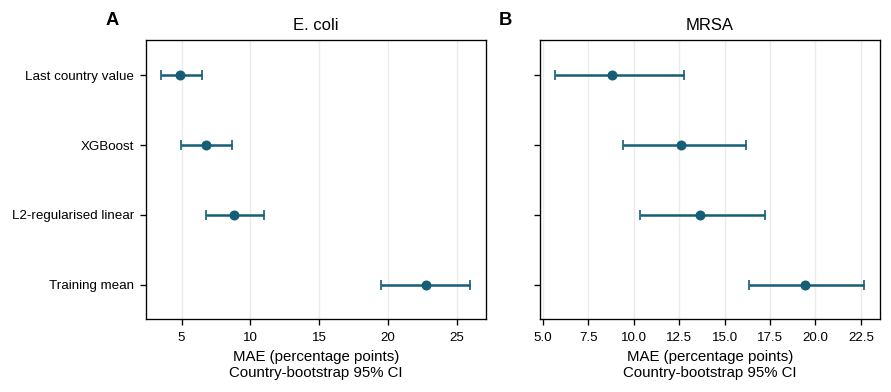

Saved: AMR_analysis_cache/4.0.0/09_publication_figures/Fig2.tif


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



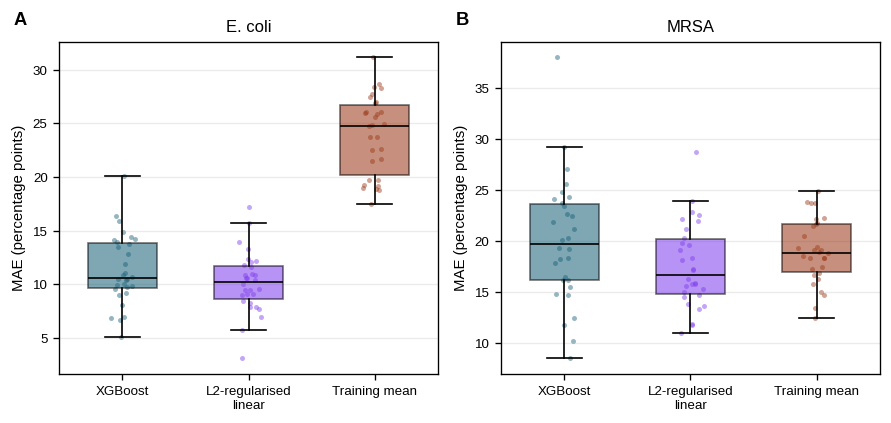

Saved: AMR_analysis_cache/4.0.0/09_publication_figures/Fig3.tif


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



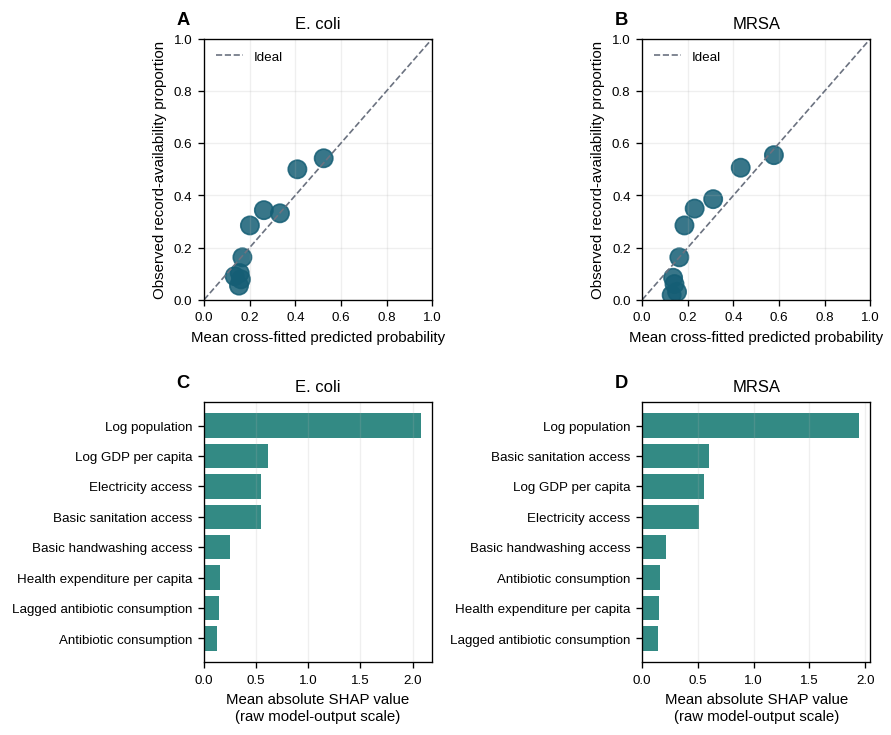

Saved: AMR_analysis_cache/4.0.0/09_publication_figures/Fig4.tif


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



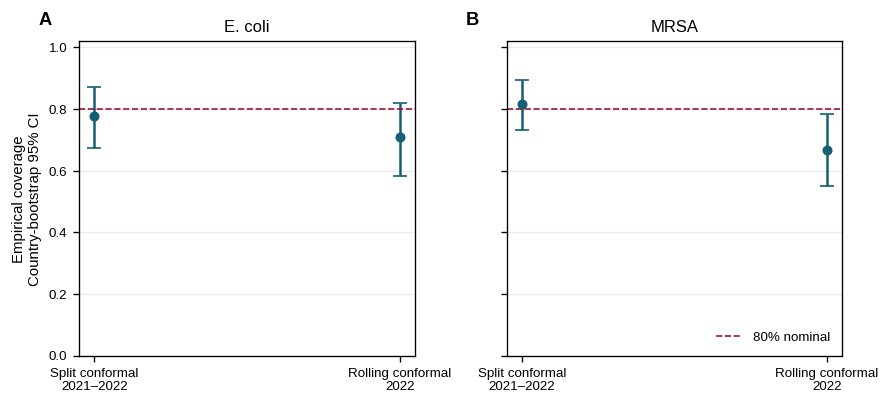

Saved: AMR_analysis_cache/4.0.0/09_publication_figures/S1_ecoli_primary_model_shap_summary.tif


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



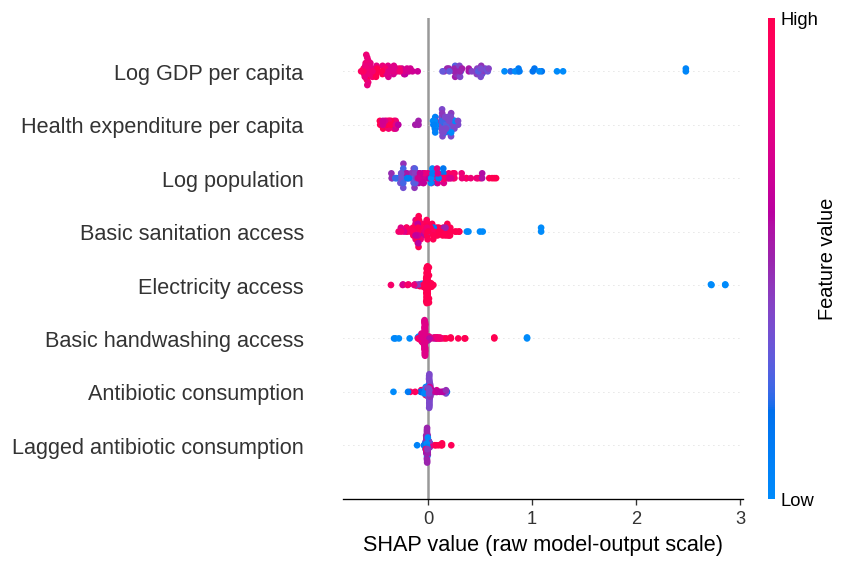

Saved: AMR_analysis_cache/4.0.0/09_publication_figures/S2_mrsa_primary_model_shap_summary.tif


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



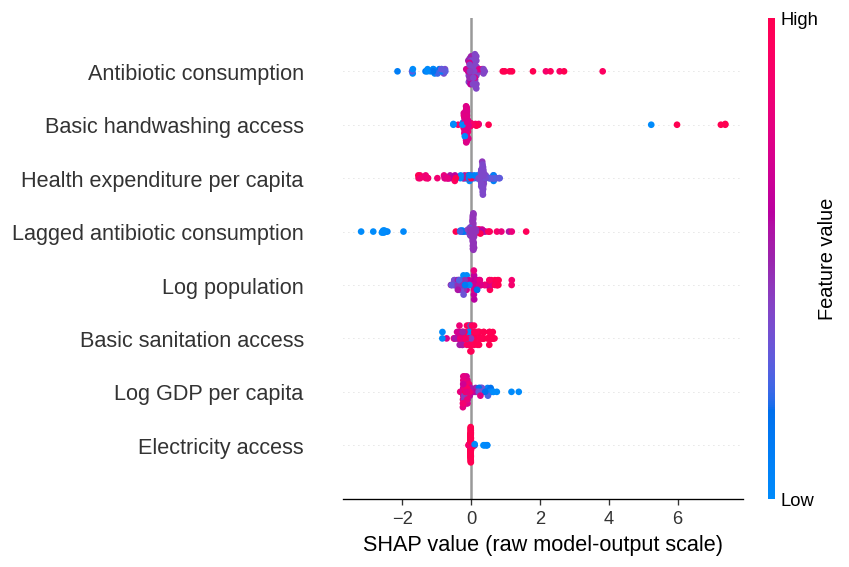

Publication font: Liberation Sans


In [30]:
from matplotlib import font_manager


def choose_publication_font():
    available = {font.name for font in font_manager.fontManager.ttflist}
    for candidate in ["Arial", "Times New Roman", "Liberation Sans", "DejaVu Sans"]:
        if candidate in available:
            return candidate
    return "sans-serif"


PUBLICATION_FONT = choose_publication_font()
plt.rcParams.update({
    "font.family": PUBLICATION_FONT,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "figure.dpi": 120,
})


def panel_label(axis, label):
    axis.text(-0.12, 1.04, label, transform=axis.transAxes, fontsize=11,
              fontweight="bold", va="bottom", ha="left")


def flatten_tiff_rgb(path):
    """Write a single-page RGB TIFF without an alpha channel."""
    path = Path(path)
    with Image.open(path) as picture:
        rgba = picture.convert("RGBA")
        flattened = Image.new("RGB", picture.size, "white")
        flattened.paste(rgba, mask=rgba.getchannel("A"))
    temporary = path.with_suffix(path.suffix + ".tmp")
    flattened.save(temporary, format="TIFF", compression="tiff_lzw", dpi=(600, 600))
    flattened.close()
    os.replace(temporary, path)


def save_plos_tiff(figure, filename):
    path = REV_DIRS["figures"] / filename
    figure.savefig(path, format="tiff", dpi=600, bbox_inches="tight", facecolor="white",
                   pil_kwargs={"compression": "tiff_lzw"})
    flatten_tiff_rgb(path)
    print("Saved:", path)
    return path


model_order = ["Last_country_value", "XGBoost", "L2_regularised_linear", "Training_mean"]
model_labels = {
    "Last_country_value": "Last country value",
    "XGBoost": "XGBoost",
    "L2_regularised_linear": "L2-regularised linear",
    "Training_mean": "Training mean",
}
outcome_labels = OUTCOME_LABELS

# Figure 1: principal temporal comparison.
figure_data = model_bootstrap_summary[
    model_bootstrap_summary["evaluation_window"] == "2021_2022_pooled"
].copy()
figure_data.to_csv(REV_DIRS["figures"] / "Fig1_values.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.35), sharey=True)
for panel, axis, outcome_name in zip("AB", axes, cfg.outcomes):
    subset = figure_data[figure_data["outcome"] == outcome_name].set_index("model").reindex(model_order)
    y_position = np.arange(len(subset))
    point = subset["mae_pp_point"].to_numpy()
    low = subset["mae_pp_ci95_low"].to_numpy()
    high = subset["mae_pp_ci95_high"].to_numpy()
    axis.errorbar(point, y_position, xerr=[point - low, high - point], fmt="o", capsize=3,
                  color="#155e75", markersize=5)
    axis.set_yticks(y_position, [model_labels[name] for name in model_order])
    axis.set_ylim(len(model_order) - 0.5, -0.5)
    axis.set_title(outcome_labels[outcome_name])
    axis.set_xlabel("MAE (percentage points)\nCountry-bootstrap 95% CI")
    axis.grid(axis="x", alpha=0.25)
    panel_label(axis, panel)
fig.tight_layout()
save_plos_tiff(fig, "Fig1.tif")
plt.show()
plt.close(fig)

# Figure 2: grouped-country stress-test distributions across the 30 repeats.
figure_geo = geographic_runs[geographic_runs["model"].isin([
    "XGBoost", "L2_regularised_linear", "Training_mean"
])].copy()
figure_geo.to_csv(REV_DIRS["figures"] / "Fig2_values.csv", index=False)
geo_order = ["XGBoost", "L2_regularised_linear", "Training_mean"]
geo_labels = ["XGBoost", "L2-regularised\nlinear", "Training mean"]
geo_colours = ["#155e75", "#7c3aed", "#9a3412"]
fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.6), sharey=False)
for panel, axis, outcome_name in zip("AB", axes, cfg.outcomes):
    outcome_frame = figure_geo[figure_geo["outcome"] == outcome_name]
    values = [outcome_frame.loc[outcome_frame["model"] == model, "mae_pp"].to_numpy() for model in geo_order]
    boxes = axis.boxplot(values, tick_labels=geo_labels, patch_artist=True, widths=0.55,
                         showfliers=False, medianprops={"color": "black"})
    for patch, colour in zip(boxes["boxes"], geo_colours):
        patch.set_facecolor(colour)
        patch.set_alpha(0.55)
    jitter_rng = np.random.default_rng(100 + list(cfg.outcomes).index(outcome_name))
    for position, (values_one, colour) in enumerate(zip(values, geo_colours), start=1):
        axis.scatter(position + jitter_rng.normal(0, 0.045, len(values_one)), values_one,
                     s=9, alpha=0.45, color=colour, linewidths=0)
    axis.set_title(outcome_labels[outcome_name])
    axis.set_ylabel("MAE (percentage points)")
    axis.grid(axis="y", alpha=0.25)
    panel_label(axis, panel)
fig.tight_layout()
save_plos_tiff(fig, "Fig2.tif")
plt.show()
plt.close(fig)

# Figure 3: outcome-record availability calibration and model-associated importance.
calibration_frames = []
for outcome_name in cfg.outcomes:
    table = pd.read_csv(output_path("selection", f"propensity_calibration__{outcome_name}.csv"))
    calibration_frames.append(table)
availability_calibration_values = pd.concat(calibration_frames, ignore_index=True)
availability_calibration_values.to_csv(REV_DIRS["figures"] / "Fig3_calibration_values.csv", index=False)
reporting_shap_summary.to_csv(REV_DIRS["figures"] / "Fig3_importance_values.csv", index=False)

fig, axes = plt.subplots(2, 2, figsize=(7.5, 6.2))
for column, outcome_name in enumerate(cfg.outcomes):
    calibration = availability_calibration_values[
        availability_calibration_values["outcome"] == outcome_name
    ]
    axis = axes[0, column]
    axis.plot([0, 1], [0, 1], "--", color="#6b7280", linewidth=1, label="Ideal")
    axis.scatter(calibration["mean_predicted"], calibration["observed_rate"],
                 s=np.clip(calibration["n"] * 0.8, 25, 120), color="#155e75", alpha=0.85)
    axis.set_xlim(0, 1)
    axis.set_ylim(0, 1)
    axis.set_xlabel("Mean cross-fitted predicted probability")
    axis.set_ylabel("Observed record-availability proportion")
    axis.set_title(outcome_labels[outcome_name])
    axis.legend(frameon=False, loc="upper left")
    axis.grid(alpha=0.2)
    panel_label(axis, "AB"[column])

    axis = axes[1, column]
    importance = reporting_shap_summary[
        reporting_shap_summary["outcome"] == outcome_name
    ].nlargest(8, "mean_abs_shap").sort_values("mean_abs_shap")
    labels = [FEATURE_LABELS.get(feature, feature) for feature in importance["feature"]]
    axis.barh(labels, importance["mean_abs_shap"], color="#0f766e", alpha=0.85)
    axis.set_xlabel("Mean absolute SHAP value\n(raw model-output scale)")
    axis.set_title(outcome_labels[outcome_name])
    axis.grid(axis="x", alpha=0.2)
    panel_label(axis, "CD"[column])
fig.tight_layout(h_pad=2.0, w_pad=1.2)
save_plos_tiff(fig, "Fig3.tif")
plt.show()
plt.close(fig)

# Figure 4: conformal coverage under the two temporal designs.
coverage_figure_data = conformal_cluster_summary[
    conformal_cluster_summary["evaluation_window"].isin(["2021_2022_pooled", "2022"])
].copy()
coverage_figure_data.to_csv(REV_DIRS["figures"] / "Fig4_values.csv", index=False)
pooled_split = coverage_figure_data[
    (coverage_figure_data["design"] == "split_conformal_80")
    & (coverage_figure_data["evaluation_window"] == "2021_2022_pooled")
].copy()
rolling_2022 = coverage_figure_data[
    (coverage_figure_data["design"] == "rolling_conformal_80")
    & (coverage_figure_data["evaluation_window"] == "2022")
].copy()
coverage_plot = pd.concat([pooled_split, rolling_2022], ignore_index=True)
coverage_plot["label"] = coverage_plot["design"].map({
    "split_conformal_80": "Split conformal\n2021–2022",
    "rolling_conformal_80": "Rolling conformal\n2022",
})
fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.45), sharey=True)
for panel, axis, outcome_name in zip("AB", axes, cfg.outcomes):
    subset = coverage_plot[coverage_plot["outcome"] == outcome_name].reset_index(drop=True)
    x_position = np.arange(len(subset))
    point = subset["empirical_coverage"].to_numpy()
    low = subset["coverage_ci95_low"].to_numpy()
    high = subset["coverage_ci95_high"].to_numpy()
    axis.errorbar(x_position, point, yerr=[point - low, high - point], fmt="o", capsize=4,
                  color="#155e75", markersize=5)
    axis.axhline(0.80, linestyle="--", linewidth=1, color="#9f1239", label="80% nominal")
    axis.set_xticks(x_position, subset["label"])
    axis.set_ylim(0, 1.02)
    axis.set_title(outcome_labels[outcome_name])
    axis.grid(axis="y", alpha=0.25)
    panel_label(axis, panel)
axes[0].set_ylabel("Empirical coverage\nCountry-bootstrap 95% CI")
axes[1].legend(frameon=False, loc="lower right")
fig.tight_layout()
save_plos_tiff(fig, "Fig4.tif")
plt.show()
plt.close(fig)

# Supporting Figures S1 and S2: primary-model SHAP summaries with reader-facing labels.
for outcome_name, filename in [
    ("ecoli_3gc_pct", "S1_ecoli_primary_model_shap_summary.tif"),
    ("mrsa_pct", "S2_mrsa_primary_model_shap_summary.tif"),
]:
    result = main_results[outcome_name]
    X_sample = result["X_test"].sample(n=min(2000, len(result["X_test"])), random_state=SEED)
    explainer = shap.TreeExplainer(result["model"])
    values = explainer.shap_values(X_sample)
    if isinstance(values, list):
        values = values[-1]
    values = np.asarray(values)
    substantive_columns = [column for column in X_sample.columns if not column.endswith("__isna")]
    substantive_indices = [X_sample.columns.get_loc(column) for column in substantive_columns]
    display_frame = X_sample[substantive_columns].rename(columns=FEATURE_LABELS)
    shap_summary_plot(
        values[:, substantive_indices], display_frame,
        feature_names=list(display_frame.columns), show=False, max_display=8, plot_size=(7.2, 4.8)
    )
    shap_figure = plt.gcf()
    shap_figure.set_size_inches(7.2, 4.8)
    plt.xlabel("SHAP value (raw model-output scale)")
    shap_figure.tight_layout()
    save_plos_tiff(shap_figure, filename)
    plt.show()
    plt.close(shap_figure)

print("Publication font:", PUBLICATION_FONT)


Saved: AMR_analysis_cache/4.0.0/09_publication_figures/S3_ecoli_outcome_availability_map.tif


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



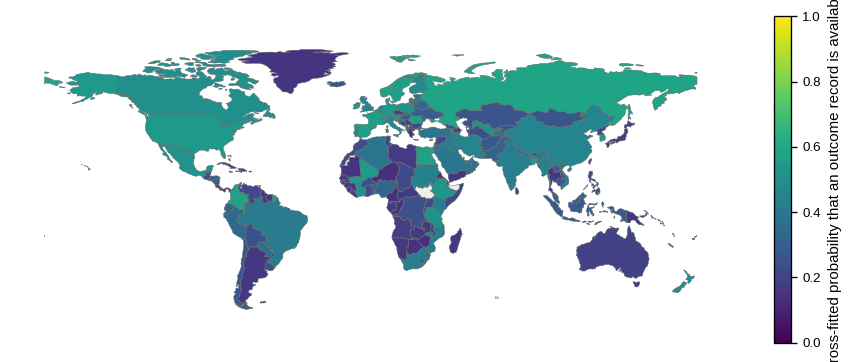

Saved: AMR_analysis_cache/4.0.0/09_publication_figures/S5_ecoli_audit_priority_map.tif


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



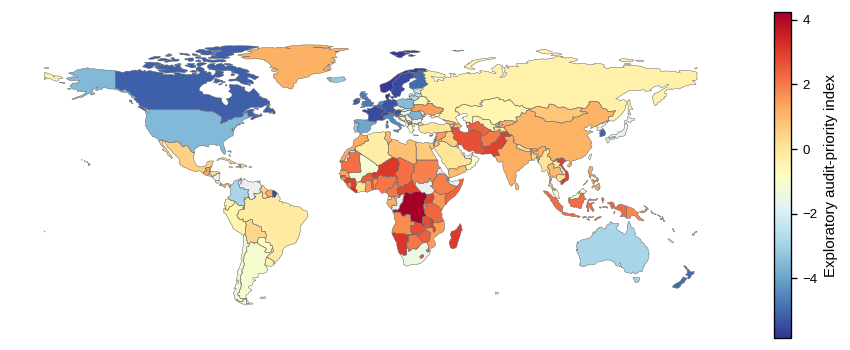

Saved: AMR_analysis_cache/4.0.0/09_publication_figures/S4_mrsa_outcome_availability_map.tif


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



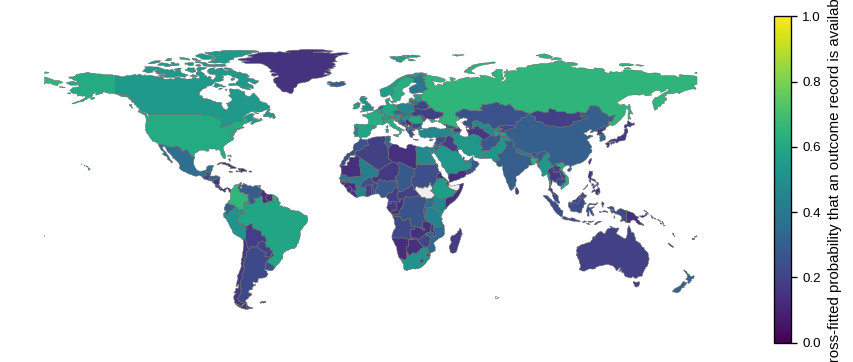

Saved: AMR_analysis_cache/4.0.0/09_publication_figures/S6_mrsa_audit_priority_map.tif


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



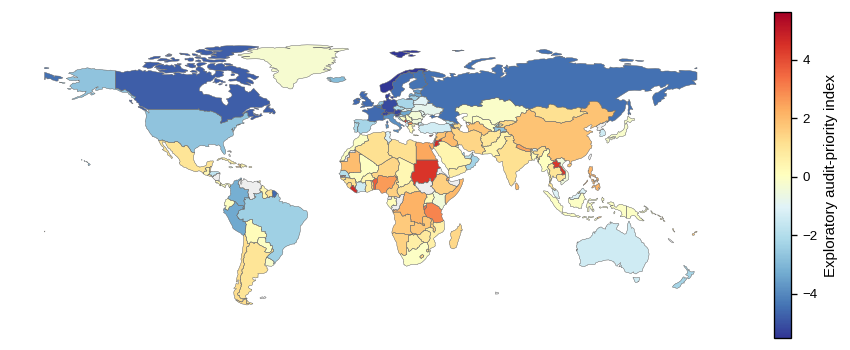

In [31]:
NATURAL_EARTH_ZIP_URL = "https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_countries.zip"
NATURAL_EARTH_TERMS_URL = "https://www.naturalearthdata.com/about/terms-of-use/"
natural_earth_zip = Path(cfg.data_raw_dir) / "ne_110m_admin_0_countries.zip"

try:
    import geopandas as gpd

    if not natural_earth_zip.exists():
        response = requests.get(NATURAL_EARTH_ZIP_URL, timeout=120)
        response.raise_for_status()
        natural_earth_zip.write_bytes(response.content)

    world = gpd.read_file(f"zip://{natural_earth_zip.resolve()}")
    iso_field = next(field for field in ["ADM0_A3", "ISO_A3_EH", "ISO_A3", "SOV_A3"] if field in world.columns)
    world = world.rename(columns={iso_field: "iso3"})
    world = world[world["iso3"] != "ATA"].copy()

    def save_natural_earth_map(values, value_column, filename, legend_label, colour_map="viridis",
                               value_range=None):
        map_frame = world.merge(values[["iso3", value_column]], on="iso3", how="left", validate="many_to_one")
        fig, axis = plt.subplots(figsize=(7.5, 3.8))
        world.boundary.plot(ax=axis, linewidth=0.2, color="#666666")
        plot_kwargs = {
            "column": value_column,
            "ax": axis,
            "cmap": colour_map,
            "legend": True,
            "legend_kwds": {"label": legend_label, "shrink": 0.72},
            "missing_kwds": {"color": "#eeeeee", "label": "No scorable value"},
            "linewidth": 0.15,
            "edgecolor": "#777777",
        }
        if value_range is not None:
            plot_kwargs.update({"vmin": value_range[0], "vmax": value_range[1]})
        map_frame.plot(**plot_kwargs)
        axis.set_axis_off()
        fig.tight_layout(pad=0.1)
        save_plos_tiff(fig, filename)
        plt.show()
        plt.close(fig)

    map_filenames = {
        "ecoli_3gc_pct": {
            "availability": "S3_ecoli_outcome_availability_map.tif",
            "priority": "S5_ecoli_audit_priority_map.tif",
        },
        "mrsa_pct": {
            "availability": "S4_mrsa_outcome_availability_map.tif",
            "priority": "S6_mrsa_audit_priority_map.tif",
        },
    }
    for outcome_name in cfg.outcomes:
        availability = selection_results[outcome_name]["selection"]
        availability = availability[availability["year"] == cfg.priority_year]
        save_natural_earth_map(
            availability, "p_reported_hat", map_filenames[outcome_name]["availability"],
            "Cross-fitted probability that an outcome record is available", value_range=(0, 1),
        )
        priority = priority_panels[outcome_name]
        save_natural_earth_map(
            priority, "priority_index", map_filenames[outcome_name]["priority"],
            "Exploratory audit-priority index", colour_map="RdYlBu_r",
        )

    map_manifest = pd.DataFrame([{
        "boundary_dataset": "Natural Earth Admin 0 - Countries, 1:110m",
        "boundary_download_url": NATURAL_EARTH_ZIP_URL,
        "terms_url": NATURAL_EARTH_TERMS_URL,
        "licence_status": "public domain",
        "cached_file": str(natural_earth_zip),
        "sha256": sha256_file(natural_earth_zip),
    }])
    map_manifest.to_csv(REV_DIRS["figures"] / "map_source_and_licence.csv", index=False)
except ImportError as error:
    raise ImportError(
        "GeoPandas is required for the final Natural Earth map exports. Install the exact "
        "environment recorded by this notebook before the clean run."
    ) from error


## 10. Analysis verification

Checks reconcile row-level predictions with reported metrics, validate each resampling
group, verify country separation and inspect the required figure files. An archive
is created only after all checks pass.


In [32]:
revision_checks = []


def add_check(check, passed, detail=""):
    revision_checks.append({"check": check, "passed": bool(passed), "detail": str(detail)})


def checked_groups(check, frame, group_columns, expected_keys, expected, values):
    try:
        assert_group_replicates(frame, group_columns, expected_keys, expected, values)
        add_check(check, True)
    except (RuntimeError, KeyError, ValueError) as exc:
        add_check(check, False, exc)


for outcome in cfg.outcomes:
    cohort = panel_primary[panel_primary["outcome"] == outcome]
    expected = cohort[cohort["year"] >= cfg.test_year_min][["iso3", "year"]]
    predictions = primary_predictions[primary_predictions["outcome"] == outcome]
    expected_keys = set(expected.itertuples(index=False, name=None))
    prediction_keys = set(predictions[["iso3", "year"]].itertuples(index=False, name=None))
    add_check(f"{outcome}: complete temporal prediction keys",
              prediction_keys == expected_keys and len(predictions) == len(expected))
    add_check(f"{outcome}: finite bounded predictions",
              np.isfinite(predictions[list(MODEL_COLUMNS.values())].to_numpy()).all()
              and predictions[list(MODEL_COLUMNS.values())].ge(0).all().all()
              and predictions[list(MODEL_COLUMNS.values())].le(100).all().all())
    primary = main_results[outcome]["predictions"][["iso3", "year", "y_pred"]]
    aligned = predictions.merge(primary, on=["iso3", "year"], validate="one_to_one")
    add_check(f"{outcome}: primary XGBoost predictions reconciled",
              len(aligned) == len(expected) and np.allclose(aligned["pred_xgboost"], aligned["y_pred"], atol=1e-10, rtol=0))
    for model, column in MODEL_COLUMNS.items():
        measured = metric_triplet(predictions["y_true"], predictions[column])
        reported = temporal_performance[(temporal_performance["cohort"] == "primary_four_year")
            & (temporal_performance["outcome"] == outcome)
            & (temporal_performance["evaluation_window"] == "2021_2022_pooled")
            & (temporal_performance["model"] == model)]
        matching = len(reported) == 1 and all(np.isclose(measured[key], reported.iloc[0][key],
                                                       atol=1e-9, rtol=1e-9) for key in measured)
        add_check(f"{outcome}: {model} metrics recomputed from rows", matching)
    geo = geographic_runs[geographic_runs["outcome"] == outcome]
    geo_pred = geographic_predictions[geographic_predictions["outcome"] == outcome]
    complete_runs = set(geo["run"]) == set(range(rev_cfg.geographic_runs))
    for run in range(rev_cfg.geographic_runs):
        metrics = geo[geo["run"] == run]
        rows = geo_pred[geo_pred["run"] == run]
        if len(metrics) != 3 or set(metrics["model"]) != {"XGBoost", "L2_regularised_linear", "Training_mean"} or not len(rows):
            complete_runs = False
            continue
        heldout = set(json.loads(metrics.iloc[0]["heldout_iso3_json"]))
        intended = cohort[(cohort["year"] >= cfg.test_year_min) & cohort["iso3"].isin(heldout)]
        actual_keys = set(rows[["iso3", "year"]].itertuples(index=False, name=None))
        intended_keys = set(intended[["iso3", "year"]].itertuples(index=False, name=None))
        training = cohort[(cohort["year"] < cfg.test_year_min) & ~cohort["iso3"].isin(heldout)]
        complete_runs &= (actual_keys == intended_keys and len(rows) == len(intended)
                          and not (set(training["iso3"]) & heldout))
        for model, column in {"XGBoost": "pred_xgboost", "L2_regularised_linear": "pred_l2_linear",
                               "Training_mean": "pred_training_mean"}.items():
            measured = metric_triplet(rows["y_true"], rows[column])
            match = metrics[metrics["model"] == model].iloc[0]
            complete_runs &= all(np.isclose(measured[key], match[key], atol=1e-8, rtol=1e-8)
                                 for key in measured)
    add_check(f"{outcome}: all geographic splits and metrics reconciled", complete_runs)
    shap_rows = shap_stability_replicates[shap_stability_replicates["outcome"] == outcome]
    checked_groups(f"{outcome}: every SHAP feature has all refits", shap_rows,
        ["feature"], [(feature,) for feature in BASE_FEATURES], rev_cfg.shap_bootstrap_replicates,
        ["mean_abs_shap_logit", "rank", "mean_abs_approx_effect_pp"])
    folds = xgb_fold_results[xgb_fold_results["outcome"] == outcome]
    grid = xgb_config_results[xgb_config_results["outcome"] == outcome]
    grid_ok = set(grid["parameter_id"]) == {f"cfg_{i:02d}" for i in range(len(XGB_SENSITIVITY_GRID))}
    for parameter in grid["parameter_id"]:
        subset = folds[folds["parameter_id"] == parameter]
        grid_ok &= len(subset) == 5 and set(subset["fold"]) == set(range(1, 6))
    add_check(f"{outcome}: every XGBoost configuration has five CV folds", grid_ok)
    availability = selection_results[outcome]["selection"]
    add_check(f"{outcome}: every availability probability is cross-fitted and finite",
        availability["p_reported_hat"].notna().all() and availability["p_reported_hat"].between(0, 1).all())

checked_groups("all model bootstrap groups complete", model_bootstrap,
    ["outcome", "evaluation_window", "model"],
    product(cfg.outcomes, ["2021", "2022", "2021_2022_pooled"], MODEL_COLUMNS),
    rev_cfg.metric_bootstrap_replicates, ["mae_pp", "rmse_pp"])
checked_groups("all paired bootstrap groups complete", delta_bootstrap,
    ["outcome", "evaluation_window", "comparison"],
    product(cfg.outcomes, ["2021", "2022", "2021_2022_pooled"],
            ["XGBoost_minus_Last_country_value", "XGBoost_minus_L2_regularised_linear"]),
    rev_cfg.metric_bootstrap_replicates, ["delta_mae_pp", "delta_rmse_pp"])
checked_groups("all conformal bootstrap groups complete", conformal_bootstrap,
    ["outcome", "design", "evaluation_window"], expected_conformal_keys,
    rev_cfg.conformal_bootstrap_replicates, ["coverage", "mean_width_pp"])
checked_groups("all availability bootstrap groups complete", availability_bootstrap,
    ["outcome"], [(outcome,) for outcome in cfg.outcomes], AVAILABILITY_BOOTSTRAP_REPLICATES,
    ["roc_auc", "pr_auc", "brier", "calibration_intercept", "calibration_slope"])

split_manifest = pd.DataFrame(CALIBRATION_SPLIT_RECORDS)
add_check("inner calibration partitions keep countries intact", len(split_manifest) == 36 and all(
    not (set(json.loads(row.training_countries_json)) & set(json.loads(row.calibration_countries_json)))
    for row in split_manifest.itertuples()))
outer_manifests = pd.concat([result["folds"] for result in selection_results.values()], ignore_index=True)
add_check("outer availability partitions keep countries intact", len(outer_manifests) == 10 and all(
    not (set(json.loads(row.training_countries_json)) & set(json.loads(row.validation_countries_json)))
    for row in outer_manifests.itertuples()))
add_check("test outcomes not used for XGBoost configuration selection",
          not xgb_selected_summary["test_set_used_for_selection"].any())
valid_history = history_predictions["latest_prior_year"].notna()
add_check("history values precede their target years",
          (history_predictions.loc[valid_history, "latest_prior_year"] < history_predictions.loc[valid_history, "year"]).all())
add_check("observed paired differences exported separately from bootstrap medians",
          delta_bootstrap_summary[["delta_mae_pp_point", "delta_rmse_pp_point", "delta_r2_point"]].notna().all().all())

expected_figure_files = [REV_DIRS["figures"] / name for name in ["Fig1.tif", "Fig2.tif", "Fig3.tif", "Fig4.tif",
    "S1_ecoli_primary_model_shap_summary.tif", "S2_mrsa_primary_model_shap_summary.tif",
    "S3_ecoli_outcome_availability_map.tif", "S4_mrsa_outcome_availability_map.tif",
    "S5_ecoli_audit_priority_map.tif", "S6_mrsa_audit_priority_map.tif"]]
figure_rows = []
for path in expected_figure_files:
    if path.is_file():
        with Image.open(path) as picture:
            dpi = picture.info.get("dpi", (0, 0))
            figure_rows.append({"filename": path.name, "width_px": picture.width, "height_px": picture.height,
                "dpi_x": float(dpi[0]), "dpi_y": float(dpi[1]), "mode": picture.mode,
                "compression_tag": int(picture.tag_v2.get(259, 0)), "pages": int(picture.n_frames),
                "size_bytes": path.stat().st_size})
figure_audit = pd.DataFrame(figure_rows)
figure_audit.to_csv(REV_DIRS["verification"] / "publication_figure_technical_audit.csv", index=False)
add_check("all ten manuscript and supporting TIFFs exist", len(figure_rows) == len(expected_figure_files))
add_check("TIFFs use 600 dpi and LZW compression", len(figure_rows) == len(expected_figure_files)
    and figure_audit["dpi_x"].between(599, 601).all() and figure_audit["dpi_y"].between(599, 601).all()
    and figure_audit["compression_tag"].eq(5).all())
add_check("each TIFF is smaller than 10 MB", len(figure_rows) == len(expected_figure_files)
          and figure_audit["size_bytes"].lt(10_000_000).all())
add_check("TIFFs are RGB or grayscale with no alpha channel and one page",
    len(figure_rows) == len(expected_figure_files)
    and figure_audit["mode"].isin(["RGB", "L"]).all() and figure_audit["pages"].eq(1).all())
add_check("map attribution recorded", (REV_DIRS["figures"] / "map_source_and_licence.csv").is_file())

source_provenance = pd.DataFrame(SOURCE_REGISTRY.values()).sort_values(["dataset_role", "variable_key"]).reset_index(drop=True)
source_manifest_path = REV_DIRS["verification"] / "data_source_manifest.csv"
source_provenance.to_csv(source_manifest_path, index=False)
source_provenance.to_csv(REV_DIRS["verification"] / "source_provenance_and_hashes.csv", index=False)
source_fields = ["variable_key", "dataset_role", "grapher_slug", "url", "unit", "original_provider",
                 "cached_filename", "sha256", "retrieved_utc", "detected_value_column"]
add_check("source manifest covers all nine variables", set(source_provenance["variable_key"]) == set(SOURCE_SPECS))
add_check("source manifest required fields present", source_provenance[source_fields].notna().all().all())
add_check("source CSV hashes match the analysed snapshots", all(
    Path(row.cache_path).is_file() and sha256_file(Path(row.cache_path)) == row.sha256
    for row in source_provenance.itertuples()))

verification = pd.DataFrame(revision_checks)
verification.to_csv(REV_DIRS["verification"] / "revision_verification_checks.csv", index=False)
display(verification)
failures = verification.loc[~verification["passed"]]
if len(failures):
    raise RuntimeError("Analysis checks failed. No archive will be created.\n" + failures.to_string(index=False))
VERIFICATION_COMPLETE = True
VERIFICATION_COMPLETED_UTC = datetime.now(timezone.utc).isoformat()
print(f"{len(verification)} analysis checks passed.")


,check,passed,detail
0,ecoli_3gc_pct: complete temporal prediction keys,True,
1,ecoli_3gc_pct: finite bounded predictions,True,
2,ecoli_3gc_pct: primary XGBoost predictions rec...,True,
3,ecoli_3gc_pct: XGBoost metrics recomputed from...,True,
4,ecoli_3gc_pct: L2_regularised_linear metrics r...,True,
5,ecoli_3gc_pct: Last_country_value metrics reco...,True,
6,ecoli_3gc_pct: Training_mean metrics recompute...,True,
7,ecoli_3gc_pct: all geographic splits and metri...,True,
8,ecoli_3gc_pct: every SHAP feature has all refits,True,
9,ecoli_3gc_pct: every XGBoost configuration has...,True,


39 analysis checks passed.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



## 11. Archive

The archive includes the executed notebook, source snapshots, processed data, results, figures, software versions, licences and file hashes. Automatic Colab export is attempted first. If it is unavailable, download the current executed notebook with **File > Download > Download .ipynb** and select that file when prompted. Outside Colab, set `AMR_NOTEBOOK_PATH` in the environment used to start Jupyter.

In [38]:
import ast
import hashlib
import json

MIT_LICENSE_TEXT = 'MIT License\n\nCopyright (c) 2026 Joel A. W. Chapman and contributors\n\nPermission is hereby granted, free of charge, to any person obtaining a copy\nof this software and associated documentation files (the "Software"), to deal\nin the Software without restriction, including without limitation the rights\nto use, copy, modify, merge, publish, distribute, sublicense, and/or sell\ncopies of the Software, and to permit persons to whom the Software is\nfurnished to do so, subject to the following conditions:\n\nThe above copyright notice and this permission notice shall be included in all\ncopies or substantial portions of the Software.\n\nTHE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR\nIMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,\nFITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE\nAUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER\nLIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,\nOUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE\nSOFTWARE.\n'

DATA_LICENSE_TEXT = "# Data, documentation and figure licences\n\nThe MIT licence in LICENSE_CODE.txt applies to the original analysis code.\nOriginal author-created documentation and graphical content are licensed under\nCreative Commons Attribution 4.0 International (https://creativecommons.org/licenses/by/4.0/).\n\nThird-party source data and their values in processed tables retain the original\nproviders' terms. They are not relicensed by this deposit. Source URLs, providers,\nunits and hashes are recorded in results/08_revision/10_verification/data_source_manifest.csv.\nThe accompanying cached metadata are included in data/source. Consult the source\npages and original provider terms for reuse of those data.\n\nNatural Earth boundaries are public-domain data:\nhttps://www.naturalearthdata.com/about/terms-of-use/.\nThird-party software dependencies retain their own licences.\n"

ARCHIVE_README_TEXT = '# Country-level antimicrobial resistance trustworthiness audit\n\nThis deposit contains a retrospective 2016-2022 country-year analysis of E. coli\nresistance to third-generation cephalosporins and methicillin resistance in S. aureus.\nThe analysis evaluates temporal persistence, geographic transportability,\noutcome-record availability, weighting sensitivity, model explanations and uncertainty.\n\n## Files\n\n- software/AMR_Trustworthiness_PLOS.ipynb: executed analysis notebook.\n- software/requirements-analysis.txt: exact versions of analysis dependencies.\n- software/requirements-environment.txt: complete environment snapshot.\n- software/environment.yml and python-version.txt: Python and environment details.\n- data/source: analysed CSV snapshots, retrieval records and source metadata.\n- results/00_data_audit: processed observed-outcome panels.\n- results/03_reporting_selection: cross-fitted availability panels and split records.\n- results/08_revision: paired comparisons, resampling, sensitivities and figure values.\n- manuscript_values.csv: combined reporting tables, with explicit result-section labels.\n- run_manifest.json, file_manifest.csv and SHA256SUMS.txt: provenance and file integrity.\n- warnings.csv and cache_events.csv: execution warnings and rejected cache records.\n\nThe authoritative temporal predictions are in\nresults/08_revision/01_predictions/primary_unified_predictions.csv. Observed paired\ncontrasts use the *_point columns; bootstrap medians are separate diagnostics.\nConformal inference uses the country-clustered summaries in\nresults/08_revision/05_conformal_dependence. Earlier Wilson intervals are retained\nas descriptive row-level diagnostics and should not replace the clustered intervals.\n\n## Reproduction\n\n1. Create an environment using software/environment.yml, or install the exact\n   requirements-analysis.txt versions with the Python version recorded in python-version.txt.\n2. Place the archived data/source files in a directory named data_raw in the working directory.\n3. Open the notebook in Colab or Jupyter and run the cells in order from a fresh kernel.\n   Outside Colab, set AMR_NOTEBOOK_PATH to the saved, executed notebook before running\n   the archive cell. Colab automatic export has a saved-file fallback.\n4. Require every analysis check to pass. The archive cell refuses to package a notebook\n   with missing analysis executions, out-of-order executions or saved exceptions.\n5. Use manuscript_values.csv and the section-specific result tables for reporting.\n\nEach resampling stratum is checked separately for all requested replicates. Caches\nrequire matching data, source code, Python and package signatures, file hashes,\nrow counts and columns. Checkpoints from earlier analysis versions are not imported.\nThe complete environment snapshot may include Colab-specific packages; the smaller\nanalysis requirements file records the dependencies needed by the analysis itself.\n\n## Interpretation\n\nSame-year estimation is retrospective and is not an operational forecast.\nOutcome-record availability does not measure surveillance quality. SHAP describes\nmodel associations. Conformal coverage is an empirical marginal diagnostic under\nthe analysed temporal design. The audit-priority index is exploratory.\n\nLicences are described in LICENSE_CODE.txt and LICENSES_DATA.md.\n'

if not globals().get("VERIFICATION_COMPLETE", False):
    raise RuntimeError("Run the analysis verification cell before creating archives.")

notebook_document, notebook_export_method = read_current_notebook()
def _amr_source_hash(cells):
    """Encode parsed source without depending on ast.dump formatting defaults."""
    def encode(value):
        if isinstance(value, ast.AST):
            return [type(value).__name__, [
                [name, encode(getattr(value, name, None))]
                for name in value._fields
            ]]
        if isinstance(value, list):
            return [encode(item) for item in value]
        return [type(value).__name__, repr(value)]

    parsed = []
    for cell in cells:
        source = cell.get("source", "")
        source = "".join(source) if isinstance(source, list) else source
        tree = ast.parse(source)
        for node in ast.walk(tree):
            if isinstance(node, ast.Assign) and any(
                isinstance(target, ast.Name) and target.id == "ANALYSIS_SOURCE_SHA256"
                for target in node.targets
            ):
                node.value = ast.Constant(value="SOURCE_HASH")
        parsed.append(encode(tree))
    payload = json.dumps(parsed, ensure_ascii=True, separators=(",", ":"))
    return hashlib.sha256(payload.encode("utf-8")).hexdigest()

export_code_cells = [cell for cell in notebook_document["cells"]
                     if cell.get("cell_type") == "code"]
if len(export_code_cells) != 34:
    raise RuntimeError("Expected 32 analysis cells, one archive cell and one download cell. "
                       "Replace the existing archive cell rather than adding a new cell.")
if not all("analysis" in cell.get("metadata", {}).get("tags", [])
           for cell in export_code_cells[:32]):
    raise RuntimeError("The analysis-cell metadata differ from the completed run.")
EXPECTED_ANALYSIS_CELLS_SHA256 = 'ceadf51fb26035cade6ba935fc2b04e3d5d8dccb92c38b1128685782cf3145e9'
EXPECTED_DOWNLOAD_CELL_SHA256 = 'bfe46a27fc6a8d62a554f16ad3c61979956497ed33a562ab01ccd842e84a4979'
actual_analysis_hash = _amr_source_hash(export_code_cells[:32])
if actual_analysis_hash != EXPECTED_ANALYSIS_CELLS_SHA256:
    raise RuntimeError("Analysis source differs from the completed notebook supplied for this export update. "
                       "Save the current notebook and check that no analysis cells were edited.")
if _amr_source_hash(export_code_cells[-1:]) != EXPECTED_DOWNLOAD_CELL_SHA256:
    raise RuntimeError("The download cell differs from the supplied notebook.")
ARCHIVE_SOURCE_SHA256 = _amr_source_hash(export_code_cells)
ARCHIVE_HASH_METHOD = "canonical_ast_fields_v1"

analysis_cells = [cell for cell in notebook_document["cells"]
                  if cell.get("cell_type") == "code" and "analysis" in cell.get("metadata", {}).get("tags", [])]
run_stamp_present = any(RUN_STARTED_UTC in "".join(
    output.get("text", []) if isinstance(output.get("text", ""), list) else [output.get("text", "")]
) for cell in analysis_cells for output in cell.get("outputs", []))
if not run_stamp_present:
    raise RuntimeError("The exported notebook does not contain this run's start timestamp. Save the current executed notebook and retry.")
counts = [cell.get("execution_count") for cell in analysis_cells]
if not counts or any(not isinstance(count, int) for count in counts) or any(
    current <= previous for previous, current in zip(counts, counts[1:])
):
    raise RuntimeError("The saved analysis cells do not show execution in order. Run all cells in order and save again.")
errors = [output for cell in analysis_cells for output in cell.get("outputs", [])
          if output.get("output_type") == "error"]
if errors:
    raise RuntimeError("The exported notebook contains analysis exception outputs.")

export_dir = Path(os.environ.get("AMR_EXPORT_DIR", "AMR_exports")) / RUN_ID
export_dir.mkdir(parents=True, exist_ok=True)
package_root = export_dir / "AMR_Trustworthiness_Results"
if package_root.exists():
    shutil.rmtree(package_root)
package_root.mkdir()
shutil.copytree(cfg.outputs_dir, package_root / "results")
shutil.copytree(REV_ROOT, package_root / "results" / "08_revision",
    ignore=shutil.ignore_patterns("*.tmp", ".*", "README_REPRODUCTION.md", "revision_run_manifest.json",
                                  "revision_evidence_index.csv", "requirements-lock.txt", "environment.yml"))

source_dir = package_root / "data" / "source"
source_dir.mkdir(parents=True)
for record in SOURCE_REGISTRY.values():
    source = Path(record["cache_path"])
    shutil.copy2(source, source_dir / source.name)
    for candidate in [source.with_suffix(".metadata.json"), source.with_suffix(source.suffix + ".retrieval.json")]:
        if candidate.is_file():
            shutil.copy2(candidate, source_dir / candidate.name)
map_zip = Path(cfg.data_raw_dir) / "ne_110m_admin_0_countries.zip"
if map_zip.is_file():
    shutil.copy2(map_zip, source_dir / map_zip.name)

software_dir = package_root / "software"
software_dir.mkdir()
notebook_document.setdefault("metadata", {}).pop("plos_revision", None)
notebook_document["metadata"]["amr_analysis"] = {
    "version": ANALYSIS_VERSION, "source_sha256": ARCHIVE_SOURCE_SHA256,
    "source_hash_method": ARCHIVE_HASH_METHOD,
    "analysis_cells_sha256": actual_analysis_hash,
    "cache_source_reference_sha256": ANALYSIS_SOURCE_SHA256,
    "analysis_started_utc": RUN_STARTED_UTC, "verification_completed_utc": VERIFICATION_COMPLETED_UTC,
    "checks_passed": int(verification["passed"].sum()), "status": "analysis_complete",
    "notebook_export_method": notebook_export_method,
}
notebook_path = software_dir / "AMR_Trustworthiness_PLOS.ipynb"
atomic_text(notebook_path, json.dumps(notebook_document, indent=1, ensure_ascii=False)+"\n")
notebook_hash = sha256_file(notebook_path)
atomic_text(notebook_path.with_suffix(".ipynb.sha256"), f"{notebook_hash}  {notebook_path.name}\n")

package_versions = {}
for package in ["numpy", "pandas", "scipy", "scikit-learn", "xgboost", "shap", "matplotlib",
                "requests", "plotly", "openpyxl", "geopandas", "pyogrio", "Pillow", "ipython"]:
    try:
        package_versions[package] = importlib_metadata.version(package)
    except importlib_metadata.PackageNotFoundError:
        if package == "xgboost":
            package_versions["xgboost-cpu"] = importlib_metadata.version("xgboost-cpu")
        else:
            raise
core_lock = "".join(f"{package}=={version}\n" for package, version in sorted(package_versions.items()))
atomic_text(software_dir / "requirements-analysis.txt", core_lock)
freeze = subprocess.run([sys.executable, "-m", "pip", "freeze", "--all"], check=True, capture_output=True, text=True)
atomic_text(software_dir / "requirements-environment.txt", freeze.stdout)
atomic_text(software_dir / "package-inventory-lock.txt", PACKAGE_LOCK_TEXT)
atomic_text(software_dir / "python-version.txt", platform.python_version()+"\n")
atomic_text(software_dir / "environment.yml",
    "name: amr-trustworthiness\nchannels:\n  - conda-forge\ndependencies:\n"
    f"  - python={platform.python_version()}\n  - pip\n  - pip:\n"
    + "".join(f"      - {package}=={version}\n" for package, version in sorted(package_versions.items())))

manuscript_frames = []
for section, frame in {
    "cohort_flow": selection_flow, "temporal_performance": temporal_performance,
    "model_bootstrap": model_bootstrap_summary, "paired_differences": delta_bootstrap_summary,
    "geographic_transportability": geographic_summary,
    "availability_performance": selection_summary,
    "availability_uncertainty": availability_bootstrap_summary,
    "ipw_sensitivity": ipw_summary, "shap_stability": shap_stability_summary,
    "shap_rank_agreement": shap_rank_agreement, "conformal": conformal_cluster_summary,
    "conformal_point_performance": conformal_base_metrics,
    "conformal_sample_sizes": conformal_split_counts, "xgb_sensitivity": xgb_selected_summary,
    "history_sensitivity": history_summary, "priority_validation": priority_validation,
    "priority_weights": rank_sensitivity,
}.items():
    copy = frame.copy()
    copy.insert(0, "result_section", section)
    manuscript_frames.append(copy)
manuscript_values = pd.concat(manuscript_frames, ignore_index=True, sort=False)
manuscript_values.to_csv(package_root / "manuscript_values.csv", index=False)
pd.DataFrame(RUN_WARNINGS, columns=["category", "message", "filename", "line"]).to_csv(
    package_root / "warnings.csv", index=False)
pd.DataFrame(CACHE_EVENTS, columns=["path", "event", "reason"]).to_csv(
    package_root / "cache_events.csv", index=False)

atomic_text(package_root / "LICENSE_CODE.txt", MIT_LICENSE_TEXT)
atomic_text(package_root / "LICENSES_DATA.md", DATA_LICENSE_TEXT)
atomic_text(package_root / "README.md", ARCHIVE_README_TEXT)
manifest = {"analysis_version": ANALYSIS_VERSION, "run_id": RUN_ID,
    "started_utc": RUN_STARTED_UTC, "verification_completed_utc": VERIFICATION_COMPLETED_UTC,
    "archive_created_utc": datetime.now(timezone.utc).isoformat(),
    "source_sha256": ARCHIVE_SOURCE_SHA256, "notebook_sha256": notebook_hash,
    "source_hash_method": ARCHIVE_HASH_METHOD,
    "analysis_cells_sha256": actual_analysis_hash,
    "cache_source_reference_sha256": ANALYSIS_SOURCE_SHA256,
    "notebook_export_method": notebook_export_method, "analysis_cell_execution_counts": counts,
    "python": platform.python_version(), "platform": platform.platform(),
    "package_versions": package_versions, "package_inventory_sha256": PACKAGE_LOCK_SHA256,
    "main_config": asdict(cfg), "resampling_config": asdict(rev_cfg),
    "verification_checks": int(len(verification)), "all_checks_passed": True,
    "warning_count": len(RUN_WARNINGS),
    "source_files": list(SOURCE_REGISTRY.values()),
    "hash_index_exclusions": ["SHA256SUMS.txt", "file_manifest.csv"],
}
atomic_text(package_root / "run_manifest.json", json.dumps(manifest, indent=2, default=str)+"\n")

file_rows = [{"path": path.relative_to(package_root).as_posix(), "size_bytes": path.stat().st_size,
              "sha256": sha256_file(path)} for path in sorted(package_root.rglob("*")) if path.is_file()]
file_manifest = pd.DataFrame(file_rows)
file_manifest.to_csv(package_root / "file_manifest.csv", index=False)
atomic_text(package_root / "SHA256SUMS.txt", "".join(f"{row['sha256']}  {row['path']}\n" for row in file_rows))
for row in file_rows:
    if sha256_file(package_root / row["path"]) != row["sha256"]:
        raise RuntimeError(f"File changed during packaging: {row['path']}")

results_zip = Path(shutil.make_archive(str(export_dir / "AMR_Trustworthiness_Results"), "zip", root_dir=package_root))
figures_zip = export_dir / "AMR_Trustworthiness_Figures.zip"
with zipfile.ZipFile(figures_zip, "w", compression=zipfile.ZIP_DEFLATED) as handle:
    for path in sorted((package_root / "results" / "08_revision" / "09_publication_figures").glob("*")):
        if path.is_file() and not path.name.endswith(".meta.json"):
            handle.write(path, arcname=path.name)
    handle.write(package_root / "results" / "08_revision" / "10_verification" / "publication_figure_technical_audit.csv",
                 arcname="figure_technical_audit.csv")

DOWNLOAD_FILES = []
for archive in [results_zip, figures_zip]:
    with zipfile.ZipFile(archive) as handle:
        if handle.testzip() is not None:
            raise RuntimeError(f"Archive integrity check failed: {archive.name}")
    checksum = archive.with_suffix(archive.suffix + ".sha256")
    atomic_text(checksum, f"{sha256_file(archive)}  {archive.name}\n")
    DOWNLOAD_FILES.extend([archive, checksum])
print("Archives created:")
for path in DOWNLOAD_FILES:
    print(path.resolve())
print("Executed notebook:", notebook_path.resolve())
print("Notebook SHA-256:", notebook_hash)
print("Use manuscript_values.csv for the manuscript and supporting tables.")

Archives created:
/content/AMR_exports/20261023T175808/AMR_Trustworthiness_Results.zip
/content/AMR_exports/20261023T175808/AMR_Trustworthiness_Results.zip.sha256
/content/AMR_exports/20261023T175808/AMR_Trustworthiness_Figures.zip
/content/AMR_exports/20261023T175808/AMR_Trustworthiness_Figures.zip.sha256
Executed notebook: /content/AMR_exports/20261023T175808/AMR_Trustworthiness_Results/software/AMR_Trustworthiness_PLOS.ipynb
Notebook SHA-256: d6a993c6b8f048be16fa163f086b1426cbb9d5ff4789891b769627a6a2255b8c
Use manuscript_values.csv for the manuscript and supporting tables.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



## 12. Download

Download the results archive, figures archive and their checksums.

In [39]:
try:
    from google.colab import files
except ImportError:
    for path in DOWNLOAD_FILES:
        display(FileLink(str(path.resolve())))
else:
    for path in DOWNLOAD_FILES:
        files.download(str(path))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>